**PHASE 2**

**DEEPLAB V3+ 3-D WITH CBAM + ASPP**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files in directory: 3119
Valid files (modic 0 or 2): 3095

Split  →  Train: 2166  |  Val: 464  |  Test: 465

Building Train dataset:
  Loaded 2166 samples  |  skipped 0
Building Val dataset:
  Loaded 464 samples  |  skipped 0
Building Test dataset:
  Loaded 465 samples  |  skipped 0
Epoch 01/25  |  Train 3.3460  |  Val 3.1254
  ✔ Saved best model
Epoch 02/25  |  Train 3.1389  |  Val 3.1511
Epoch 03/25  |  Train 3.0271  |  Val 2.8457
  ✔ Saved best model
Epoch 04/25  |  Train 2.8341  |  Val 2.7476
  ✔ Saved best model
Epoch 05/25  |  Train 2.6407  |  Val 2.6563
  ✔ Saved best model
Epoch 06/25  |  Train 2.4269  |  Val 2.7351
Epoch 07/25  |  Train 2.2985  |  Val 2.5381
  ✔ Saved best model
Epoch 08/25  |  Train 2.1206  |  Val 2.4109
  ✔ Saved best model
Epoch 09/25  |  Train 1.9104  |  Val 2.2964
  ✔ Saved best model
Epoch 10/25  |  Train 1.7060  |  Val 2.3297
Epoch 11/25  |  Train 1.5589  |  Val 2.1755
  ✔ Saved best model
Epoch 12

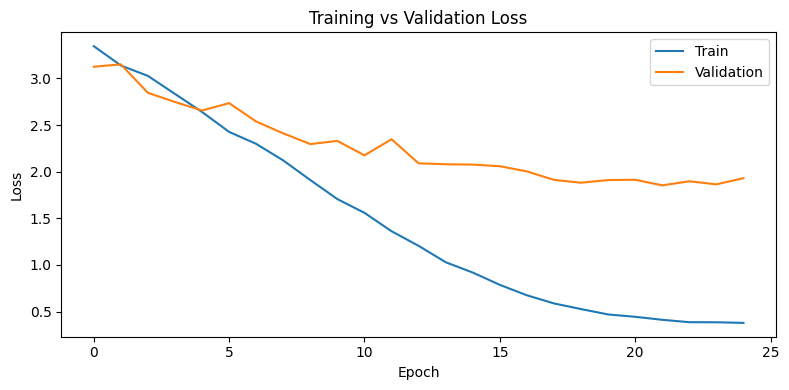


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.9085    0.8963    0.9024       299
     Modic 2     0.8166    0.8364    0.8263       165

    accuracy                         0.8750       464
   macro avg     0.8625    0.8663    0.8644       464
weighted avg     0.8758    0.8750    0.8753       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.8519    0.6133    0.7132        75
          P2     0.7317    0.6742    0.7018        89
          P3     0.6158    0.7899    0.6921       138
          P4     0.6354    0.6162    0.6256        99
          P5     0.7273    0.6349    0.6780        63

    accuracy                         0.6810       464
   macro avg     0.7124    0.6657    0.6821       464
weighted avg     0.6955    0.6810    0.6812       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.9118    0.8341    0.8712       223
         

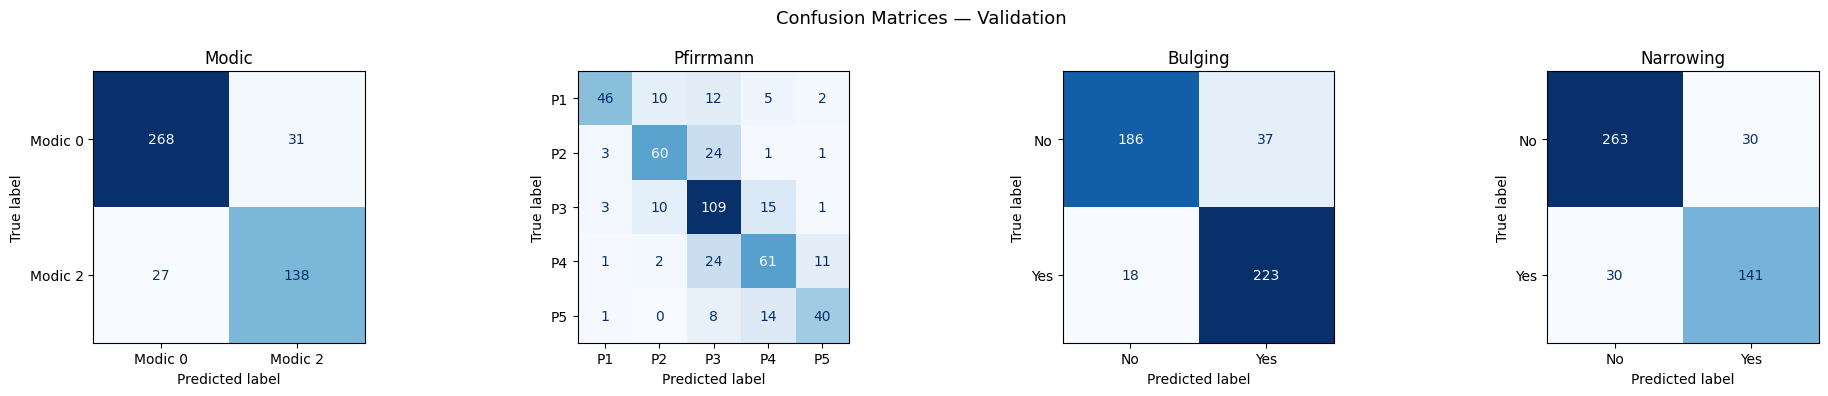

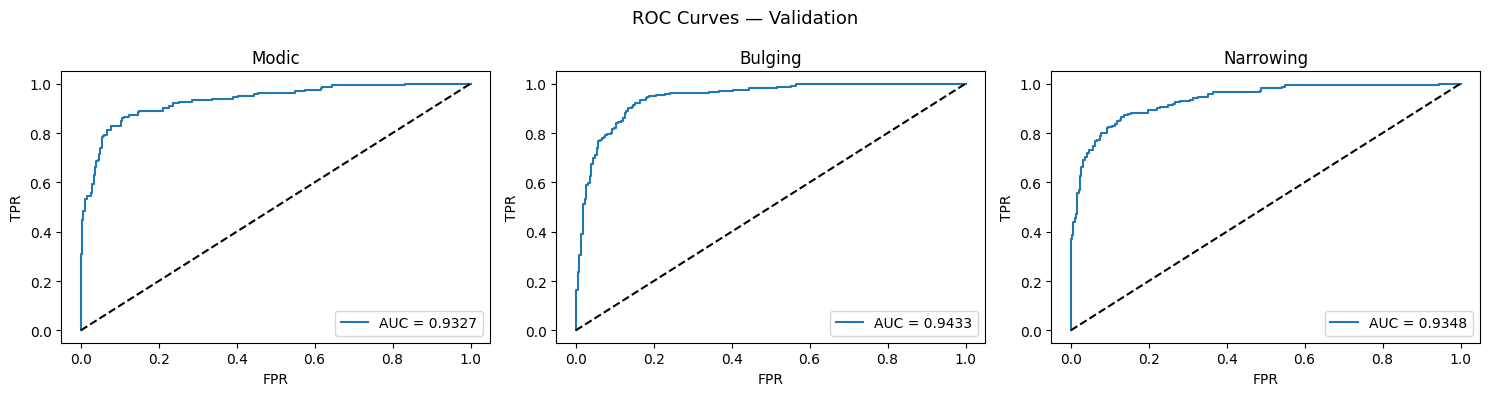


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.9122    0.9030    0.9076       299
     Modic 2     0.8284    0.8434    0.8358       166

    accuracy                         0.8817       465
   macro avg     0.8703    0.8732    0.8717       465
weighted avg     0.8823    0.8817    0.8820       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.8654    0.6429    0.7377        70
          P2     0.7340    0.6000    0.6603       115
          P3     0.5594    0.8309    0.6686       136
          P4     0.6824    0.6444    0.6629        90
          P5     0.7812    0.4630    0.5814        54

    accuracy                         0.6667       465
   macro avg     0.7245    0.6362    0.6622       465
weighted avg     0.6982    0.6667    0.6657       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9062    0.8529    0.8788       238
         Yes     0.8548    

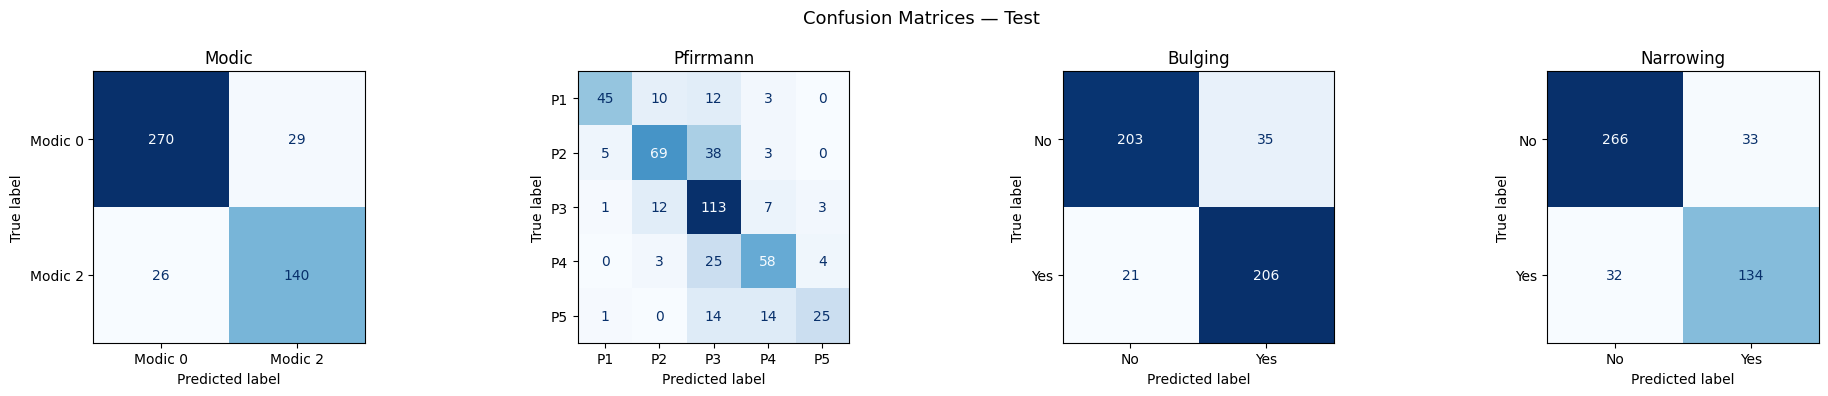

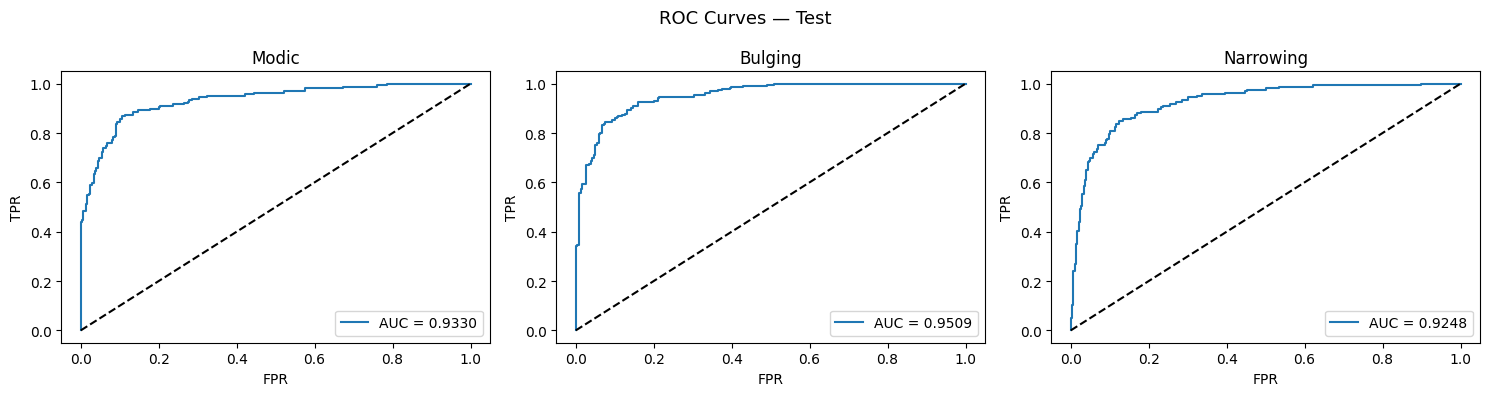

In [3]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# =========================================================
# CUDA ERROR VISIBILITY
# =========================================================
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
os.environ["TORCH_USE_CUDA_DSA"]   = "1"

# =========================================================
# SEED + DEVICE
# =========================================================
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# =========================================================
# CONFIG
# =========================================================
DATA_DIR      = "/kaggle/input/datasets/kiranps24/lumbar-spine-disclevel/disc_samples_final_v2"
TARGET_SHAPE  = (32, 128, 128)
BATCH_SIZE    = 4
EPOCHS        = 25
LR            = 1e-4
PATIENCE      = 5

# =========================================================
# DATASET
# =========================================================
class DiscDataset(Dataset):
    """
    Each .npz contains:
        image  : 3-D MRI volume
        labels : dict with keys modic, pfirrmann, bulging, narrowing

    Only modic == 0 or modic == 2 samples are kept.
    modic is remapped → 0 (was 0) / 1 (was 2).
    pfirrmann is 1-indexed so we subtract 1 → 0-based class index.
    """
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []

        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] Could not load {f}: {e}")
                skipped += 1

        print(f"  Loaded {len(self.files)} samples  |  skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"], dtype=torch.float32).unsqueeze(0)  # (1,D,H,W)

        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0),
            size=self.target_shape,
            mode="trilinear",
            align_corners=False
        ).squeeze(0)                                                            # (1,D,H,W)

        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels = data["labels"].item()

        modic_raw   = int(labels["modic"])
        pfirrmann   = int(labels["pfirrmann"]) - 1   # 1–5  →  0–4
        bulging     = float(labels["bulging"])
        narrowing   = float(labels["narrowing"])

        # Safety clamps
        pfirrmann = max(0, min(pfirrmann, 4))

        targets = {
            "modic":     torch.tensor(0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann,                   dtype=torch.long),
            "bulging":   torch.tensor(bulging,                     dtype=torch.float32),
            "narrowing": torch.tensor(narrowing,                   dtype=torch.float32),
        }

        return image, targets


# =========================================================
# 70 / 15 / 15 SPLIT  (file-level, stratified on modic)
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR)
    if f.endswith(".npz")
])
print(f"Total .npz files in directory: {len(all_files)}")

# Collect modic labels for stratification
labels_for_split = []
valid_files      = []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

# Stratified split using sklearn
from sklearn.model_selection import train_test_split

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files,
    test_size=0.50, stratify=temp_labels, random_state=42
)

print(f"\nSplit  →  Train: {len(train_files)}  |  Val: {len(val_files)}  |  Test: {len(test_files)}")

# =========================================================
# DATASETS & LOADERS
# =========================================================
print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

# =========================================================
# CBAM 3-D ATTENTION
# =========================================================
class CBAM3D(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels, max(1, channels // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, channels // reduction), channels)
        )
        self.spatial_conv = nn.Conv3d(2, 1, kernel_size=7, padding=3, bias=False)

    def forward(self, x):
        B, C, D, H, W = x.shape

        # Channel attention
        avg_c = F.adaptive_avg_pool3d(x, 1).view(B, C)
        max_c = F.adaptive_max_pool3d(x, 1).view(B, C)
        ch_att = torch.sigmoid(
            self.channel_mlp(avg_c) + self.channel_mlp(max_c)
        ).view(B, C, 1, 1, 1)
        x = x * ch_att

        # Spatial attention
        avg_s = torch.mean(x, dim=1, keepdim=True)
        max_s, _ = torch.max(x, dim=1, keepdim=True)
        sp_att = torch.sigmoid(
            self.spatial_conv(torch.cat([avg_s, max_s], dim=1))
        )
        x = x * sp_att
        return x


# =========================================================
# ASPP 3-D
# =========================================================
class ASPP3D(nn.Module):
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv3d(in_ch, out_ch, 1, bias=False),
                                 nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b2 = nn.Sequential(nn.Conv3d(in_ch, out_ch, 3, padding=6,  dilation=6,  bias=False),
                                 nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b3 = nn.Sequential(nn.Conv3d(in_ch, out_ch, 3, padding=12, dilation=12, bias=False),
                                 nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b4 = nn.Sequential(nn.Conv3d(in_ch, out_ch, 3, padding=18, dilation=18, bias=False),
                                 nn.BatchNorm3d(out_ch), nn.ReLU())
        self.project = nn.Sequential(
            nn.Conv3d(out_ch * 4, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(),
            nn.Dropout3d(0.1)
        )

    def forward(self, x):
        return self.project(torch.cat([
            self.b1(x), self.b2(x), self.b3(x), self.b4(x)
        ], dim=1))


# =========================================================
# DEEPLAB V3+ 3-D WITH CBAM + ASPP
# =========================================================
class DeepLabV3Plus3D_Attn(nn.Module):
    def __init__(self):
        super().__init__()

        def conv_bn_relu(in_ch, out_ch, stride=1):
            return nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
                nn.BatchNorm3d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.encoder = nn.Sequential(
            conv_bn_relu(1,   64,  stride=2),
            conv_bn_relu(64,  128, stride=2),
            conv_bn_relu(128, 256, stride=2),
            conv_bn_relu(256, 512, stride=2),
        )

        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        # Task heads
        self.head_modic     = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging   = nn.Sequential(nn.Linear(256, 64),  nn.ReLU(), nn.Linear(64,  1))
        self.head_narrowing = nn.Sequential(nn.Linear(256, 64),  nn.ReLU(), nn.Linear(64,  1))

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    l_modic     = ce(out["modic"],     tgt["modic"])
    l_pfirrmann = ce(out["pfirrmann"], tgt["pfirrmann"])
    l_bulging   = bce(out["bulging"],  tgt["bulging"])
    l_narrowing = bce(out["narrowing"],tgt["narrowing"])
    return l_modic + l_pfirrmann + l_bulging + l_narrowing


# =========================================================
# TRAIN / EVAL LOOP
# =========================================================
model     = DeepLabV3Plus3D_Attn().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=torch.cuda.is_available())


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}

            if train:
                optimizer.zero_grad()

            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total += loss.item()

    return total / max(len(loader), 1)


# =========================================================
# TRAINING LOOP
# =========================================================
train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()

    train_losses.append(tr)
    val_losses.append(vl)

    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  Train {tr:.4f}  |  Val {vl:.4f}")

    if vl < best_val:
        best_val = vl
        counter  = 0
        torch.save(model.state_dict(), "best_deeplab_attn.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping triggered.")
            break


# =========================================================
# LOSS CURVE
# =========================================================
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION FUNCTION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(torch.load("best_deeplab_attn.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            # Modic
            p_modic = torch.softmax(out["modic"], dim=1)[:, 1]
            probs["modic"].extend(p_modic.cpu().numpy())
            preds["modic"].extend(out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            # Pfirrmann
            preds["pfirrmann"].extend(out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            # Bulging
            p_bul = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_bul.cpu().numpy())
            preds["bulging"].extend((p_bul > 0.5).long().cpu().numpy())
            gts["bulging"].extend(tgt["bulging"].long().numpy())

            # Narrowing
            p_nar = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_nar.cpu().numpy())
            preds["narrowing"].extend((p_nar > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(tgt["narrowing"].long().numpy())

    # ---- Classification Reports ----
    task_labels = {
        "modic":     (["Modic 0", "Modic 2"], f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)], f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"], f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"], f"\nNARROWING — {split_name}"),
    }

    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used_names = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task],
            labels=present, target_names=used_names, digits=4, zero_division=0
        ))

    # ---- Confusion Matrices ----
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}", fontsize=13)

    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        cm = confusion_matrix(gts[task], preds[task])
        present = sorted(set(gts[task]))
        used_names = [names[i] for i in present if i < len(names)]
        disp = ConfusionMatrixDisplay(cm, display_labels=used_names)
        disp.plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())

    plt.tight_layout(); plt.show()

    # ---- ROC Curves ----
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}", fontsize=13)

    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])

        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (only 1 class in split)")
            continue

        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()

    plt.tight_layout(); plt.show()


# =========================================================
# RUN EVALUATION ON VAL + TEST
# =========================================================
evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**BIANQUENET 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
GPU memory: 17.1 GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095
Split → Train: 2166 | Val: 464 | Test: 465

Building Train dataset:
  Loaded 2166 samples  |  skipped 0
Building Val dataset:
  Loaded 464 samples  |  skipped 0
Building Test dataset:
  Loaded 465 samples  |  skipped 0

BianqueNet3D  —  trainable params: 7,383,466
Shape check passed: {'modic': (1, 2), 'pfirrmann': (1, 5), 'bulging': (1,), 'narrowing': (1,)}
Epoch 01/25  |  Train 3.4605  |  Val 3.1846  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 02/25  |  Train 3.1907  |  Val 3.0197  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 03/25  |  Train 2.8164  |  Val 2.7676  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 04/25  |  Train 2.4122  |  Val 2.7402  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 05/25  |  Train 2.0734  |  Val 2.6285  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 06/25  |  Train 1.7947  |  Val 2.4785  |  GPU: 0.4 GB
  ✔ Saved best model
Epoch 07/25  |  Train 1.5635  |  

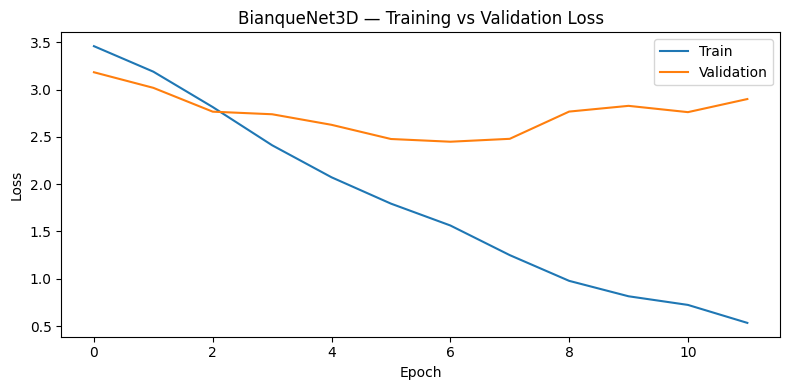


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8441    0.8328    0.8384       299
     Modic 2     0.7041    0.7212    0.7126       165

    accuracy                         0.7931       464
   macro avg     0.7741    0.7770    0.7755       464
weighted avg     0.7943    0.7931    0.7936       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.7059    0.4800    0.5714        75
          P2     0.5316    0.4719    0.5000        89
          P3     0.5078    0.4710    0.4887       138
          P4     0.4024    0.6667    0.5019        99
          P5     0.6667    0.4444    0.5333        63

    accuracy                         0.5108       464
   macro avg     0.5629    0.5068    0.5191       464
weighted avg     0.5435    0.5108    0.5131       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8522    0.7758    0.8122       223
         

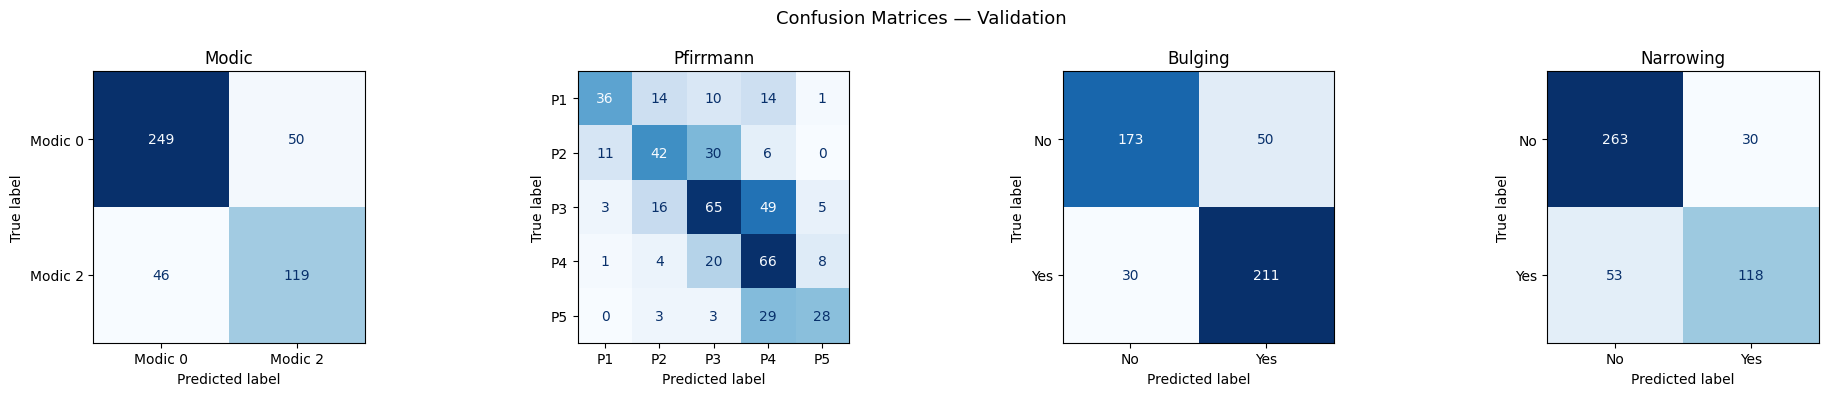

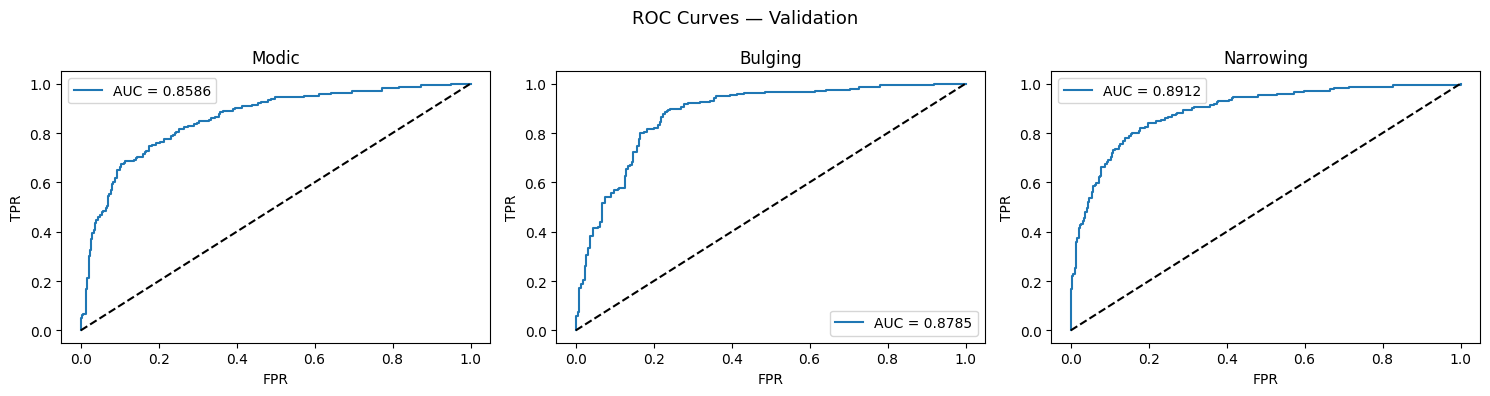


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8383    0.8495    0.8439       299
     Modic 2     0.7222    0.7048    0.7134       166

    accuracy                         0.7978       465
   macro avg     0.7803    0.7772    0.7786       465
weighted avg     0.7969    0.7978    0.7973       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.6250    0.5714    0.5970        70
          P2     0.5926    0.4174    0.4898       115
          P3     0.5306    0.5735    0.5512       136
          P4     0.3973    0.6444    0.4915        90
          P5     0.6667    0.3333    0.4444        54

    accuracy                         0.5204       465
   macro avg     0.5624    0.5080    0.5148       465
weighted avg     0.5501    0.5204    0.5190       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8540    0.8109    0.8319       238
         Yes     0.8117    

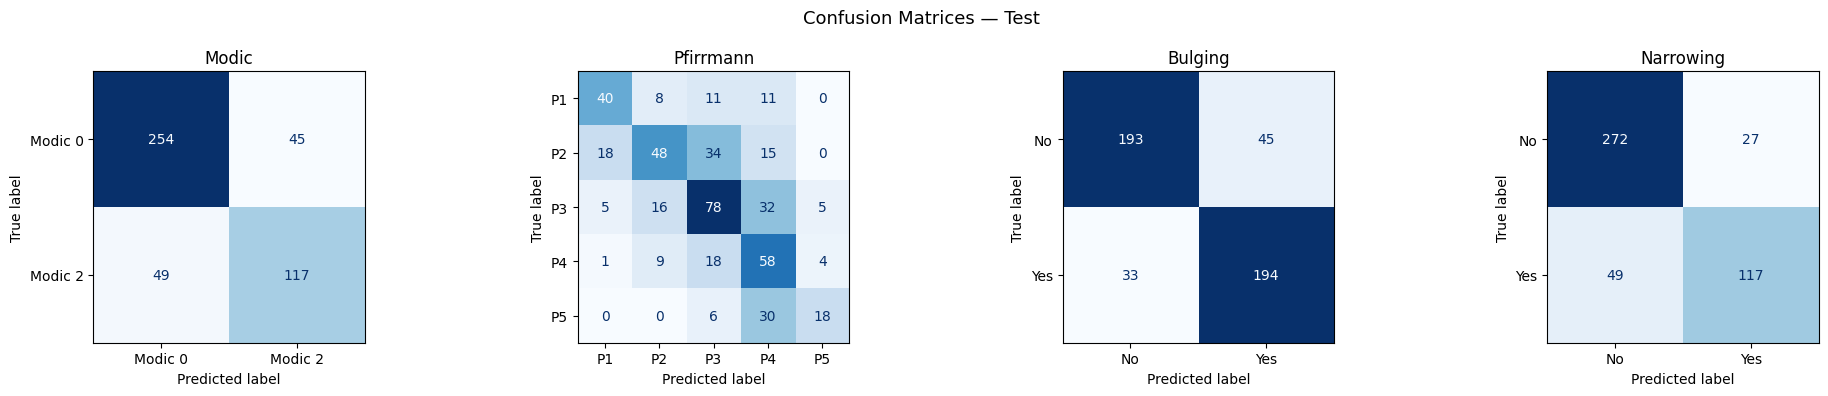

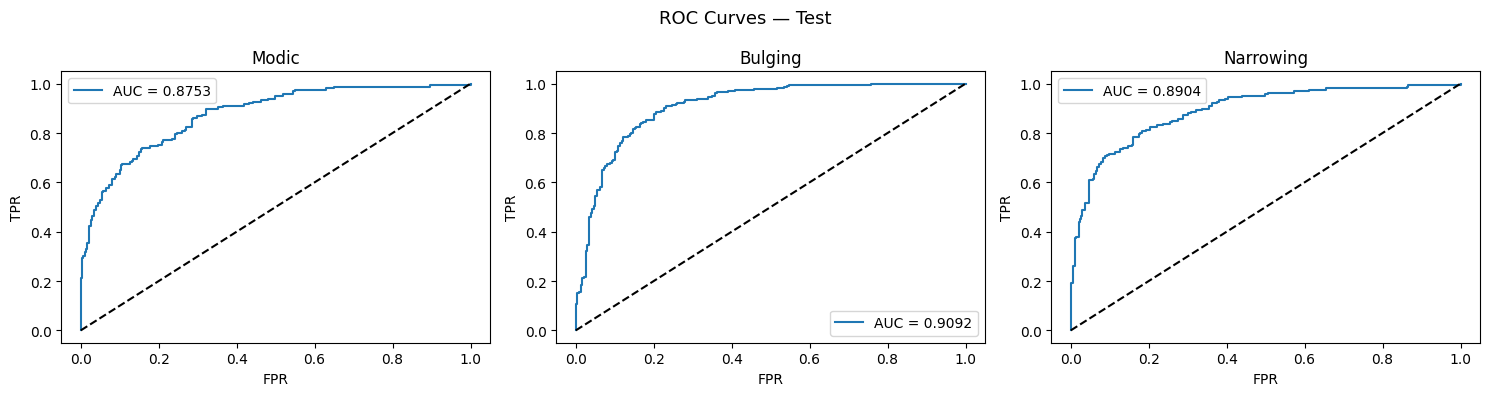

In [4]:
import os
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)
from sklearn.model_selection import train_test_split

# =========================================================
# MEMORY + CUDA CONFIG
# =========================================================
os.environ["CUDA_LAUNCH_BLOCKING"]    = "1"
os.environ["TORCH_USE_CUDA_DSA"]      = "1"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# =========================================================
# SEED + DEVICE
# =========================================================
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# =========================================================
# CONFIG
# =========================================================
DATA_DIR     = "/kaggle/input/datasets/kiranps24/lumbar-spine-disclevel/disc_samples_final_v2"
TARGET_SHAPE = (16, 64, 64)   # (D, H, W) — fits P100 16 GB
BATCH_SIZE   = 2
GRAD_ACCUM   = 4              # effective batch = 8
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] Could not load {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples  |  skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"], dtype=torch.float32).unsqueeze(0)

        image = F.interpolate(
            image.unsqueeze(0),
            size=self.target_shape,
            mode="trilinear",
            align_corners=False
        ).squeeze(0)

        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))
        bulging   = float(labels["bulging"])
        narrowing = float(labels["narrowing"])

        targets = {
            "modic":     torch.tensor(0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann,                   dtype=torch.long),
            "bulging":   torch.tensor(bulging,                     dtype=torch.float32),
            "narrowing": torch.tensor(narrowing,                   dtype=torch.float32),
        }
        return image, targets


# =========================================================
# 70 / 15 / 15 STRATIFIED SPLIT
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50, stratify=temp_labels, random_state=42
)
print(f"Split → Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")

# =========================================================
# DATALOADERS
# =========================================================
print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)


# =========================================================
# BIANQUENET 3D
# =========================================================
# BianqueNet is a dual-branch architecture (published for spine MRI)
# that runs a CNN branch and a Transformer branch in parallel,
# fuses them with cross-attention, then passes the fused
# representation to task heads.
#
# Paper: "BianqueNet: Dual-Branch Network with Dual-Sampling for
#         Spine MRI Analysis"  (adapted to 3-D here)
#
# Structure:
#   Branch 1 — CNN (ResNet-style encoder, local features)
#   Branch 2 — Transformer (global context via self-attention)
#   Cross-Attention Fusion — CNN queries Transformer context
#   Multi-task heads
# =========================================================

# ----------------------------------------------------------
# BRANCH 1 — CNN  (3-D ResNet-style)
# ----------------------------------------------------------
class ResBlock3D(nn.Module):
    """Standard pre-activation 3-D residual block."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                               padding=1, bias=False)
        self.bn1   = nn.BatchNorm3d(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm3d(out_ch)
        self.relu  = nn.ReLU(inplace=True)

        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm3d(out_ch)
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample:
            identity = self.downsample(x)
        return self.relu(out + identity)


class CNNBranch3D(nn.Module):
    """
    4-stage encoder: 1 → 32 → 64 → 128 → 256 channels
    Each stage halves spatial dims with stride=2.
    Output: (B, 256, D/16, H/16, W/16)
    Then global avg-pool → (B, 256)
    """
    def __init__(self, in_ch=1):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True)
        )
        self.stage1 = ResBlock3D(32,  64,  stride=2)
        self.stage2 = ResBlock3D(64,  128, stride=2)
        self.stage3 = ResBlock3D(128, 256, stride=2)
        self.pool   = nn.AdaptiveAvgPool3d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.pool(x).flatten(1)   # (B, 256)


# ----------------------------------------------------------
# BRANCH 2 — Lightweight Transformer  (global context)
# ----------------------------------------------------------
class PatchTokenizer3D(nn.Module):
    """
    Splits volume into non-overlapping patches and projects to tokens.
    Input : (B, 1, D, H, W)
    Output: (B, N, embed_dim)   where N = (D/pd)*(H/ph)*(W/pw)
    """
    def __init__(self, patch_size=(4, 8, 8), embed_dim=256):
        super().__init__()
        self.proj = nn.Conv3d(1, embed_dim,
                              kernel_size=patch_size, stride=patch_size)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)                      # (B, C, D', H', W')
        B, C, D, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)      # (B, N, C)
        return self.norm(x)


class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads=8, mlp_ratio=4., drop=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = nn.MultiheadAttention(dim, num_heads,
                                           dropout=drop, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hid = int(dim * mlp_ratio)
        self.mlp   = nn.Sequential(
            nn.Linear(dim, hid), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hid, dim), nn.Dropout(drop)
        )

    def forward(self, x):
        # Self-attention with pre-norm
        x_norm = self.norm1(x)
        attn_out, _ = self.attn(x_norm, x_norm, x_norm)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x


class TransformerBranch3D(nn.Module):
    """
    Tokenise → 4 Transformer blocks → CLS-style global token (mean).
    Output: (B, 256)
    """
    def __init__(self, patch_size=(4, 8, 8), embed_dim=256,
                 num_heads=8, depth=4, drop=0.1):
        super().__init__()
        self.tokenizer = PatchTokenizer3D(patch_size, embed_dim)
        self.blocks    = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, drop=drop)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.tokenizer(x)          # (B, N, 256)
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x).mean(dim=1)   # global avg over tokens → (B, 256)
        return x


# ----------------------------------------------------------
# CROSS-ATTENTION FUSION MODULE
# ----------------------------------------------------------
class CrossAttentionFusion(nn.Module):
    """
    CNN features act as Query, Transformer features as Key/Value.
    Fuses local (CNN) + global (Transformer) representations.
    Input : cnn_feat (B, 256), trx_feat (B, 256)
    Output: fused    (B, 256)
    """
    def __init__(self, dim=256, num_heads=8, drop=0.1):
        super().__init__()
        self.norm_q  = nn.LayerNorm(dim)
        self.norm_kv = nn.LayerNorm(dim)
        self.attn    = nn.MultiheadAttention(dim, num_heads,
                                             dropout=drop, batch_first=True)
        self.norm_out = nn.LayerNorm(dim)
        self.ffn      = nn.Sequential(
            nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(drop),
            nn.Linear(dim * 2, dim), nn.Dropout(drop)
        )
        self.gate = nn.Parameter(torch.tensor(0.5))   # learnable fusion gate

    def forward(self, cnn_feat, trx_feat):
        # Reshape to sequence of 1 token each for cross-attention
        q  = self.norm_q(cnn_feat).unsqueeze(1)    # (B, 1, 256)
        kv = self.norm_kv(trx_feat).unsqueeze(1)   # (B, 1, 256)

        attn_out, _ = self.attn(q, kv, kv)         # (B, 1, 256)
        attn_out    = attn_out.squeeze(1)           # (B, 256)

        # Residual + FFN
        fused = cnn_feat + attn_out
        fused = fused + self.ffn(self.norm_out(fused))

        # Learnable gate between CNN and fused representation
        return torch.sigmoid(self.gate) * fused + \
               (1 - torch.sigmoid(self.gate)) * trx_feat


# ----------------------------------------------------------
# FULL BIANQUENET 3D
# ----------------------------------------------------------
class BianqueNet3D(nn.Module):
    """
    Dual-branch 3-D network for multi-task spine disc classification.

    CNN branch    — captures local texture / shape features
    Trans branch  — captures global disc neighbourhood context
    Cross-attn    — fuses both representations
    Task heads    — modic / pfirrmann / bulging / narrowing
    """
    def __init__(self, feat_dim=256, drop=0.1):
        super().__init__()
        self.cnn_branch = CNNBranch3D(in_ch=1)
        self.trx_branch = TransformerBranch3D(
            patch_size=(4, 8, 8),
            embed_dim=feat_dim,
            num_heads=8,
            depth=4,
            drop=drop
        )
        self.fusion  = CrossAttentionFusion(dim=feat_dim, num_heads=8, drop=drop)
        self.dropout = nn.Dropout(drop)

        # Task-specific heads
        self.head_modic     = nn.Sequential(
            nn.Linear(feat_dim, 128), nn.GELU(), nn.Dropout(drop),
            nn.Linear(128, 2)
        )
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(feat_dim, 128), nn.GELU(), nn.Dropout(drop),
            nn.Linear(128, 5)
        )
        self.head_bulging   = nn.Sequential(
            nn.Linear(feat_dim, 64), nn.GELU(), nn.Dropout(drop),
            nn.Linear(64, 1)
        )
        self.head_narrowing = nn.Sequential(
            nn.Linear(feat_dim, 64), nn.GELU(), nn.Dropout(drop),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        cnn_feat = self.cnn_branch(x)       # (B, 256)
        trx_feat = self.trx_branch(x)       # (B, 256)
        fused    = self.fusion(cnn_feat, trx_feat)  # (B, 256)
        fused    = self.dropout(fused)

        return {
            "modic":     self.head_modic(fused),
            "pfirrmann": self.head_pfirrmann(fused),
            "bulging":   self.head_bulging(fused).squeeze(1),
            "narrowing": self.head_narrowing(fused).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce(out["modic"],      tgt["modic"])     +
        ce(out["pfirrmann"],  tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# MODEL + OPTIMISER
# =========================================================
model     = BianqueNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=torch.cuda.is_available())

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nBianqueNet3D  —  trainable params: {total_params:,}")

# Shape sanity check
with torch.no_grad():
    dummy = torch.zeros(1, 1, *TARGET_SHAPE).to(device)
    out_  = model(dummy)
    print("Shape check passed:", {k: tuple(v.shape) for k, v in out_.items()})
del dummy, out_
torch.cuda.empty_cache()


# =========================================================
# TRAIN / EVAL  (gradient accumulation)
# =========================================================
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        optimizer.zero_grad()
        for step, (img, tgt) in enumerate(loader):
            img = img.to(device, non_blocking=True)
            tgt = {k: v.to(device, non_blocking=True) for k, v in tgt.items()}

            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
                if train:
                    loss = loss / GRAD_ACCUM

            if train:
                scaler.scale(loss).backward()
                if (step + 1) % GRAD_ACCUM == 0 or (step + 1) == len(loader):
                    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad()

            total += loss.item() * (GRAD_ACCUM if train else 1)

            del img, tgt, out, loss
            if step % 50 == 0:
                torch.cuda.empty_cache()

    return total / max(len(loader), 1)


# =========================================================
# TRAINING LOOP
# =========================================================
train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()

    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  Train {tr:.4f}  |  Val {vl:.4f}  "
          f"|  GPU: {torch.cuda.memory_reserved()/1e9:.1f} GB")

    if vl < best_val:
        best_val = vl
        counter  = 0
        torch.save(model.state_dict(), "best_bianquenet3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping triggered.")
            break

    gc.collect()
    torch.cuda.empty_cache()


# =========================================================
# LOSS CURVE
# =========================================================
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("BianqueNet3D — Training vs Validation Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_bianquenet3d.pth", map_location=device)
    )
    model.eval()

    preds = {k: [] for k in ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device, non_blocking=True)
            out = model(img)

            p_modic = torch.softmax(out["modic"], dim=1)[:, 1]
            probs["modic"].extend(p_modic.cpu().numpy())
            preds["modic"].extend(out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_bul = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_bul.cpu().numpy())
            preds["bulging"].extend((p_bul > 0.5).long().cpu().numpy())
            gts["bulging"].extend(tgt["bulging"].long().numpy())

            p_nar = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_nar.cpu().numpy())
            preds["narrowing"].extend((p_nar > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(tgt["narrowing"].long().numpy())

            del img, out

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"], f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)], f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],           f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],           f"\nNARROWING — {split_name}"),
    }

    for task, (names, title) in task_labels.items():
        print(title)
        present    = sorted(set(gts[task]))
        used_names = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task],
            labels=present, target_names=used_names, digits=4, zero_division=0
        ))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}", fontsize=13)
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present    = sorted(set(gts[task]))
        used_names = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used_names
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}", fontsize=13)
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (only 1 class)")
            continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


# =========================================================
# RUN EVALUATION ON VAL + TEST
# =========================================================
evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**MODEL 1-6**

* **ResidualCBAM**
* **MultiScaleCBAM**
* **DenseEncoder**
* **WiderEncoder**
* **SENetEncoder**
* **DeepASPP**



Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files: 3095
Train: 2166 | Val: 464 | Test: 465

Building datasets...
  Loaded 2166 samples  |  skipped 0
  Loaded 464 samples  |  skipped 0
  Loaded 465 samples  |  skipped 0

Training: ResidualCBAM
Trainable params: 25,371,095
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.3601  |  Val 3.3985
  ✔ Saved best model
Epoch 02/25  |  Train 3.1330  |  Val 2.9374
  ✔ Saved best model
Epoch 03/25  |  Train 2.9717  |  Val 2.8007
  ✔ Saved best model
Epoch 04/25  |  Train 2.8493  |  Val 2.7724
  ✔ Saved best model
Epoch 05/25  |  Train 2.6153  |  Val 2.5856
  ✔ Saved best model
Epoch 06/25  |  Train 2.3597  |  Val 2.4978
  ✔ Saved best model
Epoch 07/25  |  Train 2.1105  |  Val 2.6134
Epoch 08/25  |  Train 1.8793  |  Val 2.3852
  ✔ Saved best model
Epoch 09/25  |  Train 1.7075  |  Val 2.3658
  ✔ Saved best model
Epoch 10/25  |  Train 1.4842  |  Val 2.3461
  

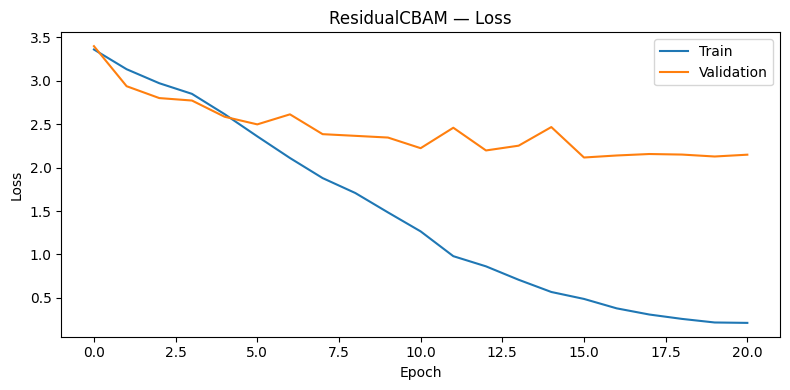


--- ResidualCBAM Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8791    0.8997    0.8893       299
     Modic 2     0.8101    0.7758    0.7926       165

    accuracy                         0.8556       464
   macro avg     0.8446    0.8377    0.8409       464
weighted avg     0.8546    0.8556    0.8549       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.8667    0.5200    0.6500        75
          P2     0.5810    0.6854    0.6289        89
          P3     0.6812    0.6812    0.6812       138
          P4     0.6154    0.7273    0.6667        99
          P5     0.6780    0.6349    0.6557        63

    accuracy                         0.6595       464
   macro avg     0.6844    0.6497    0.6565       464
weighted avg     0.6775    0.6595    0.6595       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8590    0.8

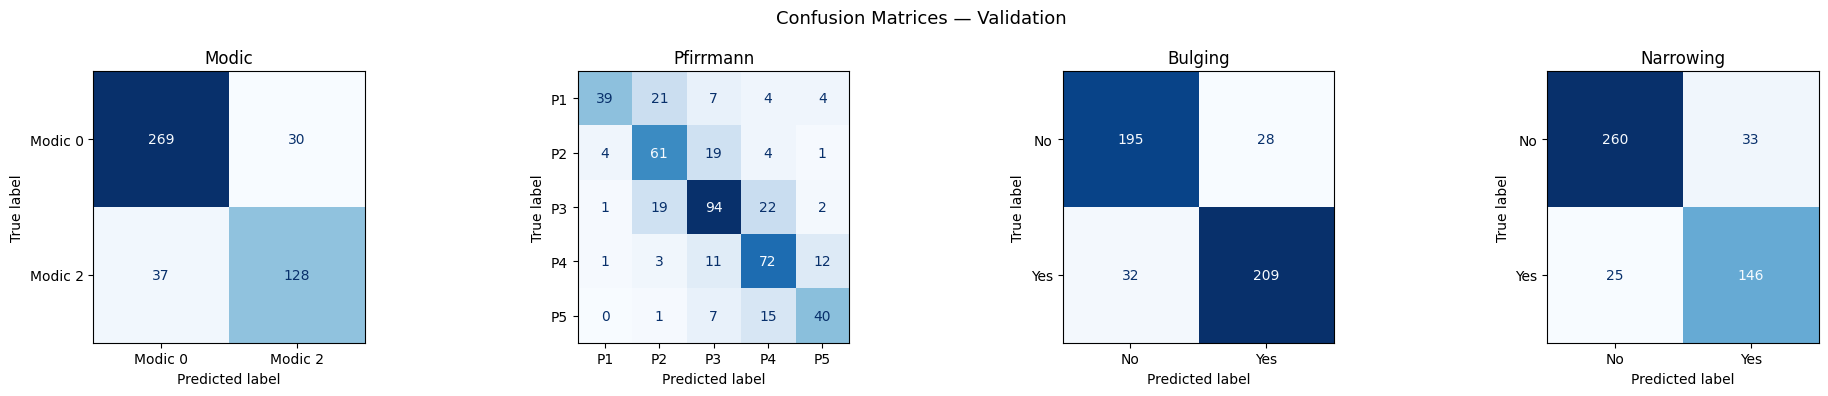

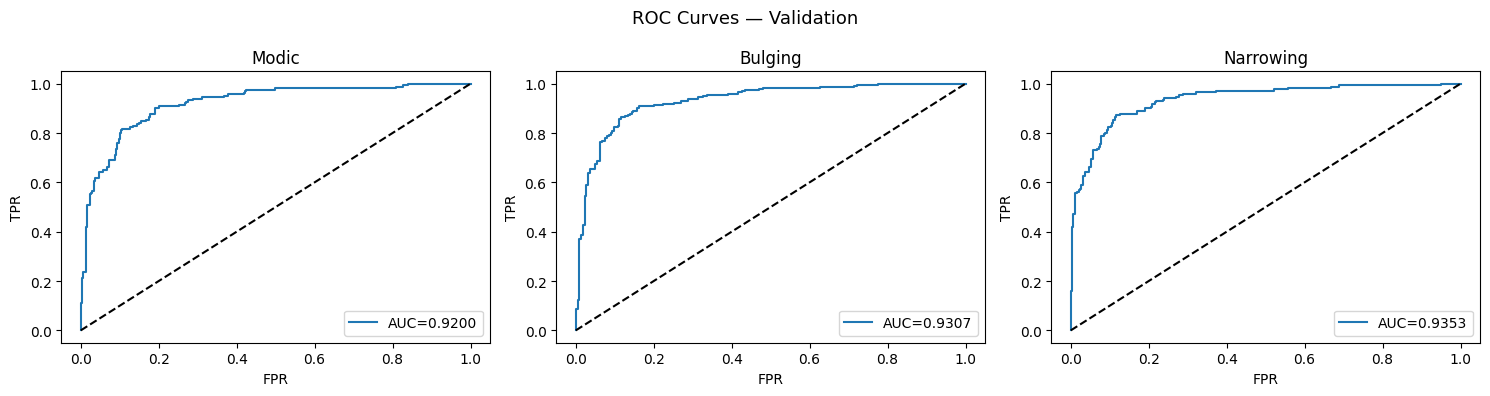


--- ResidualCBAM Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8292    0.8930    0.8599       299
     Modic 2     0.7762    0.6687    0.7184       166

    accuracy                         0.8129       465
   macro avg     0.8027    0.7808    0.7892       465
weighted avg     0.8103    0.8129    0.8094       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.7869    0.6857    0.7328        70
          P2     0.7255    0.6435    0.6820       115
          P3     0.6667    0.7353    0.6993       136
          P4     0.5826    0.7444    0.6537        90
          P5     0.8649    0.5926    0.7033        54

    accuracy                         0.6903       465
   macro avg     0.7253    0.6803    0.6942       465
weighted avg     0.7061    0.6903    0.6917       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8851    0.8739    0.8795       238


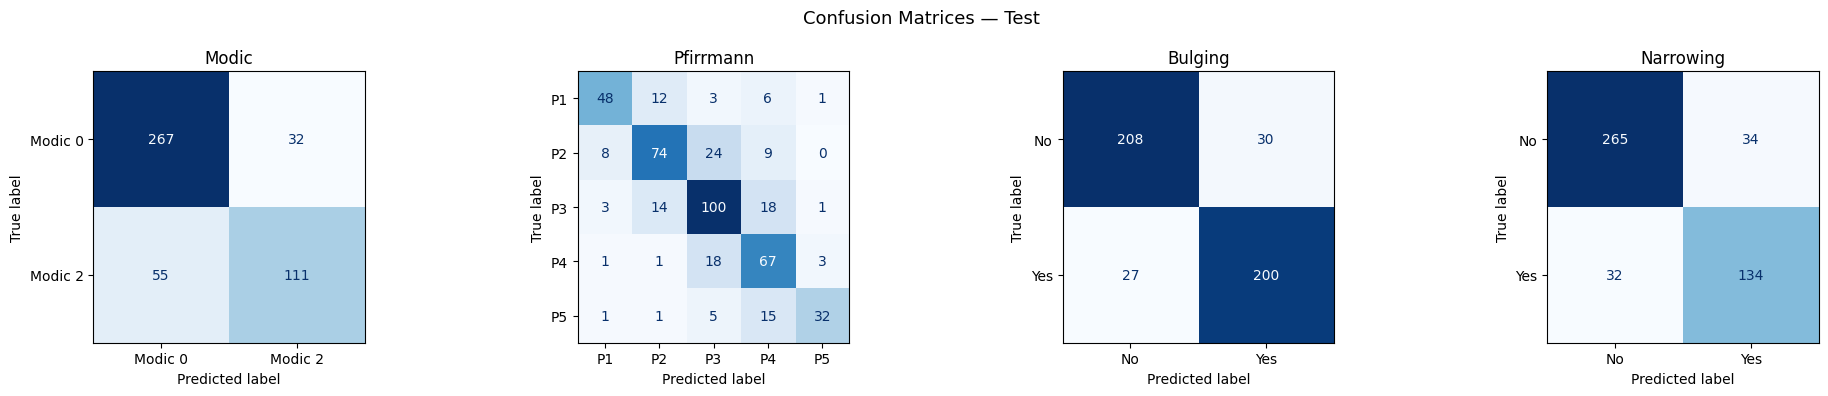

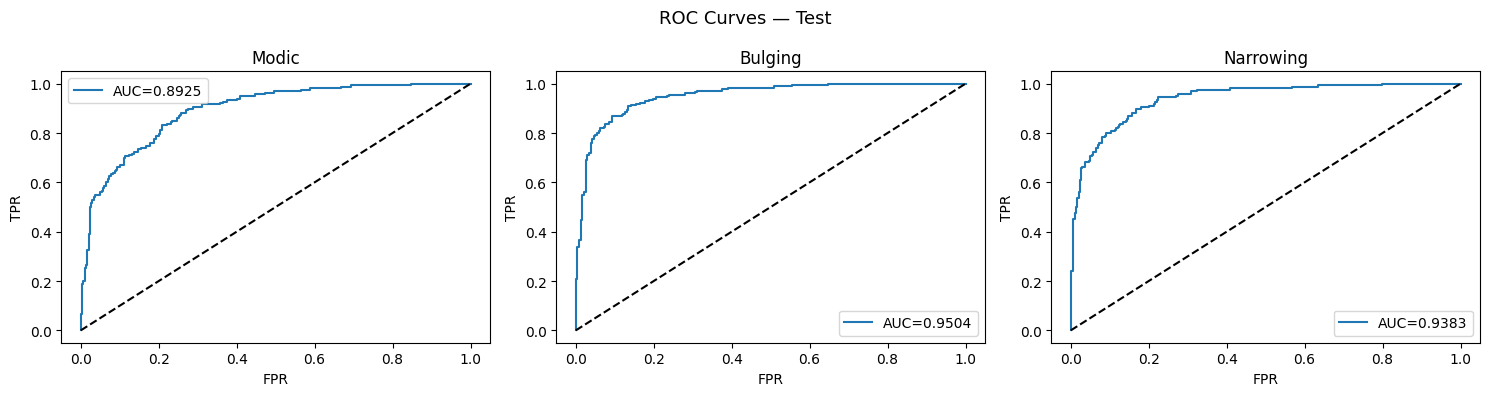


Training: MultiScaleCBAM
Trainable params: 16,461,397
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.3815  |  Val 3.2763
  ✔ Saved best model
Epoch 02/25  |  Train 3.1271  |  Val 2.9017
  ✔ Saved best model
Epoch 03/25  |  Train 2.9301  |  Val 3.0472
Epoch 04/25  |  Train 2.8095  |  Val 2.8168
  ✔ Saved best model
Epoch 05/25  |  Train 2.6429  |  Val 2.6020
  ✔ Saved best model
Epoch 06/25  |  Train 2.5126  |  Val 2.6354
Epoch 07/25  |  Train 2.3279  |  Val 2.7793
Epoch 08/25  |  Train 2.2992  |  Val 2.4986
  ✔ Saved best model
Epoch 09/25  |  Train 2.0924  |  Val 2.4760
  ✔ Saved best model
Epoch 10/25  |  Train 1.9216  |  Val 2.4237
  ✔ Saved best model
Epoch 11/25  |  Train 1.7363  |  Val 2.3709
  ✔ Saved best model
Epoch 12/25  |  Train 1.4662  |  Val 2.3043
  ✔ Saved best model
Epoch 13/25  |  Train 1.2348  |  Val 2.5084
Epoch 14/25  |  Train 1.1544  |  Val 2.4282
Epoch 15/25  |  Train 1.0277  |  Val 2.4125
Epoch 16

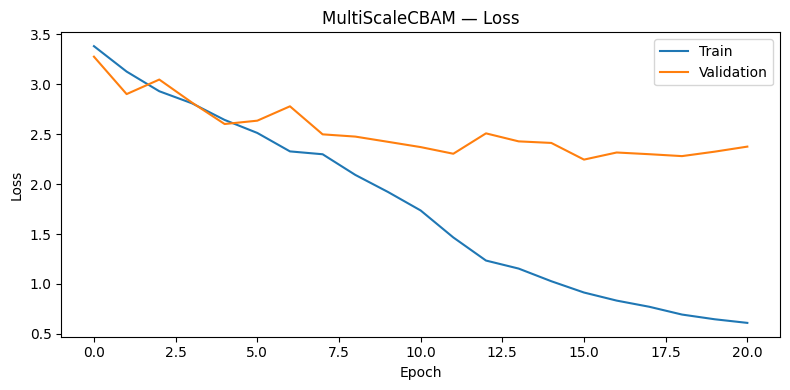


--- MultiScaleCBAM Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8878    0.8997    0.8937       299
     Modic 2     0.8137    0.7939    0.8037       165

    accuracy                         0.8621       464
   macro avg     0.8507    0.8468    0.8487       464
weighted avg     0.8614    0.8621    0.8617       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5733    0.5733    0.5733        75
          P2     0.4623    0.5506    0.5026        89
          P3     0.6071    0.6159    0.6115       138
          P4     0.5882    0.5051    0.5435        99
          P5     0.6897    0.6349    0.6612        63

    accuracy                         0.5754       464
   macro avg     0.5841    0.5760    0.5784       464
weighted avg     0.5811    0.5754    0.5767       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8133    0

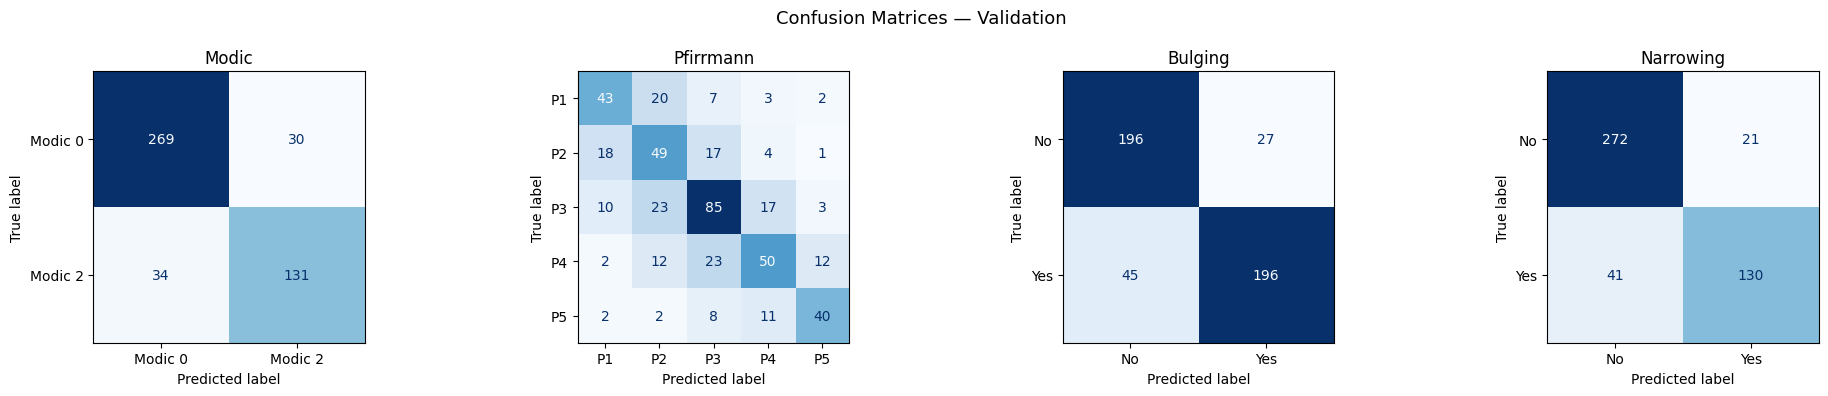

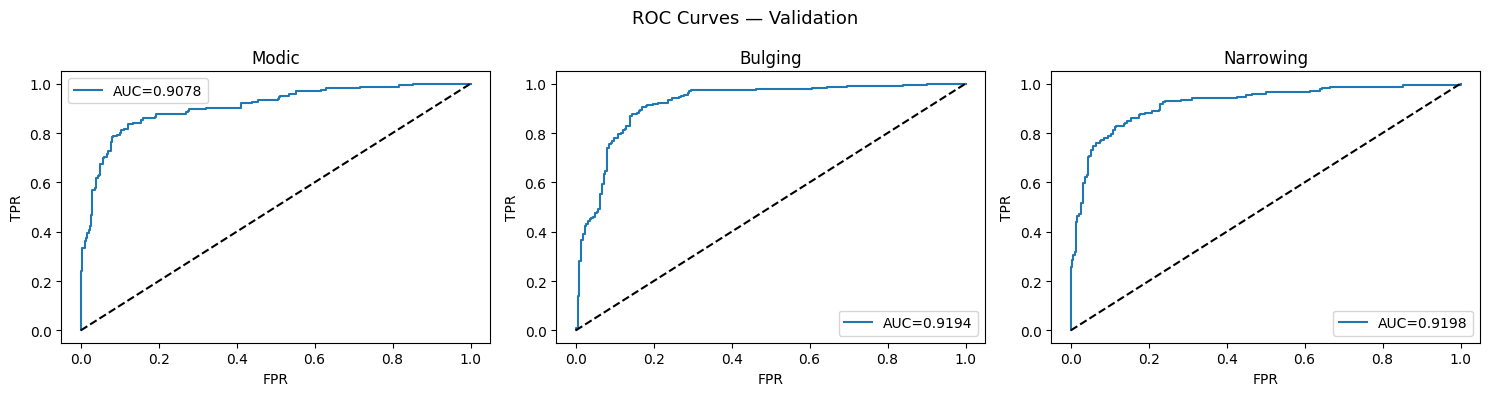


--- MultiScaleCBAM Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8445    0.9264    0.8836       299
     Modic 2     0.8394    0.6928    0.7591       166

    accuracy                         0.8430       465
   macro avg     0.8420    0.8096    0.8213       465
weighted avg     0.8427    0.8430    0.8391       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.6400    0.6857    0.6621        70
          P2     0.5338    0.6174    0.5726       115
          P3     0.5746    0.5662    0.5704       136
          P4     0.6806    0.5444    0.6049        90
          P5     0.5882    0.5556    0.5714        54

    accuracy                         0.5914       465
   macro avg     0.6035    0.5939    0.5963       465
weighted avg     0.5965    0.5914    0.5915       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8295    0.9202    0.8725       23

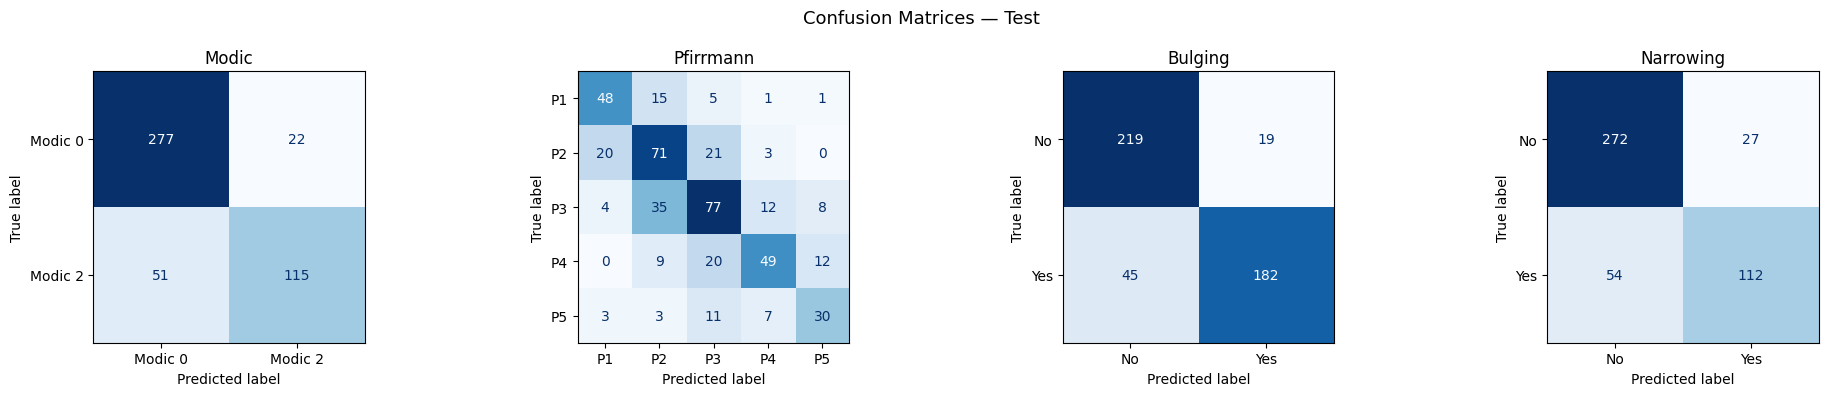

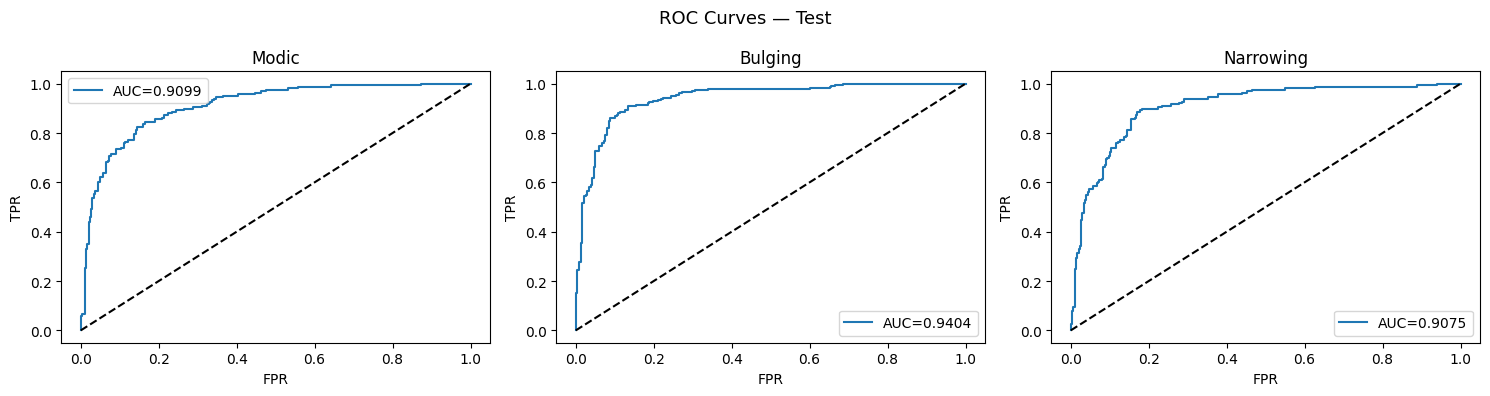


Training: DenseEncoder
Trainable params: 13,487,255
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.3989  |  Val 3.2875
  ✔ Saved best model
Epoch 02/25  |  Train 3.2163  |  Val 3.0009
  ✔ Saved best model
Epoch 03/25  |  Train 3.1391  |  Val 3.0480
Epoch 04/25  |  Train 3.0508  |  Val 2.9889
  ✔ Saved best model
Epoch 05/25  |  Train 2.9950  |  Val 2.8762
  ✔ Saved best model
Epoch 06/25  |  Train 2.8690  |  Val 3.0180
Epoch 07/25  |  Train 2.7805  |  Val 2.7790
  ✔ Saved best model
Epoch 08/25  |  Train 2.6523  |  Val 2.7850
Epoch 09/25  |  Train 2.5380  |  Val 2.6348
  ✔ Saved best model
Epoch 10/25  |  Train 2.4229  |  Val 2.7216
Epoch 11/25  |  Train 2.3437  |  Val 2.5732
  ✔ Saved best model
Epoch 12/25  |  Train 2.1970  |  Val 2.4932
  ✔ Saved best model
Epoch 13/25  |  Train 2.1262  |  Val 2.4722
  ✔ Saved best model
Epoch 14/25  |  Train 2.0164  |  Val 2.4726
Epoch 15/25  |  Train 1.9469  |  Val 2.4509
  ✔ Saved 

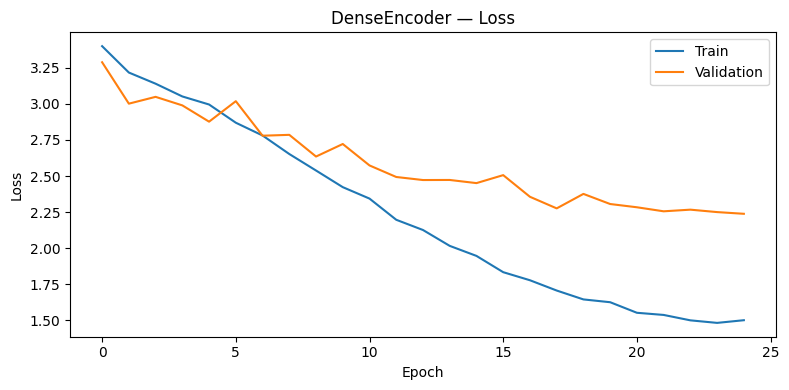


--- DenseEncoder Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8495    0.9064    0.8770       299
     Modic 2     0.8069    0.7091    0.7548       165

    accuracy                         0.8362       464
   macro avg     0.8282    0.8077    0.8159       464
weighted avg     0.8344    0.8362    0.8336       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5965    0.4533    0.5152        75
          P2     0.5294    0.5056    0.5172        89
          P3     0.5363    0.6957    0.6057       138
          P4     0.5632    0.4949    0.5269        99
          P5     0.8036    0.7143    0.7563        63

    accuracy                         0.5797       464
   macro avg     0.6058    0.5728    0.5843       464
weighted avg     0.5867    0.5797    0.5777       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8737    0.7

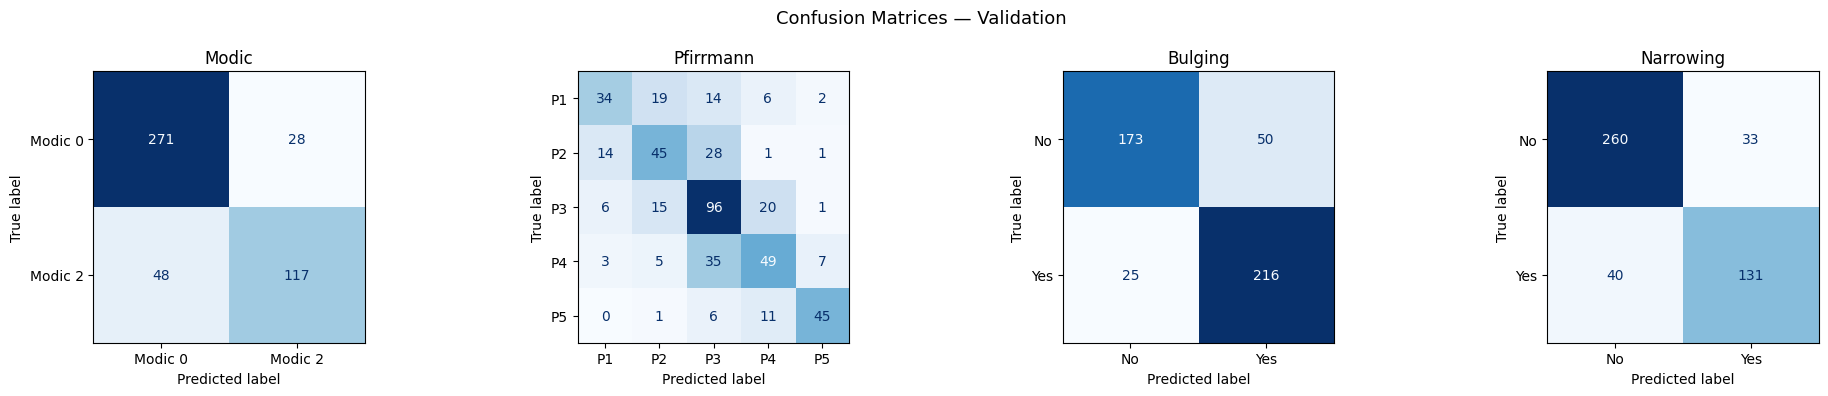

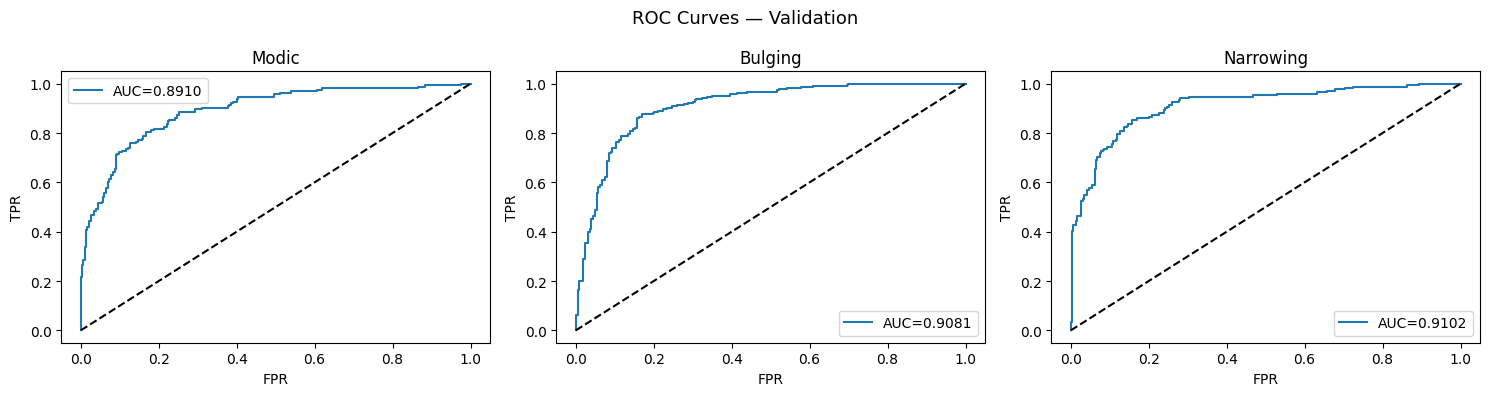


--- DenseEncoder Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7953    0.9097    0.8487       299
     Modic 2     0.7805    0.5783    0.6644       166

    accuracy                         0.7914       465
   macro avg     0.7879    0.7440    0.7565       465
weighted avg     0.7900    0.7914    0.7829       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5753    0.6000    0.5874        70
          P2     0.5408    0.4609    0.4977       115
          P3     0.5543    0.7132    0.6238       136
          P4     0.6164    0.5000    0.5521        90
          P5     0.7826    0.6667    0.7200        54

    accuracy                         0.5871       465
   macro avg     0.6139    0.5882    0.5962       465
weighted avg     0.5927    0.5871    0.5844       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8604    0.8025    0.8304       238


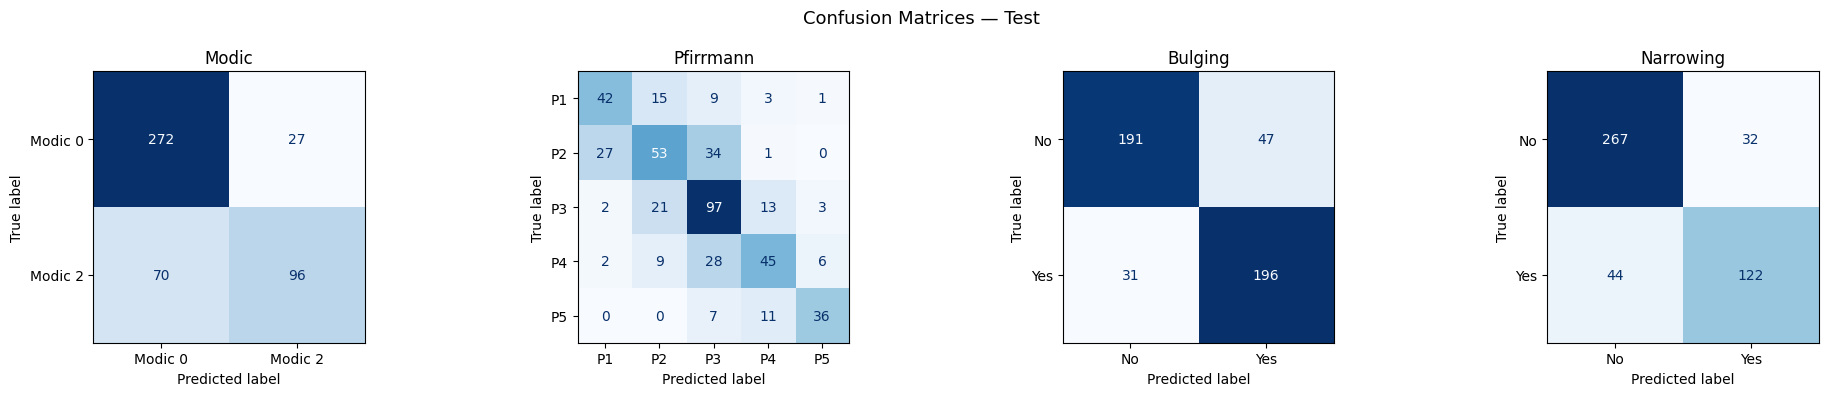

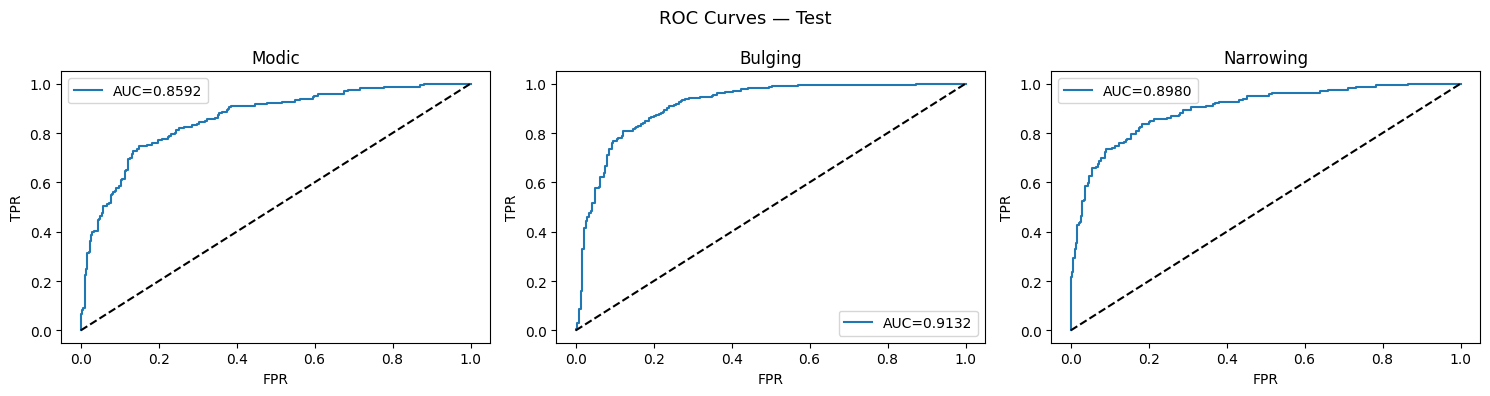


Training: WiderEncoder
Trainable params: 22,654,167
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.3264  |  Val 3.0413
  ✔ Saved best model
Epoch 02/25  |  Train 3.1055  |  Val 3.0011
  ✔ Saved best model
Epoch 03/25  |  Train 2.9599  |  Val 2.8745
  ✔ Saved best model
Epoch 04/25  |  Train 2.8195  |  Val 2.8630
  ✔ Saved best model
Epoch 05/25  |  Train 2.6631  |  Val 2.8377
  ✔ Saved best model
Epoch 06/25  |  Train 2.5024  |  Val 3.3532
Epoch 07/25  |  Train 2.3012  |  Val 2.6270
  ✔ Saved best model
Epoch 08/25  |  Train 2.1064  |  Val 2.5279
  ✔ Saved best model
Epoch 09/25  |  Train 1.8752  |  Val 3.0691
Epoch 10/25  |  Train 1.6450  |  Val 2.4470
  ✔ Saved best model
Epoch 11/25  |  Train 1.4012  |  Val 2.5678
Epoch 12/25  |  Train 1.2398  |  Val 2.6587
Epoch 13/25  |  Train 1.0502  |  Val 2.3467
  ✔ Saved best model
Epoch 14/25  |  Train 0.9068  |  Val 2.3855
Epoch 15/25  |  Train 0.7719  |  Val 2.2859
  ✔ Saved 

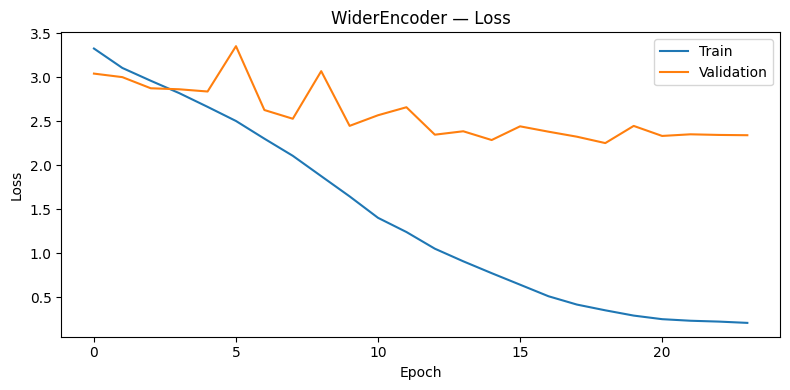


--- WiderEncoder Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8476    0.8930    0.8697       299
     Modic 2     0.7852    0.7091    0.7452       165

    accuracy                         0.8276       464
   macro avg     0.8164    0.8010    0.8075       464
weighted avg     0.8254    0.8276    0.8254       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.6939    0.4533    0.5484        75
          P2     0.4831    0.6404    0.5507        89
          P3     0.5855    0.6449    0.6138       138
          P4     0.6625    0.5354    0.5922        99
          P5     0.7231    0.7460    0.7344        63

    accuracy                         0.6034       464
   macro avg     0.6296    0.6040    0.6079       464
weighted avg     0.6185    0.6034    0.6029       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.9000    0.8

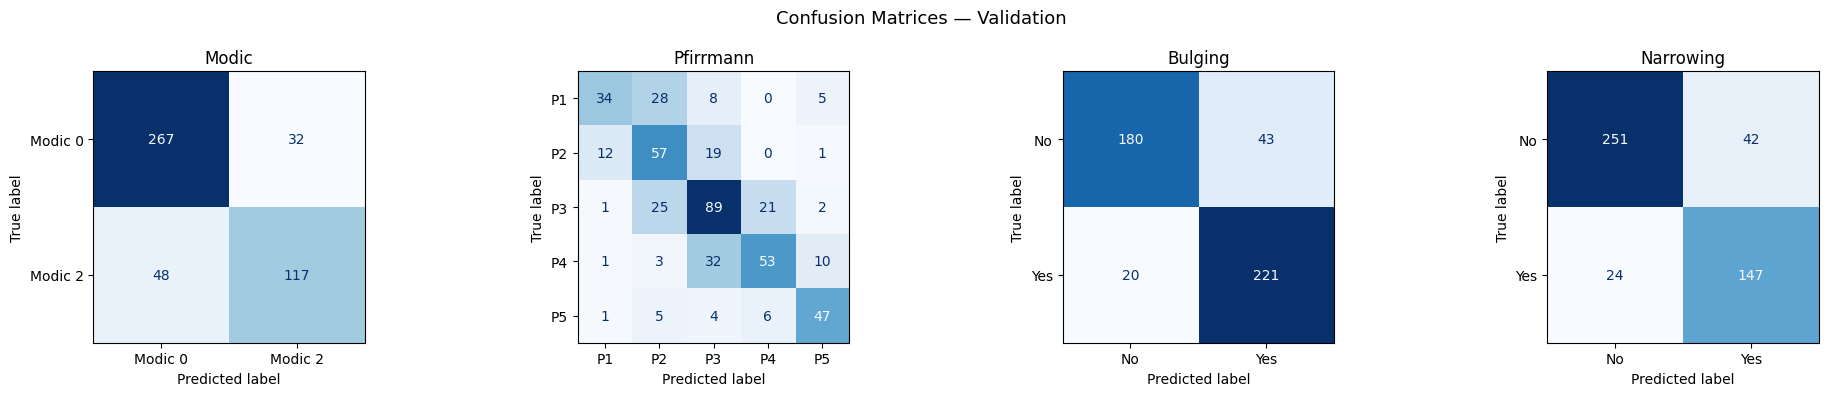

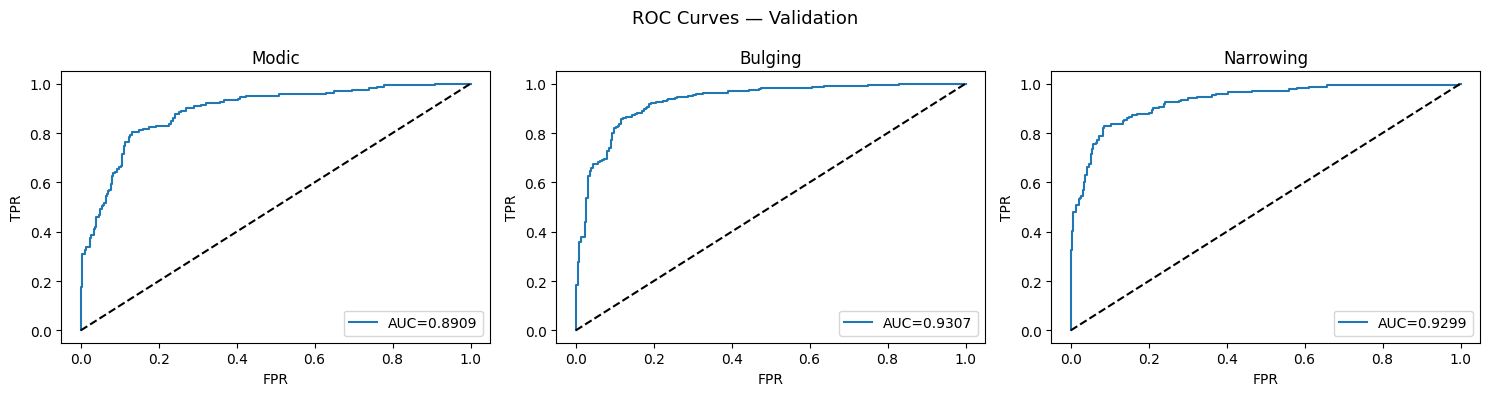


--- WiderEncoder Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8114    0.9498    0.8752       299
     Modic 2     0.8696    0.6024    0.7117       166

    accuracy                         0.8258       465
   macro avg     0.8405    0.7761    0.7935       465
weighted avg     0.8322    0.8258    0.8168       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.7833    0.6714    0.7231        70
          P2     0.6410    0.6522    0.6466       115
          P3     0.5904    0.7206    0.6490       136
          P4     0.6623    0.5667    0.6108        90
          P5     0.7778    0.6481    0.7071        54

    accuracy                         0.6581       465
   macro avg     0.6910    0.6518    0.6673       465
weighted avg     0.6676    0.6581    0.6589       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9123    0.8739    0.8927       238


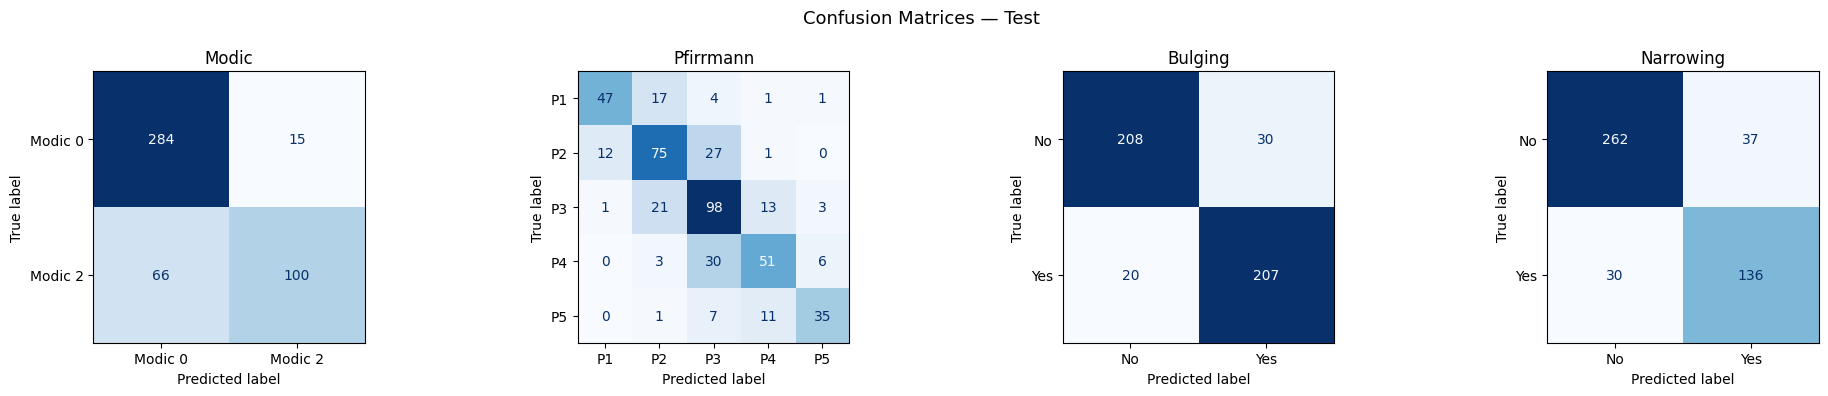

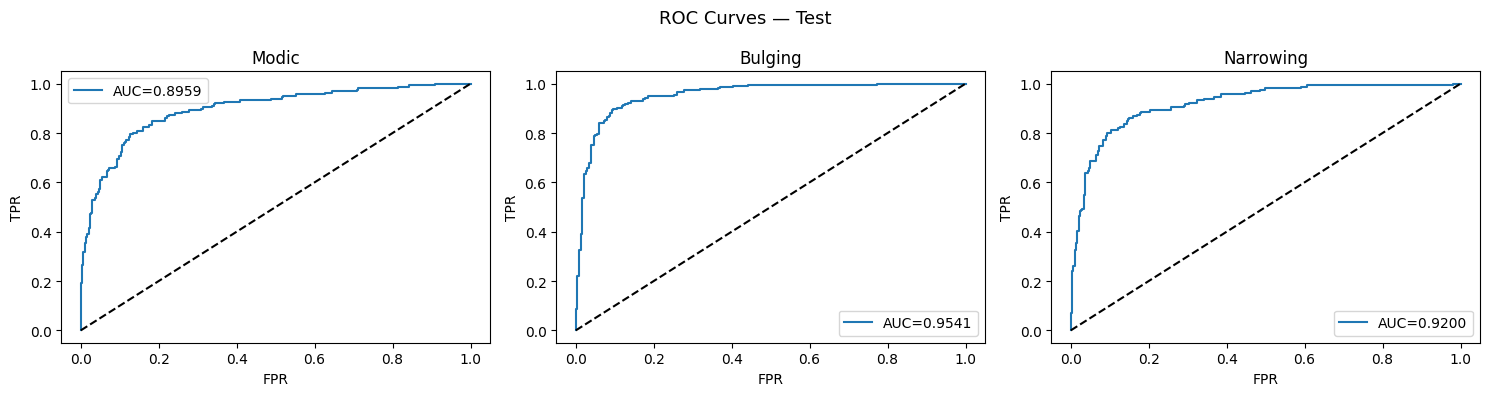


Training: SENetEncoder
Trainable params: 15,839,379
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.3754  |  Val 3.2013
  ✔ Saved best model
Epoch 02/25  |  Train 3.1286  |  Val 2.9607
  ✔ Saved best model
Epoch 03/25  |  Train 2.9769  |  Val 2.8840
  ✔ Saved best model
Epoch 04/25  |  Train 2.8254  |  Val 2.8349
  ✔ Saved best model
Epoch 05/25  |  Train 2.6476  |  Val 2.6813
  ✔ Saved best model
Epoch 06/25  |  Train 2.5177  |  Val 2.6156
  ✔ Saved best model
Epoch 07/25  |  Train 2.3510  |  Val 2.6919
Epoch 08/25  |  Train 2.1416  |  Val 2.5384
  ✔ Saved best model
Epoch 09/25  |  Train 1.9978  |  Val 2.3856
  ✔ Saved best model
Epoch 10/25  |  Train 1.8070  |  Val 2.2984
  ✔ Saved best model
Epoch 11/25  |  Train 1.6176  |  Val 2.3312
Epoch 12/25  |  Train 1.4505  |  Val 2.1997
  ✔ Saved best model
Epoch 13/25  |  Train 1.2360  |  Val 2.2469
Epoch 14/25  |  Train 1.0243  |  Val 2.3365
Epoch 15/25  |  Train 0.8521  |  

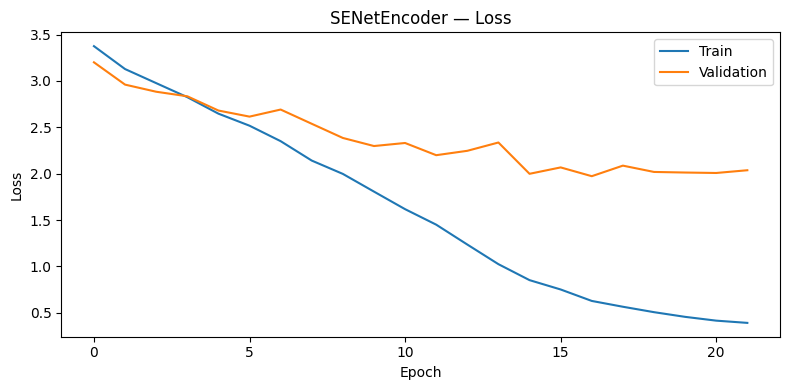


--- SENetEncoder Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8933    0.8963    0.8948       299
     Modic 2     0.8110    0.8061    0.8085       165

    accuracy                         0.8642       464
   macro avg     0.8522    0.8512    0.8517       464
weighted avg     0.8640    0.8642    0.8641       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.7869    0.6400    0.7059        75
          P2     0.5556    0.6180    0.5851        89
          P3     0.6351    0.6812    0.6573       138
          P4     0.6154    0.5657    0.5895        99
          P5     0.6615    0.6825    0.6719        63

    accuracy                         0.6379       464
   macro avg     0.6509    0.6375    0.6419       464
weighted avg     0.6438    0.6379    0.6388       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8722    0.8

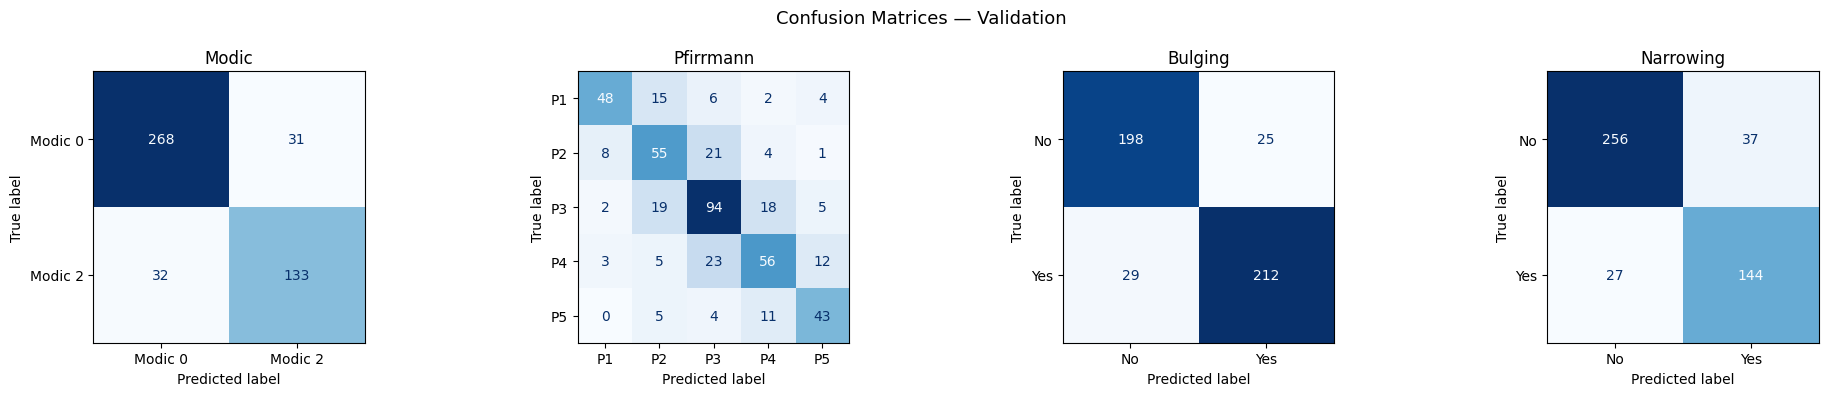

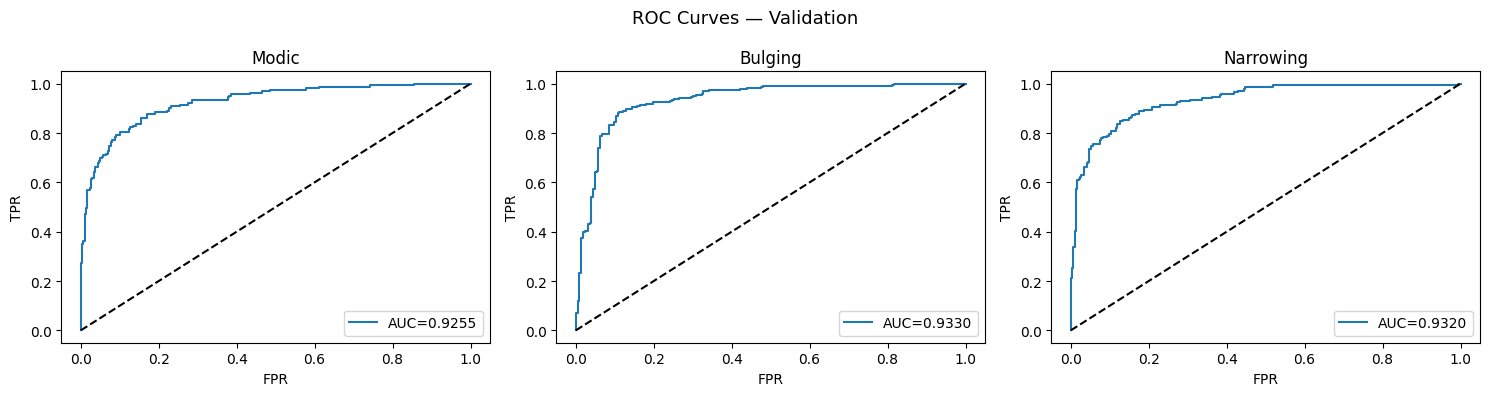


--- SENetEncoder Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8581    0.8896    0.8736       299
     Modic 2     0.7871    0.7349    0.7601       166

    accuracy                         0.8344       465
   macro avg     0.8226    0.8123    0.8168       465
weighted avg     0.8327    0.8344    0.8331       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.7188    0.6571    0.6866        70
          P2     0.6293    0.6348    0.6320       115
          P3     0.6340    0.7132    0.6713       136
          P4     0.7297    0.6000    0.6585        90
          P5     0.6034    0.6481    0.6250        54

    accuracy                         0.6559       465
   macro avg     0.6630    0.6507    0.6547       465
weighted avg     0.6606    0.6559    0.6560       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8941    0.8866    0.8903       238


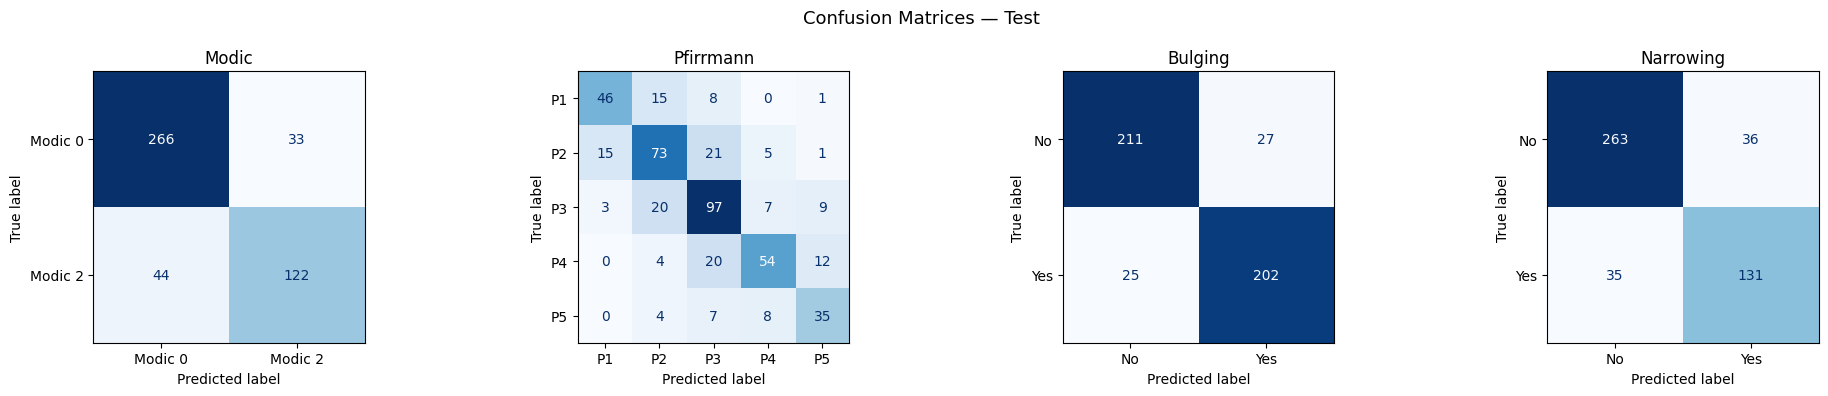

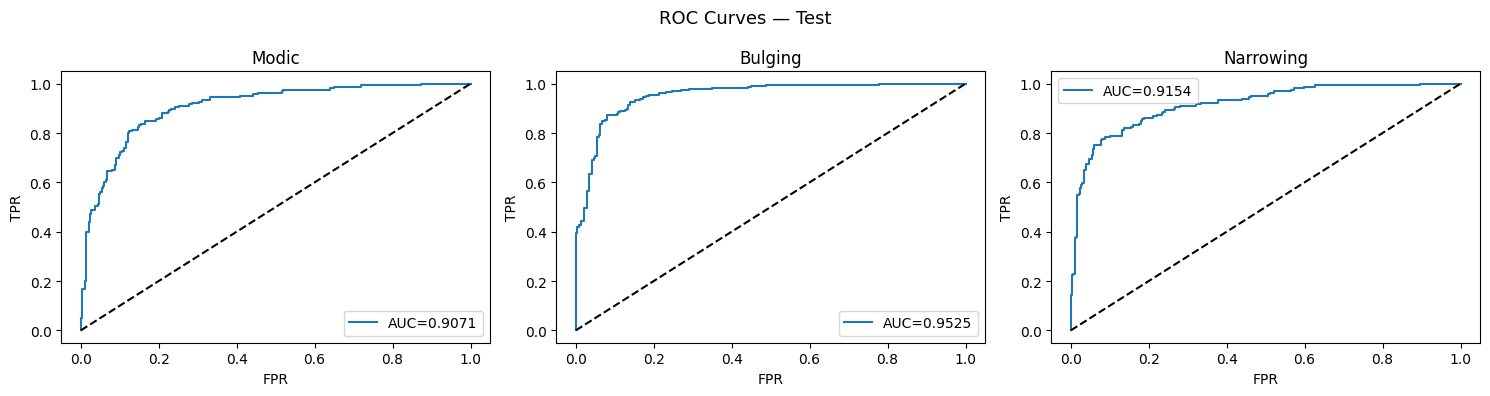


Training: DeepASPP
Trainable params: 19,048,471
Shape check: {'modic': (2, 2), 'pfirrmann': (2, 5), 'bulging': (2,), 'narrowing': (2,)}
Epoch 01/25  |  Train 3.4022  |  Val 3.1641
  ✔ Saved best model
Epoch 02/25  |  Train 3.2257  |  Val 3.0512
  ✔ Saved best model
Epoch 03/25  |  Train 3.0708  |  Val 3.0036
  ✔ Saved best model
Epoch 04/25  |  Train 2.9909  |  Val 2.8568
  ✔ Saved best model
Epoch 05/25  |  Train 2.8577  |  Val 2.7779
  ✔ Saved best model
Epoch 06/25  |  Train 2.7138  |  Val 2.7239
  ✔ Saved best model
Epoch 07/25  |  Train 2.5602  |  Val 2.7687
Epoch 08/25  |  Train 2.4563  |  Val 2.6294
  ✔ Saved best model
Epoch 09/25  |  Train 2.3258  |  Val 2.5880
  ✔ Saved best model
Epoch 10/25  |  Train 2.1851  |  Val 2.4921
  ✔ Saved best model
Epoch 11/25  |  Train 1.9980  |  Val 2.3786
  ✔ Saved best model
Epoch 12/25  |  Train 1.8925  |  Val 2.4023
Epoch 13/25  |  Train 1.7248  |  Val 2.3370
  ✔ Saved best model
Epoch 14/25  |  Train 1.5949  |  Val 2.3697
Epoch 15/25  |  

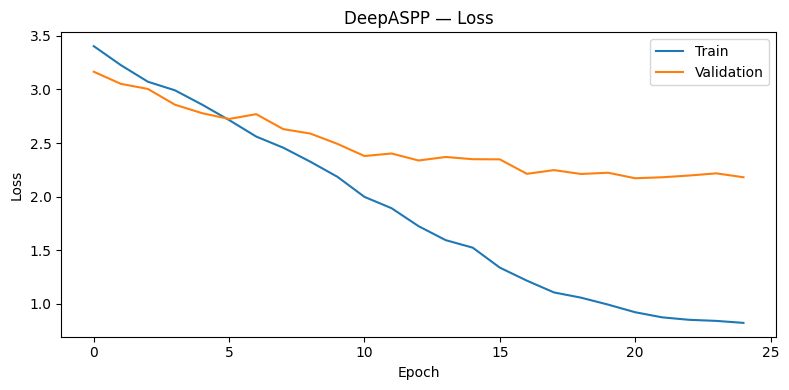


--- DeepASPP Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8693    0.8896    0.8793       299
     Modic 2     0.7911    0.7576    0.7740       165

    accuracy                         0.8427       464
   macro avg     0.8302    0.8236    0.8267       464
weighted avg     0.8415    0.8427    0.8419       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.8043    0.4933    0.6116        75
          P2     0.4919    0.6854    0.5728        89
          P3     0.6165    0.5942    0.6052       138
          P4     0.5340    0.5556    0.5446        99
          P5     0.7241    0.6667    0.6942        63

    accuracy                         0.5970       464
   macro avg     0.6342    0.5990    0.6057       464
weighted avg     0.6200    0.5970    0.5991       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.9153    0.7265 

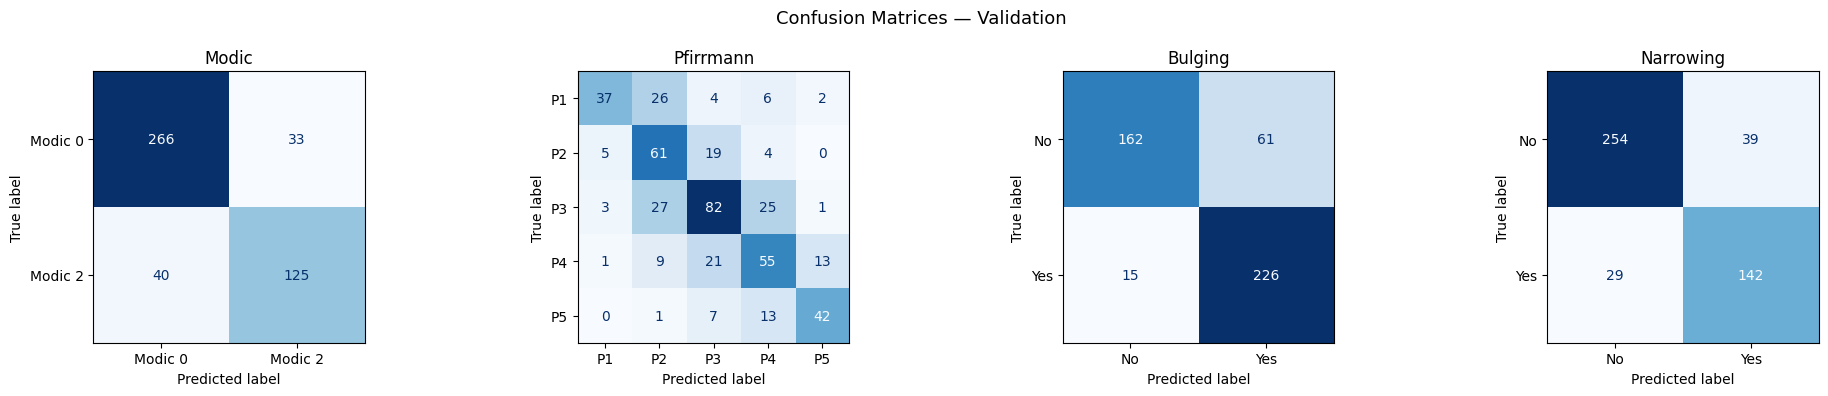

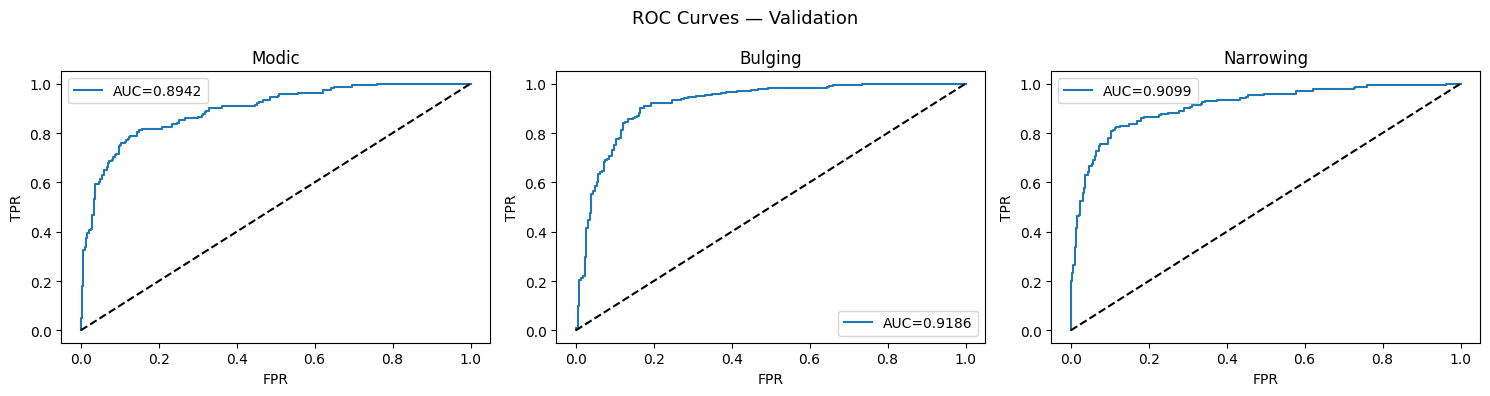


--- DeepASPP Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8371    0.8763    0.8562       299
     Modic 2     0.7566    0.6928    0.7233       166

    accuracy                         0.8108       465
   macro avg     0.7968    0.7845    0.7897       465
weighted avg     0.8083    0.8108    0.8088       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.6562    0.6000    0.6269        70
          P2     0.5455    0.6261    0.5830       115
          P3     0.6296    0.6250    0.6273       136
          P4     0.6818    0.6667    0.6742        90
          P5     0.7174    0.6111    0.6600        54

    accuracy                         0.6280       465
   macro avg     0.6461    0.6258    0.6343       465
weighted avg     0.6331    0.6280    0.6291       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9192    0.7647    0.8349       238
    

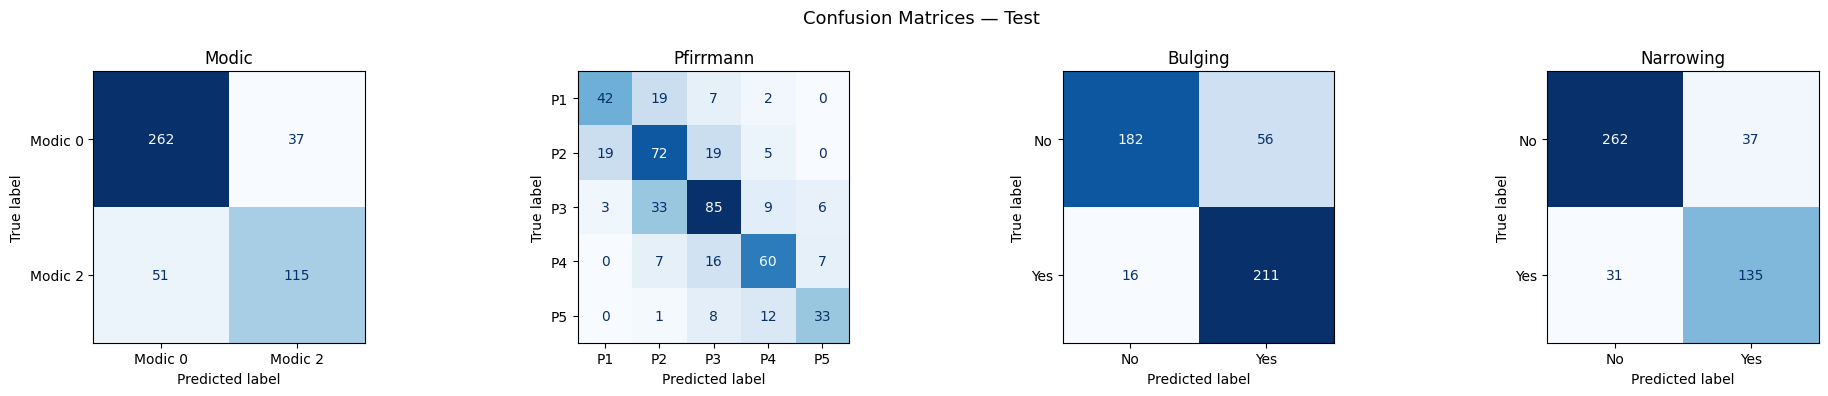

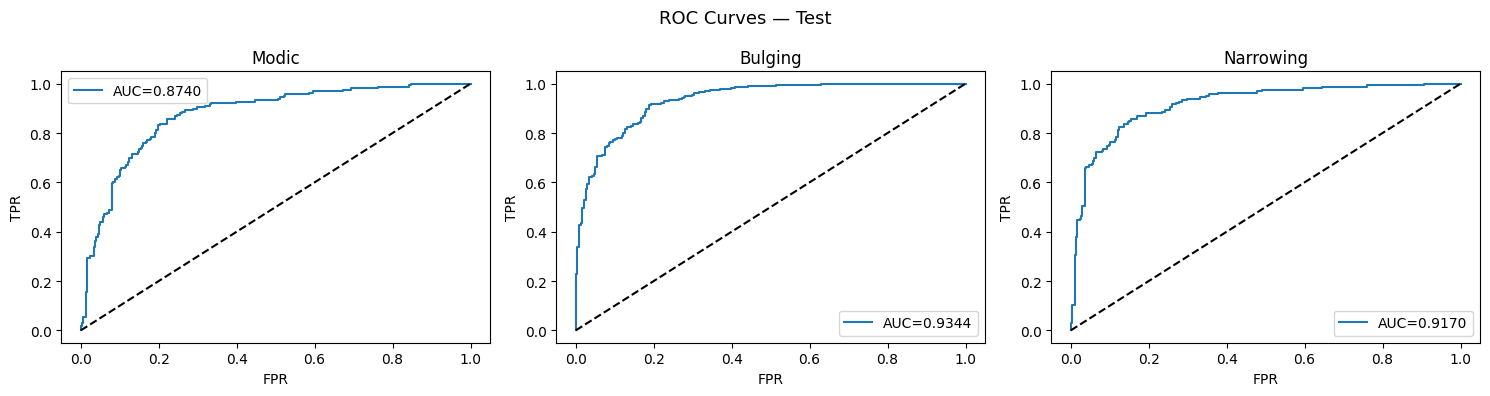

In [5]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)
from sklearn.model_selection import train_test_split

# =========================================================
# CUDA ERROR VISIBILITY
# =========================================================
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
os.environ["TORCH_USE_CUDA_DSA"]   = "1"

# =========================================================
# SEED + DEVICE
# =========================================================
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# =========================================================
# CONFIG  — same as best model
# =========================================================
DATA_DIR     = "/kaggle/input/datasets/kiranps24/lumbar-spine-disclevel/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)   # larger resolution — preserves fine disc detail
BATCH_SIZE   = 4                # stable BatchNorm statistics
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET  (unchanged from best model)
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] Could not load {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples  |  skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        targets = {
            "modic":     torch.tensor(0 if modic_raw == 0 else 1,
                                      dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(float(labels["bulging"]),
                                      dtype=torch.float32),
            "narrowing": torch.tensor(float(labels["narrowing"]),
                                      dtype=torch.float32),
        }
        return image, targets


# =========================================================
# SPLIT
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files: {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50, stratify=temp_labels, random_state=42
)
print(f"Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")

print("\nBuilding datasets...")
train_ds = DiscDataset(train_files)
val_ds   = DiscDataset(val_files)
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# SHARED BUILDING BLOCKS
# =========================================================
def cbr(in_ch, out_ch, stride=1, k=3):
    """Conv3d → BatchNorm3d → ReLU. The backbone of doc-4."""
    return nn.Sequential(
        nn.Conv3d(in_ch, out_ch, k, stride=stride,
                  padding=k//2, bias=False),
        nn.BatchNorm3d(out_ch),
        nn.ReLU(inplace=True)
    )

def cbr1(in_ch, out_ch):
    return cbr(in_ch, out_ch, k=1)


# ----------------------------------------------------------
# SE Block (Squeeze-and-Excitation)
# Channel-only attention — lightweight version of CBAM
# ----------------------------------------------------------
class SE3D(nn.Module):
    def __init__(self, ch, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(ch, max(1, ch // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, ch // reduction), ch),
            nn.Sigmoid()
        )

    def forward(self, x):
        B, C = x.shape[:2]
        w = F.adaptive_avg_pool3d(x, 1).view(B, C)
        w = self.fc(w).view(B, C, 1, 1, 1)
        return x * w


# ----------------------------------------------------------
# CBAM 3D  (same as best model — used across all 6)
# ----------------------------------------------------------
class CBAM3D(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels, max(1, channels // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, channels // reduction), channels)
        )
        self.spatial_conv = nn.Conv3d(2, 1, 7, padding=3,
                                      bias=False)

    def forward(self, x):
        B, C, D, H, W = x.shape
        avg_c = F.adaptive_avg_pool3d(x, 1).view(B, C)
        max_c = F.adaptive_max_pool3d(x, 1).view(B, C)
        ch    = torch.sigmoid(
            self.channel_mlp(avg_c) + self.channel_mlp(max_c)
        ).view(B, C, 1, 1, 1)
        x = x * ch
        avg_s = x.mean(1, keepdim=True)
        max_s = x.max(1, keepdim=True).values
        sp    = torch.sigmoid(
            self.spatial_conv(torch.cat([avg_s, max_s], 1))
        )
        return x * sp


# ----------------------------------------------------------
# ASPP 3D  (same as best model)
# ----------------------------------------------------------
class ASPP3D(nn.Module):
    def __init__(self, in_ch, out_ch=256,
                 dilations=(6, 12, 18)):
        super().__init__()
        self.b1 = cbr1(in_ch, out_ch)
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 3,
                          padding=d, dilation=d, bias=False),
                nn.BatchNorm3d(out_ch), nn.ReLU()
            ) for d in dilations
        ])
        n = 1 + len(dilations)
        self.project = nn.Sequential(
            nn.Conv3d(out_ch * n, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(),
            nn.Dropout3d(0.1)
        )

    def forward(self, x):
        feats = [self.b1(x)] + [b(x) for b in self.branches]
        return self.project(torch.cat(feats, 1))


# ----------------------------------------------------------
# Shared task heads factory
# ----------------------------------------------------------
def make_heads(in_dim):
    return nn.ModuleDict({
        "modic":     nn.Sequential(nn.Linear(in_dim, 128),
                                   nn.ReLU(),
                                   nn.Linear(128, 2)),
        "pfirrmann": nn.Sequential(nn.Linear(in_dim, 128),
                                   nn.ReLU(),
                                   nn.Linear(128, 5)),
        "bulging":   nn.Sequential(nn.Linear(in_dim, 64),
                                   nn.ReLU(),
                                   nn.Linear(64, 1)),
        "narrowing": nn.Sequential(nn.Linear(in_dim, 64),
                                   nn.ReLU(),
                                   nn.Linear(64, 1)),
    })

def run_heads(heads, feat, dropout):
    feat = dropout(feat)
    return {
        "modic":     heads["modic"](feat),
        "pfirrmann": heads["pfirrmann"](feat),
        "bulging":   heads["bulging"](feat).squeeze(1),
        "narrowing": heads["narrowing"](feat).squeeze(1),
    }


# =========================================================
# MODEL 1 — ResidualCBAM
# =========================================================
# Adds residual skip connections to the doc-4 plain encoder.
# Why: skip connections allow gradients to flow directly
# to early layers without vanishing through 4 conv+BN+ReLU
# stacks. The plain doc-4 encoder has no skips — residuals
# make it equivalent to a mini ResNet which generalises
# better on small datasets by preserving low-level features
# that the deeper layers might otherwise overwrite.
# CBAM + ASPP unchanged from best model.
# =========================================================
class ResBlock3D(nn.Module):
    """
    Basic residual block: Conv→BN→ReLU→Conv→BN + skip.
    Projection shortcut when stride>1 or channels change.
    """
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.c1   = nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                              padding=1, bias=False)
        self.n1   = nn.BatchNorm3d(out_ch)
        self.c2   = nn.Conv3d(out_ch, out_ch, 3,
                              padding=1, bias=False)
        self.n2   = nn.BatchNorm3d(out_ch)
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1,
                      stride=stride, bias=False),
            nn.BatchNorm3d(out_ch)
        ) if stride != 1 or in_ch != out_ch else nn.Identity()
        self.act  = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.act(self.n1(self.c1(x)))
        out = self.n2(self.c2(out))
        return self.act(out + self.skip(x))


class ResidualCBAM3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            ResBlock3D(1,   64,  stride=2),
            ResBlock3D(64,  128, stride=2),
            ResBlock3D(128, 256, stride=2),
            ResBlock3D(256, 512, stride=2),
        )
        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(256)

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.pool(x).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# MODEL 2 — MultiScaleCBAM
# =========================================================
# Extracts features at multiple encoder scales and fuses
# them before ASPP. Why: CBAM on only the deepest feature
# map (as in doc-4) misses fine-grained spatial detail from
# earlier layers. Disc bulging and endplate irregularities
# appear at enc2/enc3 spatial resolutions. This model
# applies CBAM at enc3 and enc4 separately then fuses,
# giving attention-recalibrated features from two scales.
# =========================================================
class MultiScaleCBAM3D(nn.Module):
    def __init__(self):
        super().__init__()

        def conv_bn_relu(in_ch, out_ch, stride=1):
            return nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                          padding=1, bias=False),
                nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True)
            )

        self.enc1 = conv_bn_relu(1,   64,  stride=2)
        self.enc2 = conv_bn_relu(64,  128, stride=2)
        self.enc3 = conv_bn_relu(128, 256, stride=2)
        self.enc4 = conv_bn_relu(256, 512, stride=2)

        # CBAM at two scales
        self.attn3 = CBAM3D(256)
        self.attn4 = CBAM3D(512)

        # Project enc3 to 512 for fusion with enc4
        self.proj3 = cbr1(256, 512)

        # Fuse: enc4_attn + enc3_projected → 512
        self.fuse  = nn.Sequential(
            cbr1(512 + 512, 512),
            nn.Dropout3d(0.1)
        )

        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(256)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)    # (B,256, D/8, H/8, W/8)
        e4 = self.enc4(e3)    # (B,512,D/16,H/16,W/16)

        a3 = self.attn3(e3)
        a4 = self.attn4(e4)

        # Downsample a3 to match a4 spatial size
        a3_down = F.adaptive_avg_pool3d(
            self.proj3(a3), a4.shape[2:]
        )
        fused = self.fuse(torch.cat([a4, a3_down], 1))

        x = self.aspp(fused)
        x = self.pool(x).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# MODEL 3 — DenseEncoder
# =========================================================
# Replaces the plain encoder with a DenseNet-style encoder
# where each block concatenates all previous feature maps.
# Why: dense connections reuse features across all depths,
# reducing the number of parameters needed to achieve the
# same representational power (DenseNet uses fewer params
# than ResNet for equivalent accuracy). On a 2072-sample
# dataset this matters: fewer parameters → less overfitting.
# CBAM + ASPP unchanged.
# =========================================================
class DenseBlock3D(nn.Module):
    """
    Dense block: each layer receives all previous outputs.
    growth_rate: channels added per layer.
    num_layers: depth of the dense block.
    """
    def __init__(self, in_ch, growth_rate=32, num_layers=4):
        super().__init__()
        self.layers = nn.ModuleList()
        ch = in_ch
        for _ in range(num_layers):
            self.layers.append(nn.Sequential(
                nn.BatchNorm3d(ch), nn.ReLU(inplace=True),
                nn.Conv3d(ch, growth_rate, 3,
                          padding=1, bias=False)
            ))
            ch += growth_rate
        self.out_ch = ch

    def forward(self, x):
        feats = [x]
        for layer in self.layers:
            feats.append(layer(torch.cat(feats, 1)))
        return torch.cat(feats, 1)


class TransitionDown3D(nn.Module):
    """Compress channels + halve spatial via stride-2 conv."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.BatchNorm3d(in_ch), nn.ReLU(inplace=True),
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.AvgPool3d(2, stride=2)
        )

    def forward(self, x):
        return self.block(x)


class DenseEncoder3D(nn.Module):
    def __init__(self):
        super().__init__()
        # Stem
        self.stem = nn.Sequential(
            nn.Conv3d(1, 64, 3, stride=2, padding=1,
                      bias=False),
            nn.BatchNorm3d(64), nn.ReLU(inplace=True)
        )
        gr = 32   # growth rate
        # Dense stages
        self.db1 = DenseBlock3D(64,  gr, num_layers=4)
        self.td1 = TransitionDown3D(self.db1.out_ch, 128)

        self.db2 = DenseBlock3D(128, gr, num_layers=4)
        self.td2 = TransitionDown3D(self.db2.out_ch, 256)

        self.db3 = DenseBlock3D(256, gr, num_layers=4)
        self.td3 = TransitionDown3D(self.db3.out_ch, 512)

        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(256)

    def forward(self, x):
        x = self.stem(x)
        x = self.td1(self.db1(x))
        x = self.td2(self.db2(x))
        x = self.td3(self.db3(x))
        x = self.attn(x)
        x = self.aspp(x)
        x = self.pool(x).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# MODEL 4 — WiderEncoder
# =========================================================
# Uses a wider (more channels) but shallower encoder than
# doc-4. Why: doc-4 uses [64,128,256,512] channels with 4
# stride-2 downsamples. A wider encoder [128,256,512,512]
# with only 3 downsamples keeps a larger spatial feature
# map at the ASPP stage, giving ASPP more spatial context
# to work with. More channels per layer = richer feature
# representation at each spatial scale. The shallower depth
# avoids excessive spatial compression of the 32×128×128
# volume down to 2×8×8 (doc-4) vs 4×16×16 (this model).
# =========================================================
class WiderEncoder3D(nn.Module):
    def __init__(self):
        super().__init__()

        def conv_bn_relu(in_ch, out_ch, stride=1):
            return nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                          padding=1, bias=False),
                nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True)
            )

        # 3 downsamples instead of 4 → larger spatial at ASPP
        # Wider channels → more expressive per layer
        self.encoder = nn.Sequential(
            conv_bn_relu(1,   128, stride=2),   # /2
            conv_bn_relu(128, 256, stride=2),   # /4
            conv_bn_relu(256, 512, stride=2),   # /8
            conv_bn_relu(512, 512, stride=1),   # same spatial
        )

        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(256)

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.pool(x).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# MODEL 5 — SENetEncoder
# =========================================================
# Replaces CBAM with SE (Squeeze-and-Excitation) blocks
# applied after EVERY encoder stage, not just the last.
# Why: SE blocks are cheaper than CBAM (no spatial branch)
# and can be inserted densely without memory overhead.
# Channel recalibration at every stage progressively focuses
# the network on disc-relevant channels — each stage's SE
# block learns which feature maps are important for its
# specific spatial resolution. ASPP unchanged.
# =========================================================
class SEEncoderBlock3D(nn.Module):
    """Conv-BN-ReLU followed by SE channel recalibration."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                      padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
        self.se = SE3D(out_ch)

    def forward(self, x):
        return self.se(self.conv(x))


class SENetEncoder3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            SEEncoderBlock3D(1,   64,  stride=2),
            SEEncoderBlock3D(64,  128, stride=2),
            SEEncoderBlock3D(128, 256, stride=2),
            SEEncoderBlock3D(256, 512, stride=2),
        )
        # Final CBAM for spatial attention after all SE
        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(256)

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.pool(x).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# MODEL 6 — DeepASPP
# =========================================================
# Keeps the plain doc-4 encoder exactly but uses a richer
# ASPP with 5 branches (adding a GAP branch and an extra
# dilation rate) plus a lightweight decoder that upsamples
# ASPP features back to enc2 resolution before pooling.
# Why: standard ASPP pools to a single global vector which
# discards spatial arrangement. A one-step decoder that
# fuses ASPP with enc2 lateral features preserves spatial
# structure before the final GAP. For localised pathology
# (disc bulging is spatially asymmetric), knowing WHERE
# the ASPP activated matters, not just THAT it activated.
# =========================================================
class RicherASPP3D(nn.Module):
    """
    ASPP with 5 branches: 1×1 + 3 dilated + GAP.
    GAP branch captures global image-level context and
    is broadcast back to the spatial map before concat.
    """
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.b1   = cbr1(in_ch, out_ch)
        self.b2   = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=6,
                      dilation=6, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU()
        )
        self.b3   = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=12,
                      dilation=12, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU()
        )
        self.b4   = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=18,
                      dilation=18, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU()
        )
        # GAP branch — broadcasts global context spatially
        self.b5   = nn.Sequential(
            nn.AdaptiveAvgPool3d(1),
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU()
        )
        self.project = nn.Sequential(
            nn.Conv3d(out_ch * 5, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(),
            nn.Dropout3d(0.1)
        )

    def forward(self, x):
        gap = self.b5(x).expand(-1, -1,
                                x.shape[2],
                                x.shape[3],
                                x.shape[4])
        return self.project(torch.cat([
            self.b1(x), self.b2(x),
            self.b3(x), self.b4(x), gap
        ], 1))


class DeepASPP3D(nn.Module):
    def __init__(self):
        super().__init__()

        def conv_bn_relu(in_ch, out_ch, stride=1):
            return nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                          padding=1, bias=False),
                nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True)
            )

        # Identical plain encoder as doc-4
        self.enc1 = conv_bn_relu(1,   64,  stride=2)
        self.enc2 = conv_bn_relu(64,  128, stride=2)
        self.enc3 = conv_bn_relu(128, 256, stride=2)
        self.enc4 = conv_bn_relu(256, 512, stride=2)

        self.attn = CBAM3D(512)
        self.aspp = RicherASPP3D(512, 256)

        # Lightweight decoder: fuse ASPP with enc2 lateral
        # enc2 at (B,128, D/4,H/4,W/4) — upsample ASPP to match
        self.lat2    = cbr1(128, 64)   # lateral projection
        self.decoder = nn.Sequential(
            cbr(256 + 64, 256),        # fuse ASPP + lateral
            cbr(256, 128)
        )

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.heads   = make_heads(128)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)   # (B,128, D/4, H/4, W/4)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        e4 = self.attn(e4)
        a  = self.aspp(e4)   # (B,256, D/16,H/16,W/16)

        # Upsample ASPP to enc2 resolution
        a_up = F.interpolate(a, size=e2.shape[2:],
                             mode="trilinear",
                             align_corners=False)
        lat  = self.lat2(e2)

        dec  = self.decoder(
            torch.cat([a_up, lat], 1)
        )                    # (B,128, D/4, H/4, W/4)

        x = self.pool(dec).flatten(1)
        return run_heads(self.heads, x, self.dropout)


# =========================================================
# LOSS  (plain CE + BCE — same as best model)
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL LOOP  (same as best model)
# =========================================================
def run_epoch(model, loader, optimizer, scaler, train=True):
    model.train() if train else model.eval()
    total = 0.0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}

            if train:
                optimizer.zero_grad()

            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)

            if not torch.isfinite(loss):
                if train:
                    optimizer.zero_grad()
                continue

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total += loss.item()

    return total / max(len(loader), 1)


# =========================================================
# TRAINING FUNCTION
# =========================================================
def train_model(model, model_name):
    print(f"\n{'='*60}")
    print(f"Training: {model_name}")
    n = sum(p.numel() for p in model.parameters()
            if p.requires_grad)
    print(f"Trainable params: {n:,}")
    print('='*60)

    # Shape sanity check
    with torch.no_grad():
        dummy = torch.randn(2, 1, *TARGET_SHAPE).to(device)
        out_  = model(dummy)
        for k, v in out_.items():
            assert not torch.isnan(v).any(), f"NaN in {k}"
        print("Shape check:",
              {k: tuple(v.shape) for k, v in out_.items()})
    del dummy, out_

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LR, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS
    )
    scaler = GradScaler(enabled=torch.cuda.is_available())

    train_losses, val_losses = [], []
    best_val = np.inf
    counter  = 0
    ckpt     = f"best_{model_name}.pth"

    for epoch in range(EPOCHS):
        tr = run_epoch(model, train_loader,
                       optimizer, scaler, train=True)
        vl = run_epoch(model, val_loader,
                       optimizer, scaler, train=False)
        scheduler.step()

        train_losses.append(tr)
        val_losses.append(vl)
        print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
              f"Train {tr:.4f}  |  Val {vl:.4f}")

        if vl < best_val:
            best_val = vl
            counter  = 0
            torch.save(model.state_dict(), ckpt)
            print("  ✔ Saved best model")
        else:
            counter += 1
            if counter >= PATIENCE:
                print("Early stopping.")
                break

    # Loss curve
    plt.figure(figsize=(8, 4))
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses,   label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title(f"{model_name} — Loss")
    plt.legend(); plt.tight_layout(); plt.show()

    return ckpt


# =========================================================
# EVALUATION FUNCTION  (same as best model)
# =========================================================
def evaluate(model, ckpt, loader, split_name="Test"):
    model.load_state_dict(
        torch.load(ckpt, map_location=device)
    )
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in
             ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy()
            )
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy()
            )
            gts["pfirrmann"].extend(
                tgt["pfirrmann"].numpy()
            )

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy()
            )
            gts["bulging"].extend(
                tgt["bulging"].long().numpy()
            )

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy()
            )
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy()
            )

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }

    for task, (names, title) in task_labels.items():
        print(title)
        present    = sorted(set(gts[task]))
        used_names = [names[i] for i in present
                      if i < len(names)]
        print(classification_report(
            gts[task], preds[task],
            labels=present, target_names=used_names,
            digits=4, zero_division=0
        ))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}",
                 fontsize=13)
    for ax, (task, (names, _)) in zip(
            axes, task_labels.items()):
        present    = sorted(set(gts[task]))
        used_names = [names[i] for i in present
                      if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used_names
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}", fontsize=13)
    for ax, task in zip(axes,
                        ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (only 1 class)")
            continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"AUC={roc_auc:.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


# =========================================================
# RUN ALL 6 MODELS
# =========================================================
models = [
    (ResidualCBAM3D(),  "ResidualCBAM"),
    (MultiScaleCBAM3D(),"MultiScaleCBAM"),
    (DenseEncoder3D(),  "DenseEncoder"),
    (WiderEncoder3D(),  "WiderEncoder"),
    (SENetEncoder3D(),  "SENetEncoder"),
    (DeepASPP3D(),      "DeepASPP"),
]

results = {}
for model, name in models:
    model = model.to(device)
    ckpt  = train_model(model, name)
    print(f"\n--- {name} Validation ---")
    evaluate(model, ckpt, val_loader,  "Validation")
    print(f"\n--- {name} Test ---")
    evaluate(model, ckpt, test_loader, "Test")
    results[name] = ckpt
    # Free GPU memory before next model
    del model
    torch.cuda.empty_cache()

**Model 1-3**
* **Bottleneck Residual 3D CNN with CBAM and ASPP**
* **SEEncoder**
* **DeeperPfHead**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz: 3119
Valid: 3095
Train:2166 Val:464 Test:465

Building datasets...
  Loaded 2166 | skipped 0
  Loaded 464 | skipped 0
  Loaded 465 | skipped 0

  Model1_Bottleneck  |  params: 12,040,807
Epoch 01/25  |  Train 3.4023  |  Val 3.1705
  ✔ Saved
Epoch 02/25  |  Train 3.1351  |  Val 3.2532
Epoch 03/25  |  Train 2.9489  |  Val 2.8736
  ✔ Saved
Epoch 04/25  |  Train 2.7205  |  Val 2.9203
Epoch 05/25  |  Train 2.5118  |  Val 2.8114
  ✔ Saved
Epoch 06/25  |  Train 2.3146  |  Val 2.7080
  ✔ Saved
Epoch 07/25  |  Train 2.0767  |  Val 3.1159
Epoch 08/25  |  Train 1.8148  |  Val 2.7530
Epoch 09/25  |  Train 1.6131  |  Val 2.6851
  ✔ Saved
Epoch 10/25  |  Train 1.3494  |  Val 2.8726
Epoch 11/25  |  Train 1.1631  |  Val 2.9924
Epoch 12/25  |  Train 0.9637  |  Val 3.0157
Epoch 13/25  |  Train 0.7764  |  Val 2.9658
Epoch 14/25  |  Train 0.6794  |  Val 3.0131
Epoch 15/25  |  Train 0.5796  |  Val 2.8990
Epoch 16/25  |  Train 0.4803  |  Val 3.0167
Ea

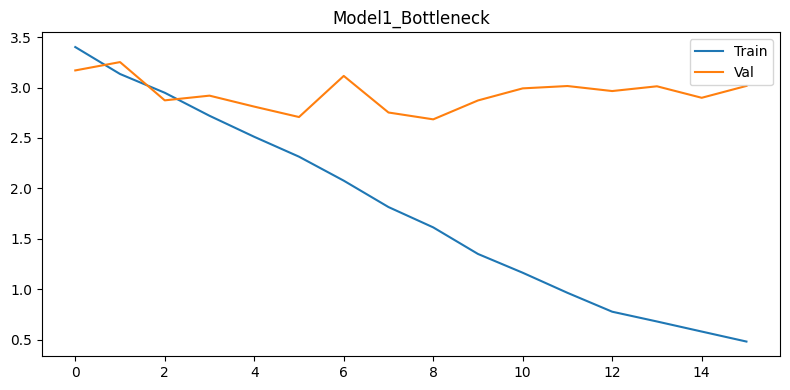


--- Model1_Bottleneck Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7759    0.9030    0.8346       299
     Modic 2     0.7500    0.5273    0.6192       165

    accuracy                         0.7694       464
   macro avg     0.7629    0.7151    0.7269       464
weighted avg     0.7667    0.7694    0.7580       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5556    0.4000    0.4651        75
          P2     0.4231    0.4944    0.4560        89
          P3     0.4884    0.6087    0.5419       138
          P4     0.4762    0.5051    0.4902        99
          P5     0.7931    0.3651    0.5000        63

    accuracy                         0.4978       464
   macro avg     0.5473    0.4746    0.4906       464
weighted avg     0.5255    0.4978    0.4963       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.7826  

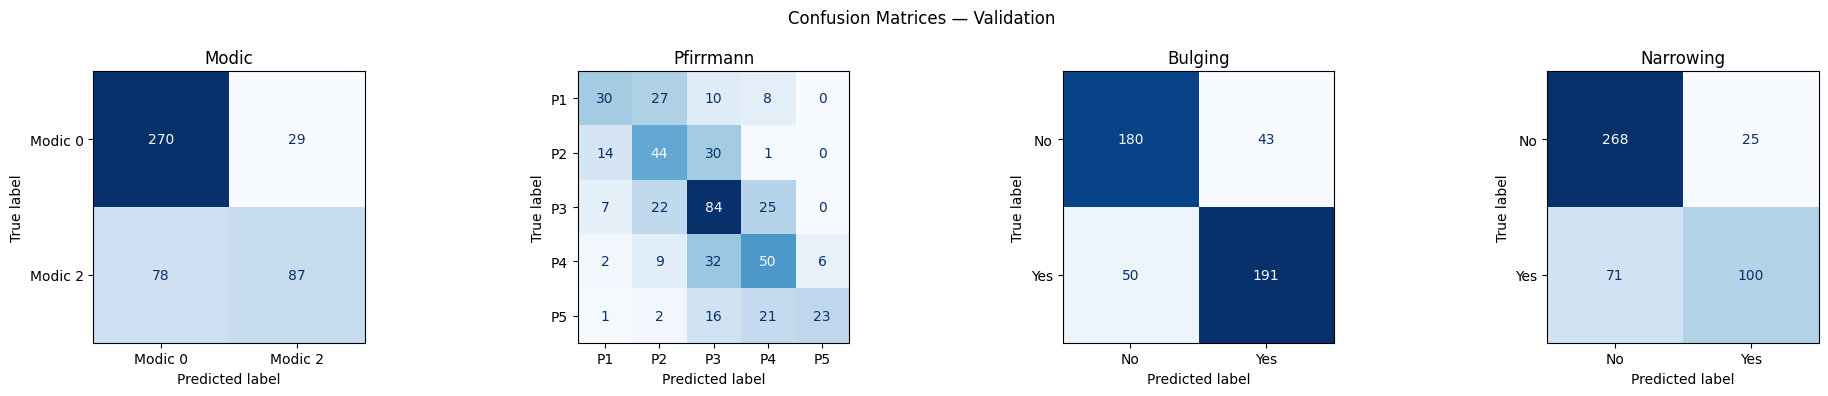

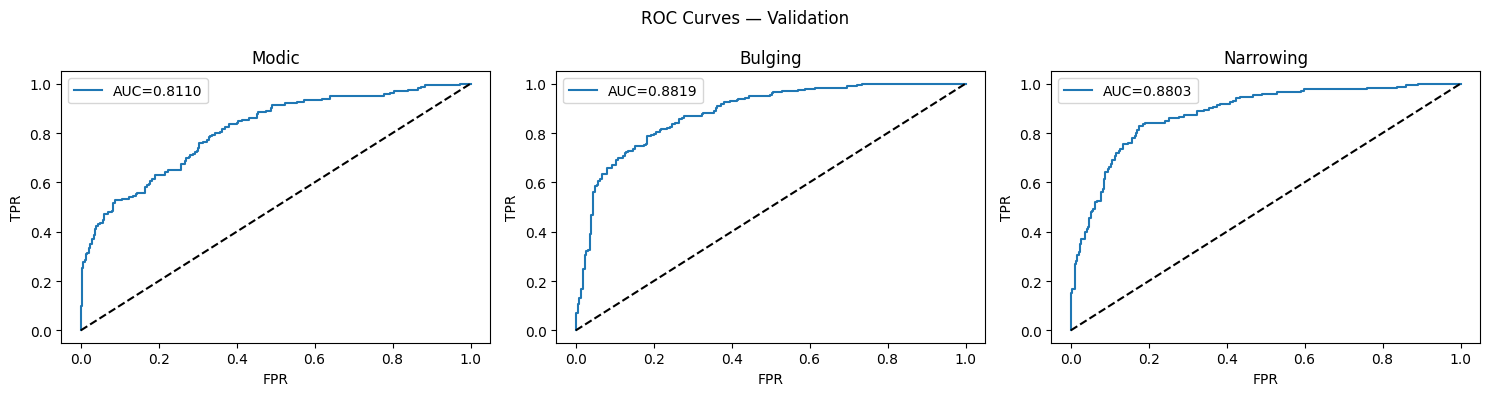


--- Model1_Bottleneck Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7527    0.9264    0.8306       299
     Modic 2     0.7732    0.4518    0.5703       166

    accuracy                         0.7570       465
   macro avg     0.7630    0.6891    0.7005       465
weighted avg     0.7600    0.7570    0.7377       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.6000    0.5143    0.5538        70
          P2     0.4579    0.4261    0.4414       115
          P3     0.4789    0.6691    0.5583       136
          P4     0.4337    0.4000    0.4162        90
          P5     0.6800    0.3148    0.4304        54

    accuracy                         0.4925       465
   macro avg     0.5301    0.4649    0.4800       465
weighted avg     0.5066    0.4925    0.4864       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8058    0.8193    0.8125      

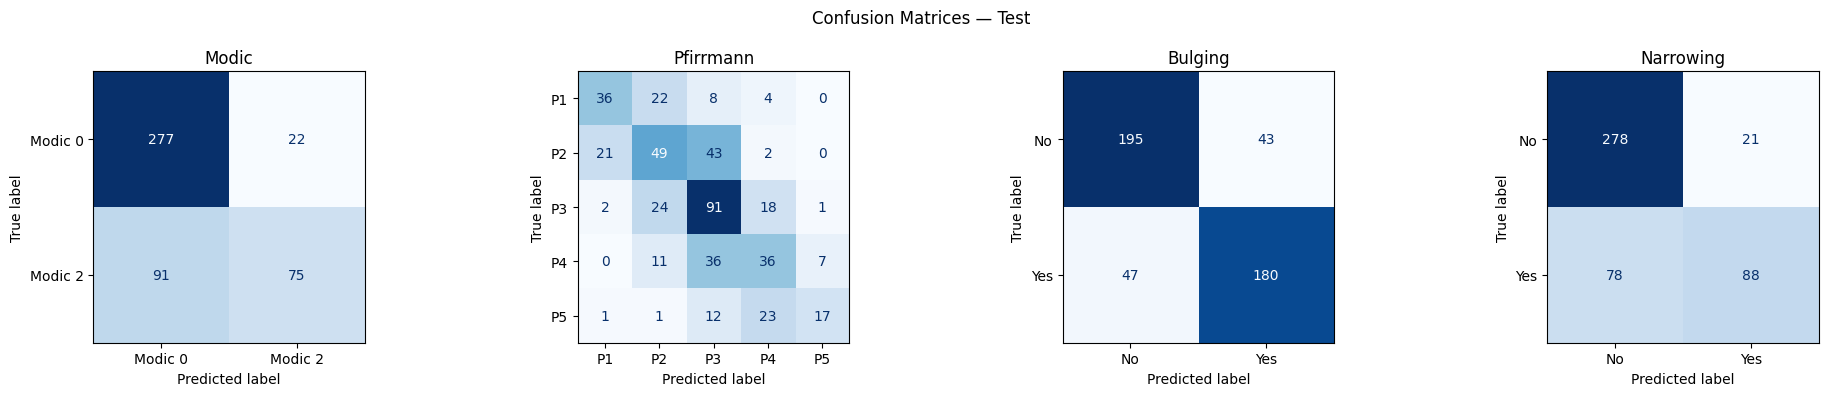

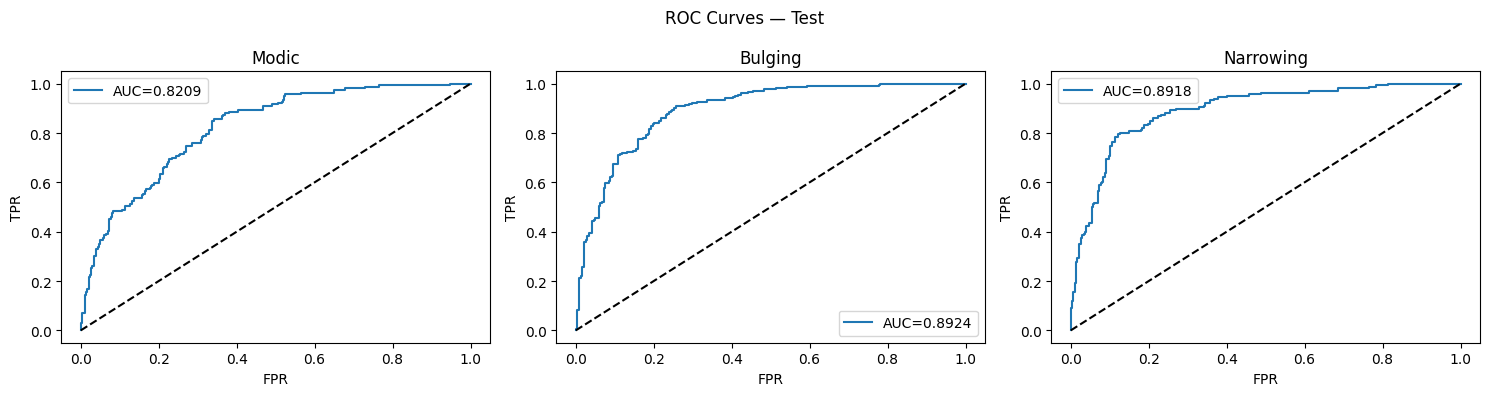


  Model2_SEEncoder  |  params: 15,839,379
Epoch 01/25  |  Train 3.3672  |  Val 3.0896
  ✔ Saved
Epoch 02/25  |  Train 3.1147  |  Val 3.1089
Epoch 03/25  |  Train 2.9715  |  Val 2.8733
  ✔ Saved
Epoch 04/25  |  Train 2.8471  |  Val 2.7916
  ✔ Saved
Epoch 05/25  |  Train 2.6729  |  Val 2.7571
  ✔ Saved
Epoch 06/25  |  Train 2.4739  |  Val 2.5671
  ✔ Saved
Epoch 07/25  |  Train 2.3188  |  Val 2.5149
  ✔ Saved
Epoch 08/25  |  Train 2.1535  |  Val 2.5648
Epoch 09/25  |  Train 1.9896  |  Val 2.4033
  ✔ Saved
Epoch 10/25  |  Train 1.8389  |  Val 2.3562
  ✔ Saved
Epoch 11/25  |  Train 1.6806  |  Val 2.2348
  ✔ Saved
Epoch 12/25  |  Train 1.4795  |  Val 2.2105
  ✔ Saved
Epoch 13/25  |  Train 1.2778  |  Val 2.3118
Epoch 14/25  |  Train 1.1273  |  Val 2.1439
  ✔ Saved
Epoch 15/25  |  Train 0.9255  |  Val 2.0531
  ✔ Saved
Epoch 16/25  |  Train 0.7931  |  Val 2.1135
Epoch 17/25  |  Train 0.6777  |  Val 2.2647
Epoch 18/25  |  Train 0.6000  |  Val 2.0602
Epoch 19/25  |  Train 0.5176  |  Val 2.0013
 

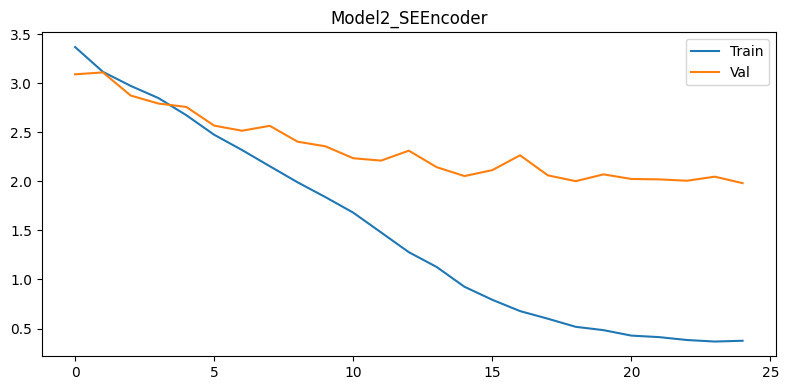


--- Model2_SEEncoder Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8954    0.9164    0.9058       299
     Modic 2     0.8418    0.8061    0.8235       165

    accuracy                         0.8772       464
   macro avg     0.8686    0.8612    0.8647       464
weighted avg     0.8763    0.8772    0.8765       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.8727    0.6400    0.7385        75
          P2     0.6250    0.6180    0.6215        89
          P3     0.6082    0.7536    0.6731       138
          P4     0.6383    0.6061    0.6218        99
          P5     0.7321    0.6508    0.6891        63

    accuracy                         0.6638       464
   macro avg     0.6953    0.6537    0.6688       464
weighted avg     0.6774    0.6638    0.6650       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8804   

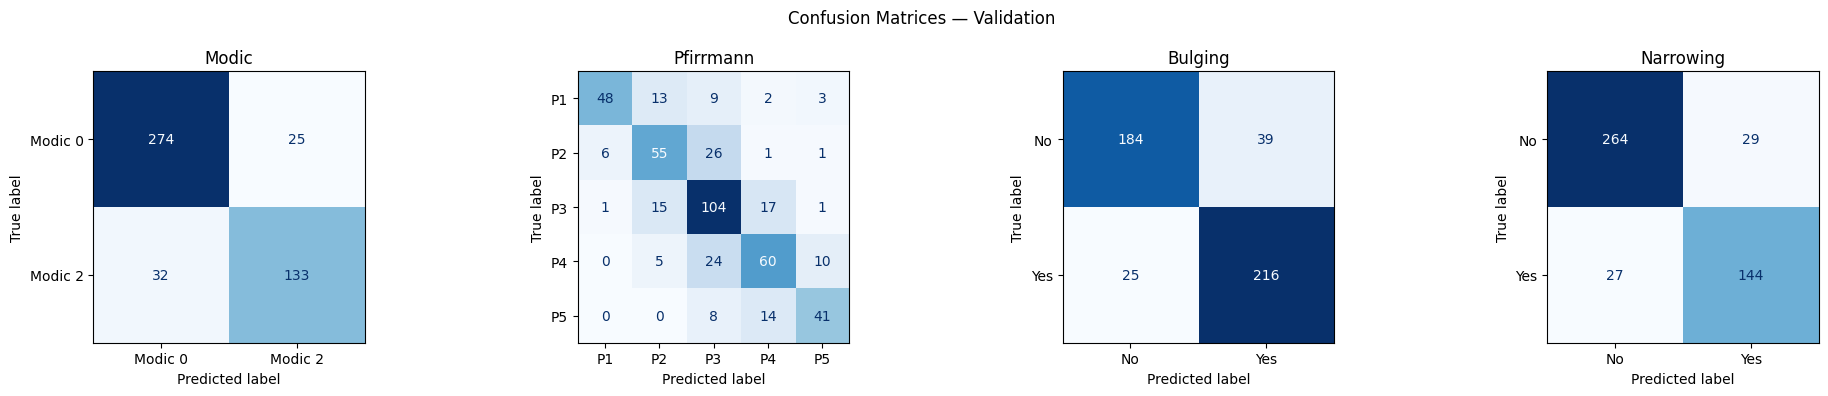

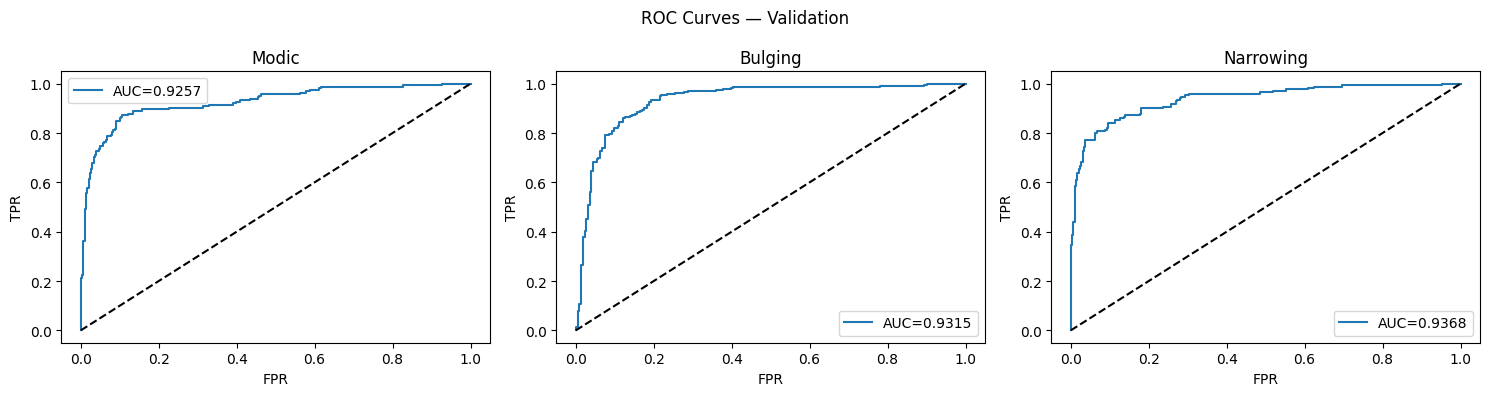


--- Model2_SEEncoder Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8742    0.9298    0.9011       299
     Modic 2     0.8571    0.7590    0.8051       166

    accuracy                         0.8688       465
   macro avg     0.8657    0.8444    0.8531       465
weighted avg     0.8681    0.8688    0.8669       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.8519    0.6571    0.7419        70
          P2     0.7292    0.6087    0.6635       115
          P3     0.6000    0.8162    0.6916       136
          P4     0.7159    0.7000    0.7079        90
          P5     0.7619    0.5926    0.6667        54

    accuracy                         0.6925       465
   macro avg     0.7318    0.6749    0.6943       465
weighted avg     0.7111    0.6925    0.6925       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9336    0.8866    0.9095       

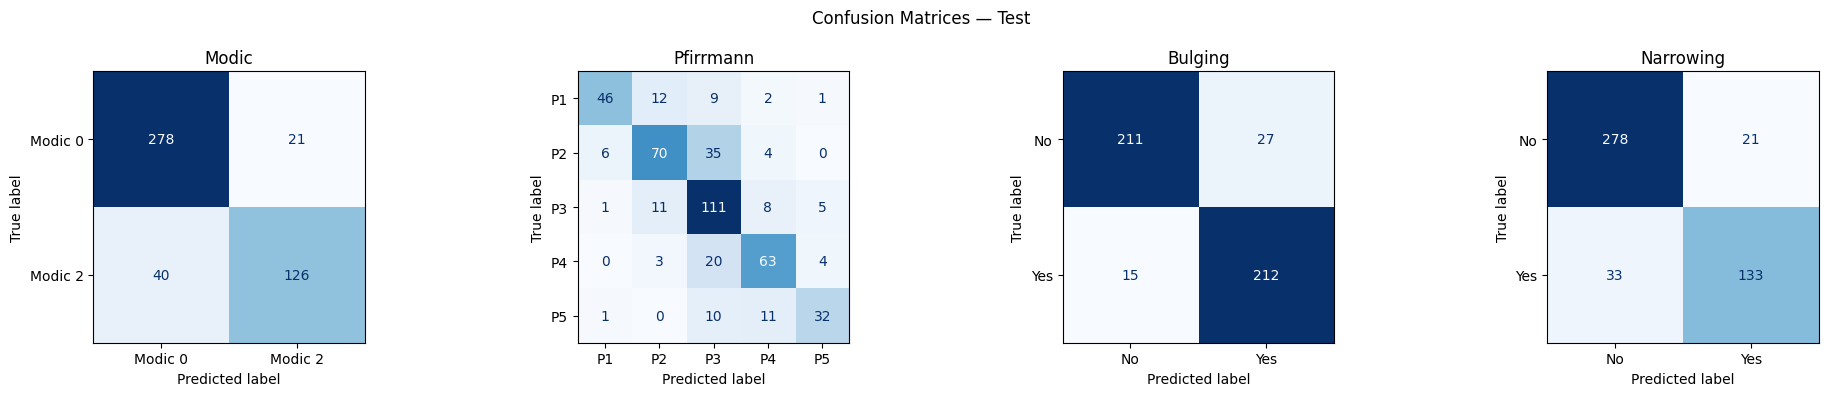

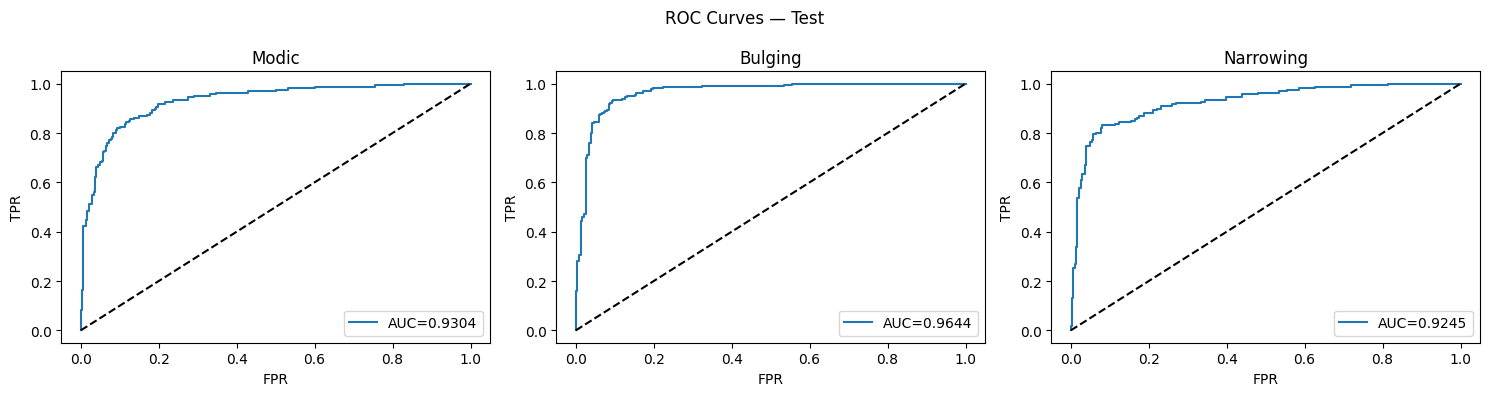


  Model3_DeeperPfHead  |  params: 15,860,631
Epoch 01/25  |  Train 3.3914  |  Val 3.1146
  ✔ Saved
Epoch 02/25  |  Train 3.1719  |  Val 3.0278
  ✔ Saved
Epoch 03/25  |  Train 2.9989  |  Val 2.9153
  ✔ Saved
Epoch 04/25  |  Train 2.8841  |  Val 2.8588
  ✔ Saved
Epoch 05/25  |  Train 2.7084  |  Val 2.7787
  ✔ Saved
Epoch 06/25  |  Train 2.5144  |  Val 2.6647
  ✔ Saved
Epoch 07/25  |  Train 2.4117  |  Val 2.5909
  ✔ Saved
Epoch 08/25  |  Train 2.1963  |  Val 2.9544
Epoch 09/25  |  Train 2.0434  |  Val 2.6948
Epoch 10/25  |  Train 1.8545  |  Val 2.4798
  ✔ Saved
Epoch 11/25  |  Train 1.6041  |  Val 2.3842
  ✔ Saved
Epoch 12/25  |  Train 1.3984  |  Val 2.4095
Epoch 13/25  |  Train 1.1902  |  Val 2.2930
  ✔ Saved
Epoch 14/25  |  Train 0.9979  |  Val 2.3368
Epoch 15/25  |  Train 0.8704  |  Val 2.3474
Epoch 16/25  |  Train 0.7366  |  Val 2.4623
Epoch 17/25  |  Train 0.6461  |  Val 2.3286
Epoch 18/25  |  Train 0.5783  |  Val 2.3730
Epoch 19/25  |  Train 0.4946  |  Val 2.3722
Epoch 20/25  |  Tr

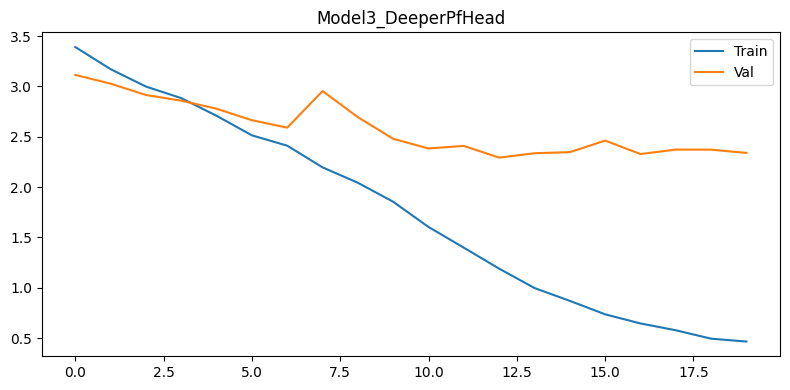


--- Model3_DeeperPfHead Validation ---

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8571    0.8829    0.8699       299
     Modic 2     0.7756    0.7333    0.7539       165

    accuracy                         0.8297       464
   macro avg     0.8164    0.8081    0.8119       464
weighted avg     0.8282    0.8297    0.8286       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.6308    0.5467    0.5857        75
          P2     0.5325    0.4607    0.4940        89
          P3     0.5390    0.6014    0.5685       138
          P4     0.5333    0.5657    0.5490        99
          P5     0.6190    0.6190    0.6190        63

    accuracy                         0.5603       464
   macro avg     0.5709    0.5587    0.5633       464
weighted avg     0.5622    0.5603    0.5597       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8950

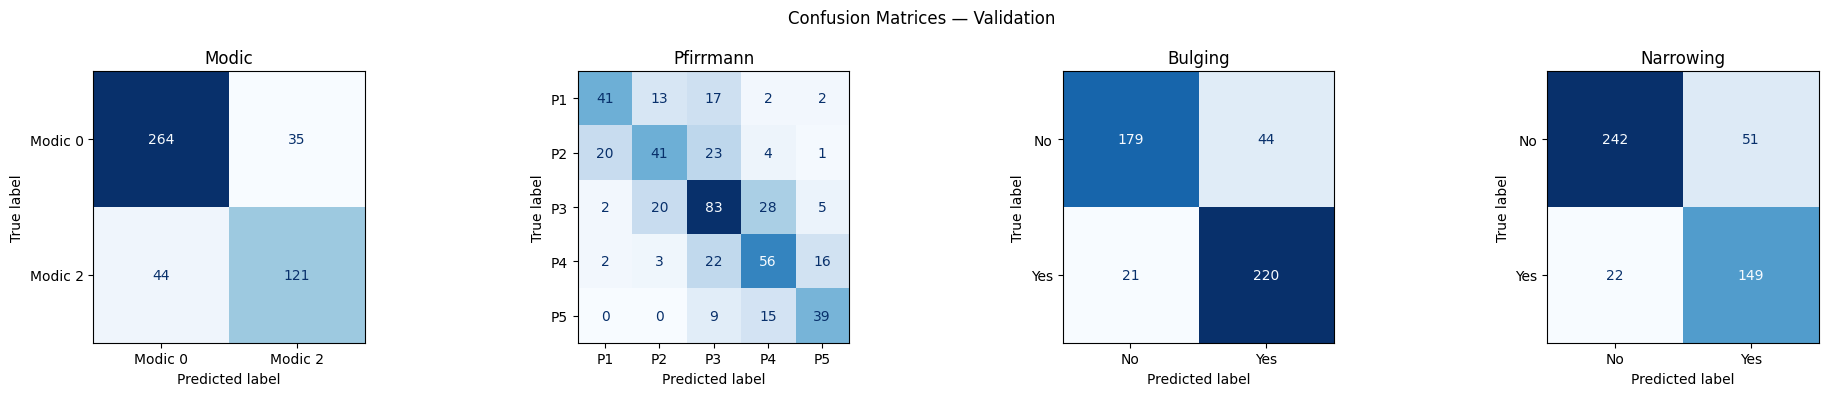

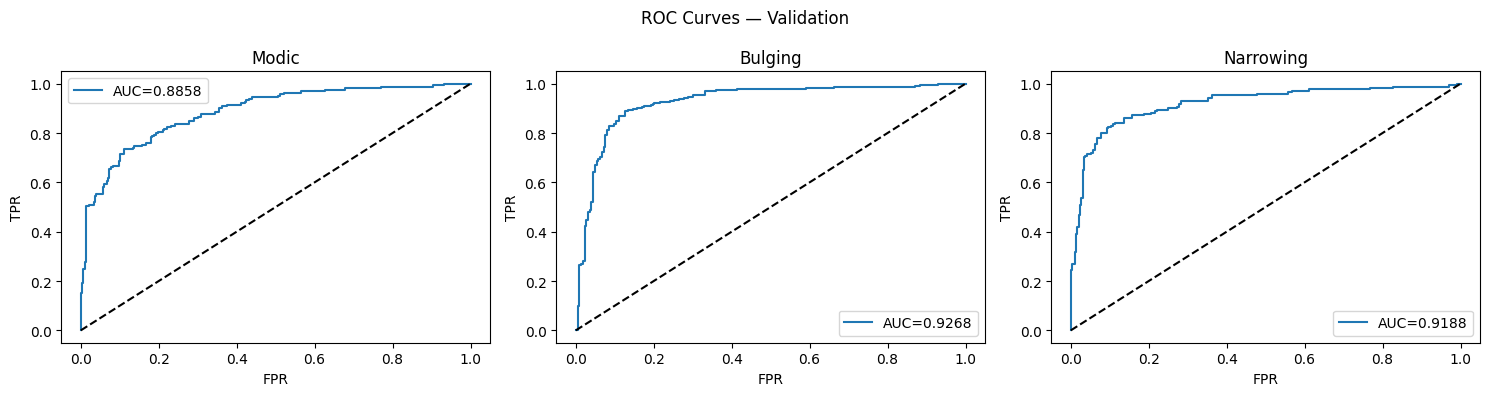


--- Model3_DeeperPfHead Test ---

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8462    0.8829    0.8642       299
     Modic 2     0.7712    0.7108    0.7398       166

    accuracy                         0.8215       465
   macro avg     0.8087    0.7969    0.8020       465
weighted avg     0.8194    0.8215    0.8198       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.6000    0.5571    0.5778        70
          P2     0.5488    0.3913    0.4569       115
          P3     0.5233    0.6618    0.5844       136
          P4     0.5955    0.5889    0.5922        90
          P5     0.5965    0.6296    0.6126        54

    accuracy                         0.5613       465
   macro avg     0.5728    0.5657    0.5648       465
weighted avg     0.5636    0.5613    0.5566       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9052    0.8025    0.8508    

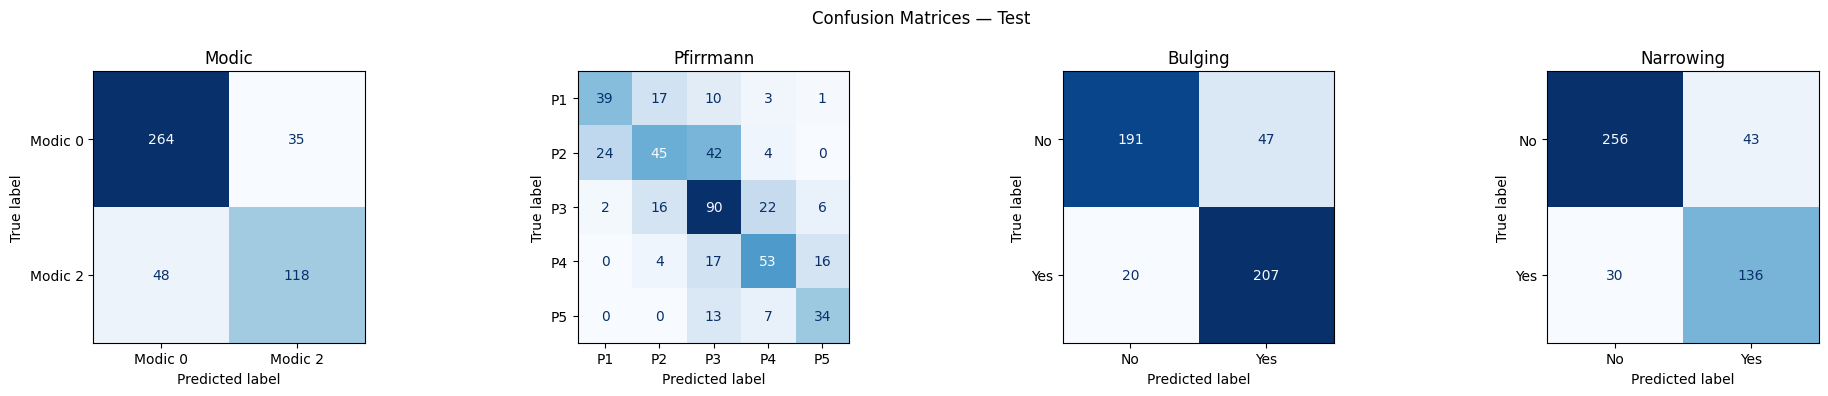

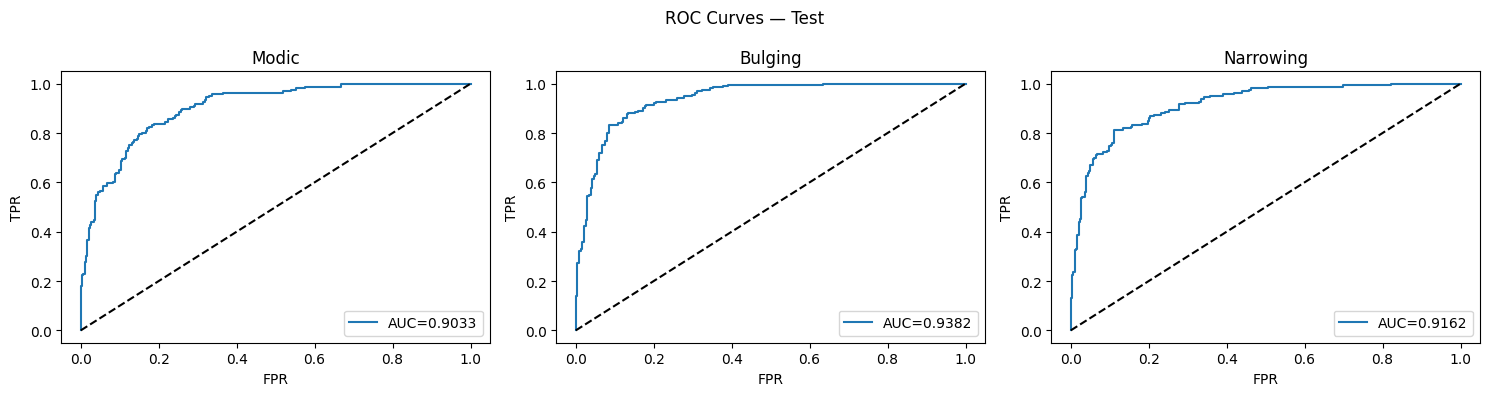

In [6]:
import os
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/kiranps24/lumbar-spine-disclevel/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 7   # increased from 5 — models need more time


# =========================================================
# DATASET — identical to best model
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        image = (image - image.mean()) / (image.std() + 1e-6)
        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))
        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# SPLIT
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid: {len(valid_files)}")
train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42)
print(f"Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding datasets...")
train_ds = DiscDataset(train_files)
val_ds   = DiscDataset(val_files)
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# SHARED BLOCKS — identical to best model
# =========================================================
class CBAM3D(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels, max(1, channels // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, channels // reduction), channels)
        )
        self.spatial_conv = nn.Conv3d(2, 1, 7, padding=3, bias=False)

    def forward(self, x):
        B, C, D, H, W = x.shape
        avg_c = F.adaptive_avg_pool3d(x, 1).view(B, C)
        max_c = F.adaptive_max_pool3d(x, 1).view(B, C)
        ch = torch.sigmoid(
            self.channel_mlp(avg_c) + self.channel_mlp(max_c)
        ).view(B, C, 1, 1, 1)
        x = x * ch
        sp = torch.sigmoid(self.spatial_conv(
            torch.cat([x.mean(1, keepdim=True),
                       x.max(1, keepdim=True).values], 1)
        ))
        return x * sp


class ASPP3D(nn.Module):
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=6,
                      dilation=6, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=12,
                      dilation=12, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=18,
                      dilation=18, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.project = nn.Sequential(
            nn.Conv3d(out_ch * 4, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(),
            nn.Dropout3d(0.1))

    def forward(self, x):
        return self.project(torch.cat([
            self.b1(x), self.b2(x), self.b3(x), self.b4(x)
        ], dim=1))


# =========================================================
# LOSS — identical to best model, no changes
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# MODEL 1 — Original + bottleneck residual encoder
# =========================================================
# The original has 1 conv per stage. A bottleneck ResBlock
# uses 1x1 to compress, 3x3 to mix, 1x1 to expand —
# this gives 3 nonlinearities per stage vs 1, without
# increasing the spatial conv cost. Residual skip gives
# Pfirrmann gradient a direct path to early layers.
# =========================================================
class Bottleneck3D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        mid = out_ch // 4
        self.conv = nn.Sequential(
            nn.Conv3d(in_ch, mid, 1, bias=False),
            nn.BatchNorm3d(mid), nn.ReLU(inplace=True),
            nn.Conv3d(mid, mid, 3, stride=stride,
                      padding=1, bias=False),
            nn.BatchNorm3d(mid), nn.ReLU(inplace=True),
            nn.Conv3d(mid, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch),
        )
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, stride=stride,
                      bias=False),
            nn.BatchNorm3d(out_ch)
        ) if stride != 1 or in_ch != out_ch else nn.Identity()
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.conv(x) + self.skip(x))


class Model1_Bottleneck(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            Bottleneck3D(1,   64,  stride=2),
            Bottleneck3D(64,  128, stride=2),
            Bottleneck3D(128, 256, stride=2),
            Bottleneck3D(256, 512, stride=2),
        )
        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.head_modic     = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging   = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.dropout(self.pool(x).flatten(1))
        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# MODEL 2 — Original + CBAM after every encoder stage
# =========================================================
# The original applies CBAM once at enc4 (stride-16).
# Adding SE-style channel recalibration after every stage
# means each stage output is focused on disc-relevant
# channels before being passed to the next stage.
# SE is lighter than full CBAM — just channel attention,
# no spatial — so it adds minimal parameters per stage.
# =========================================================
class SE3D(nn.Module):
    def __init__(self, ch, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(ch, max(1, ch // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, ch // reduction), ch),
            nn.Sigmoid()
        )
    def forward(self, x):
        B, C = x.shape[:2]
        w = F.adaptive_avg_pool3d(x, 1).view(B, C)
        return x * self.fc(w).view(B, C, 1, 1, 1)


def cbr(in_ch, out_ch, stride=1):
    return nn.Sequential(
        nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                  padding=1, bias=False),
        nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True)
    )


class Model2_SEEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(cbr(1,   64,  stride=2), SE3D(64))
        self.enc2 = nn.Sequential(cbr(64,  128, stride=2), SE3D(128))
        self.enc3 = nn.Sequential(cbr(128, 256, stride=2), SE3D(256))
        self.enc4 = nn.Sequential(cbr(256, 512, stride=2), SE3D(512))
        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.head_modic     = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging   = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.enc1(x)
        x = self.enc2(x)
        x = self.enc3(x)
        x = self.enc4(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.dropout(self.pool(x).flatten(1))
        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# MODEL 3 — Original + deeper Pfirrmann head only
# =========================================================
# Isolates whether the head is the bottleneck.
# Encoder, CBAM, ASPP: byte-for-byte identical to original.
# Only the Pfirrmann head gets an extra layer + dropout.
# If this matches or beats Models 1-2, the bottleneck
# is the head capacity, not the encoder.
# =========================================================
class Model3_DeeperPfHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            cbr(1,   64,  stride=2),
            cbr(64,  128, stride=2),
            cbr(128, 256, stride=2),
            cbr(256, 512, stride=2),
        )
        self.attn    = CBAM3D(512)
        self.aspp    = ASPP3D(512, 256)
        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)
        self.head_modic     = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_bulging   = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))
        # Deeper Pfirrmann head — only change from original
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.attn(x)
        x = self.aspp(x)
        x = self.dropout(self.pool(x).flatten(1))
        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# TRAIN / EVAL
# =========================================================
def run_epoch(model, loader, optimizer, scaler, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


def train_model(model, name, ckpt):
    print(f"\n{'='*60}")
    n = sum(p.numel() for p in model.parameters()
            if p.requires_grad)
    print(f"  {name}  |  params: {n:,}")
    print('='*60)

    opt = torch.optim.AdamW(model.parameters(),
                             lr=LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=EPOCHS)
    scaler = GradScaler(enabled=True)

    best_val = np.inf; counter = 0
    tl_h, vl_h = [], []

    for epoch in range(EPOCHS):
        tr = run_epoch(model, train_loader,
                       opt, scaler, train=True)
        vl = run_epoch(model, val_loader,
                       opt, scaler, train=False)
        sch.step()
        tl_h.append(tr); vl_h.append(vl)
        print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
              f"Train {tr:.4f}  |  Val {vl:.4f}")
        if vl < best_val:
            best_val = vl; counter = 0
            torch.save(model.state_dict(), ckpt)
            print("  ✔ Saved")
        else:
            counter += 1
            if counter >= PATIENCE:
                print("Early stopping."); break
        gc.collect(); torch.cuda.empty_cache()

    plt.figure(figsize=(8, 4))
    plt.plot(tl_h, label="Train")
    plt.plot(vl_h, label="Val")
    plt.title(name); plt.legend()
    plt.tight_layout(); plt.show()
    return ckpt


def evaluate(model, ckpt, loader, split_name="Test"):
    model.load_state_dict(
        torch.load(ckpt, map_location=device))
    model.eval()
    preds = {k: [] for k in
             ["modic","pfirrmann","bulging","narrowing"]}
    probs = {k: [] for k in ["modic","bulging","narrowing"]}
    gts   = {k: [] for k in
             ["modic","pfirrmann","bulging","narrowing"]}
    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)
            probs["modic"].extend(
                torch.softmax(out["modic"],1)[:,1].cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())
            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())
            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b>0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())
            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n>0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":    (["Modic 0","Modic 2"],
                     f"\nMODIC — {split_name}"),
        "pfirrmann":([f"P{i+1}" for i in range(5)],
                     f"\nPFIRRMANN — {split_name}"),
        "bulging":  (["No","Yes"],
                     f"\nBULGING — {split_name}"),
        "narrowing":(["No","Yes"],
                     f"\nNARROWING — {split_name}"),
    }
    for task,(names,title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i<len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1,4,figsize=(20,4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax,(task,(names,_)) in zip(axes,task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i<len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task],preds[task]),
            display_labels=used
        ).plot(ax=ax,colorbar=False,cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1,3,figsize=(15,4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax,task in zip(axes,["modic","bulging","narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr))<2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr,tpr,_ = roc_curve(gt_arr,prob_arr)
        ax.plot(fpr,tpr,label=f"AUC={auc(fpr,tpr):.4f}")
        ax.plot([0,1],[0,1],"k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


# =========================================================
# RUN
# =========================================================
models_to_run = [
    (Model1_Bottleneck(),    "Model1_Bottleneck",    "best_m1.pth"),
    (Model2_SEEncoder(),     "Model2_SEEncoder",     "best_m2.pth"),
    (Model3_DeeperPfHead(),  "Model3_DeeperPfHead",  "best_m3.pth"),
]

for model, name, ckpt in models_to_run:
    model = model.to(device)
    ckpt  = train_model(model, name, ckpt)
    print(f"\n--- {name} Validation ---")
    evaluate(model, ckpt, val_loader,  "Validation")
    print(f"\n--- {name} Test ---")
    evaluate(model, ckpt, test_loader, "Test")
    del model; torch.cuda.empty_cache(); gc.collect()

**DeepLabV3Plus3D_Attn Ensemble (5-model ensemble)**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Valid: 3095
Train:2166 Val:464 Test:465
  Loaded 2166 | skipped 0
  Loaded 464 | skipped 0
  Loaded 465 | skipped 0

  Member 1 | seed=42
Epoch 01/25  Train 3.3497  Val 3.1254
  ✔ Saved
Epoch 02/25  Train 3.1491  Val 3.0481
  ✔ Saved
Epoch 03/25  Train 3.0371  Val 2.8640
  ✔ Saved
Epoch 04/25  Train 2.8446  Val 2.7718
  ✔ Saved
Epoch 05/25  Train 2.6541  Val 2.6617
  ✔ Saved
Epoch 06/25  Train 2.4393  Val 2.7207
Epoch 07/25  Train 2.3005  Val 2.6464
  ✔ Saved
Epoch 08/25  Train 2.1064  Val 2.5090
  ✔ Saved
Epoch 09/25  Train 1.8835  Val 2.3975
  ✔ Saved
Epoch 10/25  Train 1.6371  Val 2.3453
  ✔ Saved
Epoch 11/25  Train 1.4735  Val 2.3619
Epoch 12/25  Train 1.2917  Val 2.4358
Epoch 13/25  Train 1.0963  Val 2.2557
  ✔ Saved
Epoch 14/25  Train 0.9395  Val 2.3008
Epoch 15/25  Train 0.8267  Val 2.4061
Epoch 16/25  Train 0.7067  Val 2.2965
Epoch 17/25  Train 0.6181  Val 2.2332
  ✔ Saved
Epoch 18/25  Train 0.5407  Val 2.2254
  ✔ Saved
Epoch 19/25  

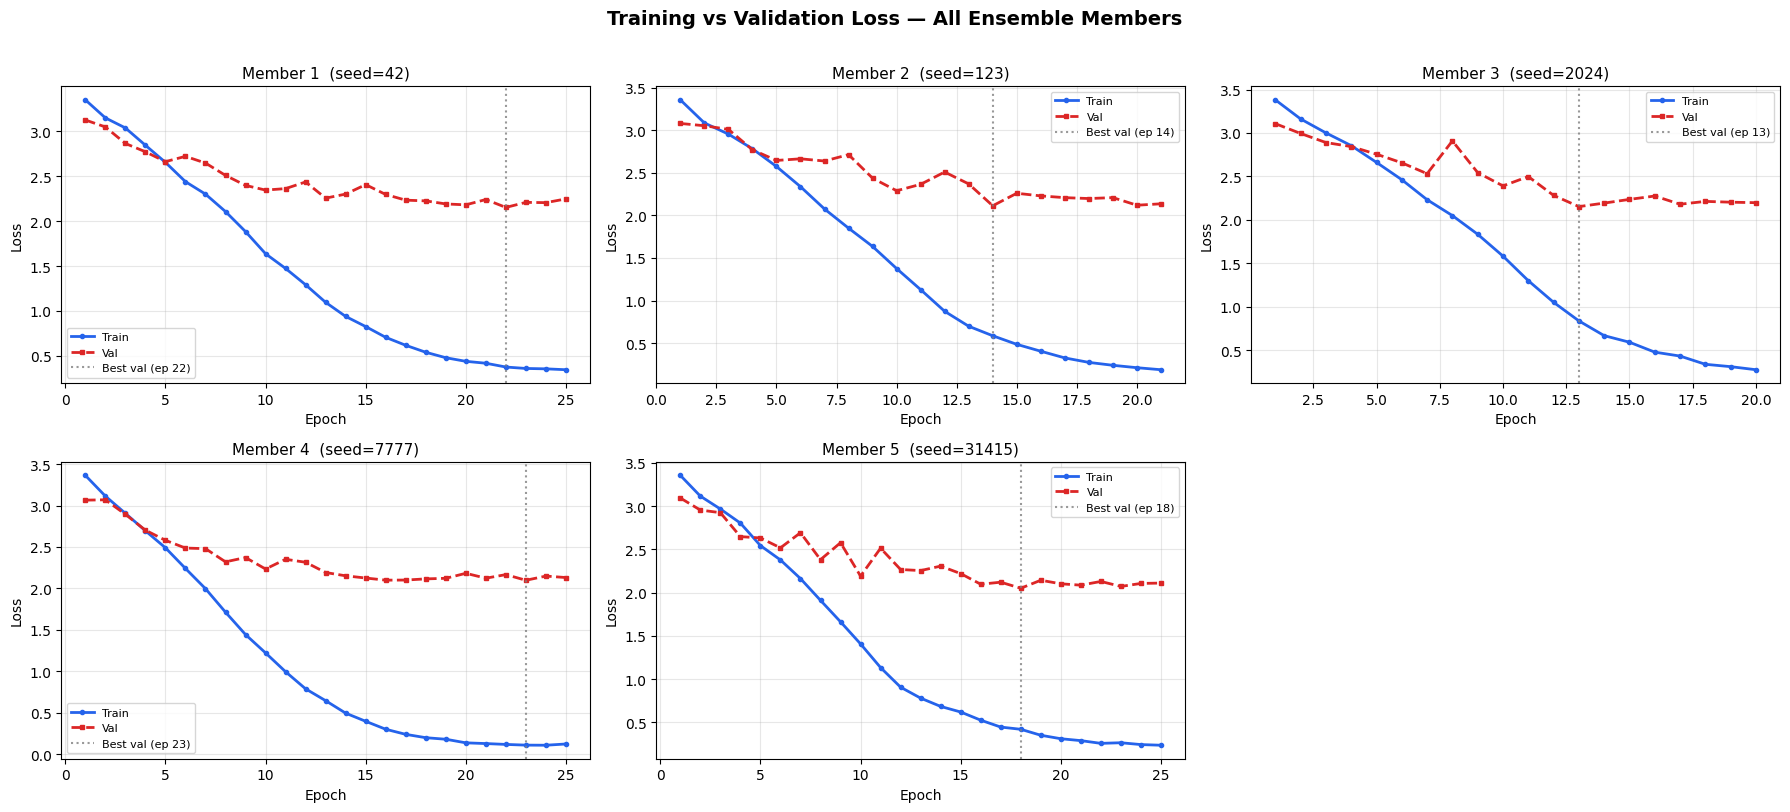

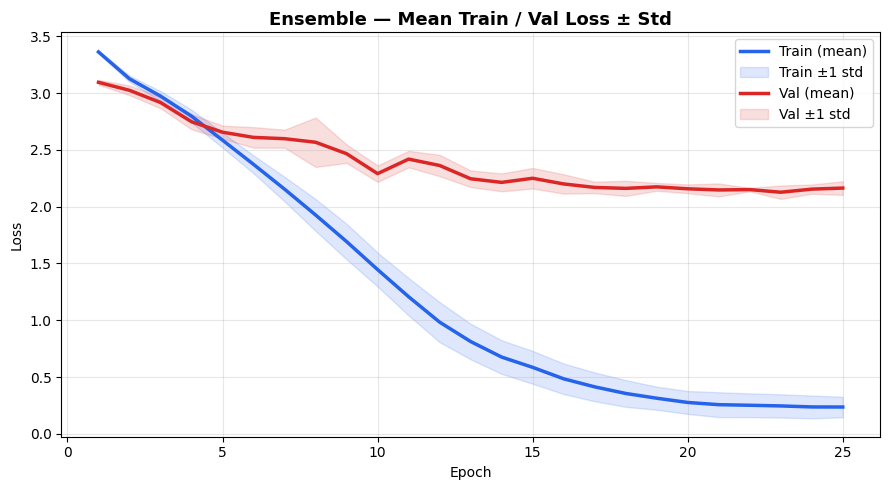

Loss curve plots saved: loss_curves_per_member.png | loss_curves_aggregate.png

ENSEMBLE EVALUATION (no TTA)

Validation:

MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8961    0.9231    0.9094       299
     Modic 2     0.8526    0.8061    0.8287       165

    accuracy                         0.8815       464
   macro avg     0.8743    0.8646    0.8690       464
weighted avg     0.8806    0.8815    0.8807       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.8125    0.6933    0.7482        75
          P2     0.6742    0.6742    0.6742        89
          P3     0.6579    0.7246    0.6897       138
          P4     0.6566    0.6566    0.6566        99
          P5     0.7167    0.6825    0.6992        63

    accuracy                         0.6897       464
   macro avg     0.7036    0.6862    0.6936       464
weighted avg     0.6937    0.6897    0.6904       464


BULGING — Validat

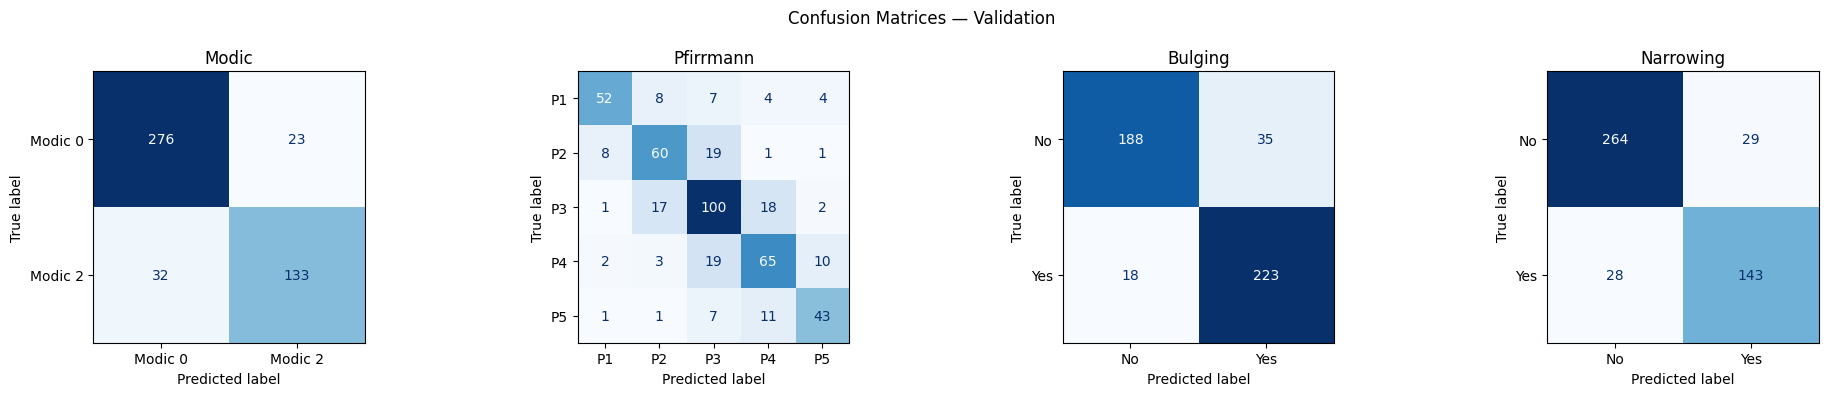

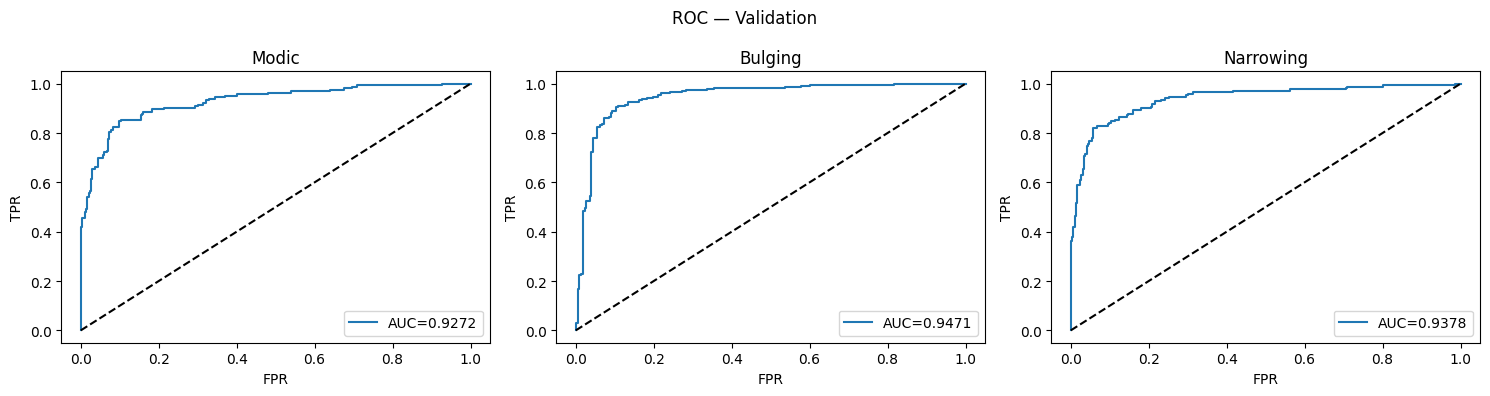


Test:

MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.8762    0.9231    0.8990       299
     Modic 2     0.8467    0.7651    0.8038       166

    accuracy                         0.8667       465
   macro avg     0.8614    0.8441    0.8514       465
weighted avg     0.8657    0.8667    0.8650       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.8500    0.7286    0.7846        70
          P2     0.7525    0.6609    0.7037       115
          P3     0.6497    0.8456    0.7348       136
          P4     0.7805    0.7111    0.7442        90
          P5     0.7333    0.6111    0.6667        54

    accuracy                         0.7290       465
   macro avg     0.7532    0.7115    0.7268       465
weighted avg     0.7403    0.7290    0.7285       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.9217    0.8908    0.9060       238
         Yes     0.8

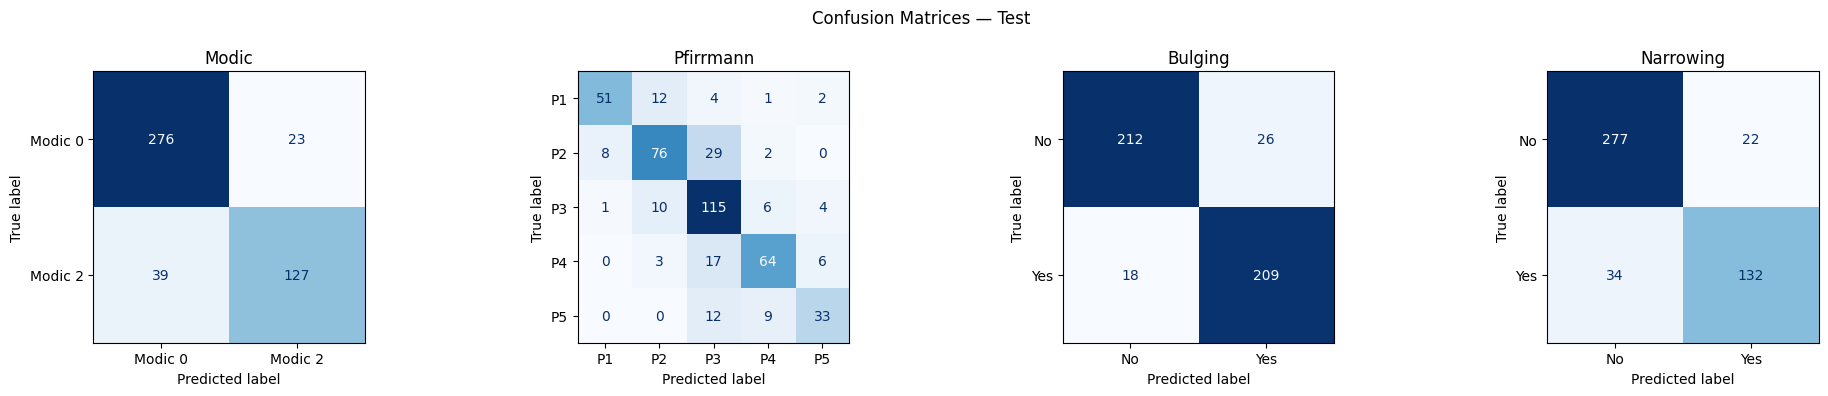

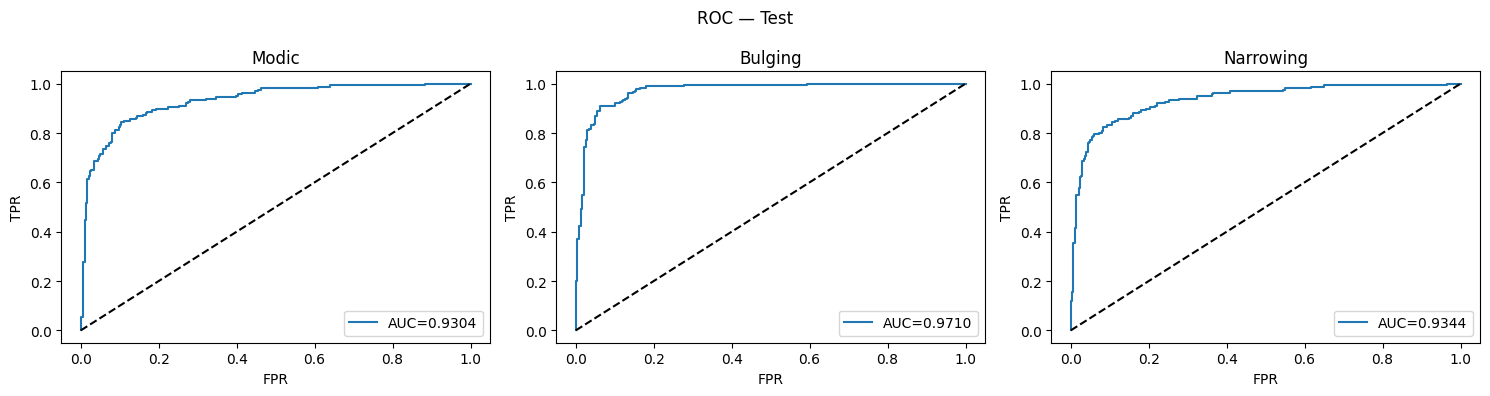

In [1]:
import os
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/kiranps24/lumbar-spine-disclevel/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 7
N_ENSEMBLE   = 5
SEEDS        = [42, 123, 2024, 7777, 31415]


# =========================================================
# DATASET — NO AUGMENTATION (same as DenseNet3D winner)
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))
        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# SPLIT
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid: {len(valid_files)}")
train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42)
print(f"Train:{len(train_files)} Val:{len(val_files)} "
      f"Test:{len(test_files)}")

train_ds = DiscDataset(train_files)
val_ds   = DiscDataset(val_files)
test_ds  = DiscDataset(test_files)

# Fixed loaders — shuffle=True, no sampler
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2,
                          pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2,
                          pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2,
                          pin_memory=True)


# =========================================================
# MODEL — identical to DenseNet3D winner
# =========================================================
class CBAM3D(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels, max(1, channels // reduction)),
            nn.ReLU(),
            nn.Linear(max(1, channels // reduction), channels)
        )
        self.spatial_conv = nn.Conv3d(2, 1, 7, padding=3,
                                      bias=False)

    def forward(self, x):
        B, C, D, H, W = x.shape
        avg_c = F.adaptive_avg_pool3d(x, 1).view(B, C)
        max_c = F.adaptive_max_pool3d(x, 1).view(B, C)
        ch = torch.sigmoid(
            self.channel_mlp(avg_c) + self.channel_mlp(max_c)
        ).view(B, C, 1, 1, 1)
        x = x * ch
        sp = torch.sigmoid(self.spatial_conv(
            torch.cat([x.mean(1, keepdim=True),
                       x.max(1, keepdim=True).values], 1)
        ))
        return x * sp


class ASPP3D(nn.Module):
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=6,
                      dilation=6, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=12,
                      dilation=12, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=18,
                      dilation=18, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU())
        self.project = nn.Sequential(
            nn.Conv3d(out_ch * 4, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(),
            nn.Dropout3d(0.1))

    def forward(self, x):
        return self.project(torch.cat([
            self.b1(x), self.b2(x),
            self.b3(x), self.b4(x)
        ], dim=1))


def make_model():
    class DeepLabV3Plus3D_Attn(nn.Module):
        def __init__(self):
            super().__init__()

            def cbr(in_ch, out_ch, stride=1):
                return nn.Sequential(
                    nn.Conv3d(in_ch, out_ch, 3, stride=stride,
                              padding=1, bias=False),
                    nn.BatchNorm3d(out_ch),
                    nn.ReLU(inplace=True)
                )

            self.encoder = nn.Sequential(
                cbr(1,   64,  stride=2),
                cbr(64,  128, stride=2),
                cbr(128, 256, stride=2),
                cbr(256, 512, stride=2),
            )
            self.attn    = CBAM3D(512)
            self.aspp    = ASPP3D(512, 256)
            self.pool    = nn.AdaptiveAvgPool3d(1)
            self.dropout = nn.Dropout(0.3)
            self.head_modic     = nn.Sequential(
                nn.Linear(256, 128), nn.ReLU(),
                nn.Linear(128, 2))
            self.head_pfirrmann = nn.Sequential(
                nn.Linear(256, 128), nn.ReLU(),
                nn.Linear(128, 5))
            self.head_bulging   = nn.Sequential(
                nn.Linear(256, 64), nn.ReLU(),
                nn.Linear(64, 1))
            self.head_narrowing = nn.Sequential(
                nn.Linear(256, 64), nn.ReLU(),
                nn.Linear(64, 1))

        def forward(self, x):
            x = self.encoder(x)
            x = self.attn(x)
            x = self.aspp(x)
            x = self.dropout(self.pool(x).flatten(1))
            return {
                "modic":     self.head_modic(x),
                "pfirrmann": self.head_pfirrmann(x),
                "bulging":   self.head_bulging(x).squeeze(1),
                "narrowing": self.head_narrowing(x).squeeze(1),
            }
    return DeepLabV3Plus3D_Attn()


ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN ONE MEMBER
# =========================================================
def train_one(seed, member_id):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = make_model().to(device)
    print(f"\n{'='*55}")
    print(f"  Member {member_id} | seed={seed}")
    print('='*55)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS)
    scaler = GradScaler(enabled=True)

    best_val = np.inf
    counter  = 0
    ckpt     = f"ens_m{member_id}_s{seed}.pth"

    train_losses = []   # track per-epoch train loss
    val_losses   = []   # track per-epoch val loss

    for epoch in range(EPOCHS):
        model.train()
        tr = 0.0
        for img, tgt in train_loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            optimizer.zero_grad()
            with autocast(device.type):
                loss = multitask_loss(model(img), tgt)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            tr += loss.item()
        tr /= max(len(train_loader), 1)

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for img, tgt in val_loader:
                img = img.to(device)
                tgt = {k: v.to(device) for k, v in tgt.items()}
                with autocast(device.type):
                    vl += multitask_loss(model(img), tgt).item()
        vl /= max(len(val_loader), 1)

        scheduler.step()

        train_losses.append(tr)   # record train loss
        val_losses.append(vl)     # record val loss

        print(f"Epoch {epoch+1:02d}/{EPOCHS}  "
              f"Train {tr:.4f}  Val {vl:.4f}")

        if vl < best_val:
            best_val = vl; counter = 0
            torch.save(model.state_dict(), ckpt)
            print("  ✔ Saved")
        else:
            counter += 1
            if counter >= PATIENCE:
                print("Early stopping."); break

        gc.collect(); torch.cuda.empty_cache()

    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()
    print(f"  Best val loss: {best_val:.4f}")
    return ckpt, model, train_losses, val_losses   # return histories


# =========================================================
# TRAIN ALL MEMBERS
# =========================================================
ensemble_ckpts   = []
ensemble_models  = []
all_train_losses = []   # collect histories across members
all_val_losses   = []

for i, seed in enumerate(SEEDS[:N_ENSEMBLE]):
    ckpt, model, tr_hist, vl_hist = train_one(seed, i + 1)
    ensemble_ckpts.append(ckpt)
    ensemble_models.append(model)
    all_train_losses.append(tr_hist)
    all_val_losses.append(vl_hist)


# =========================================================
# LOSS CURVE PLOTS
# =========================================================
def plot_loss_curves(all_train, all_val, seeds):
    """
    1) Per-member subplots: train vs val loss with best-epoch marker.
    2) Aggregate plot: mean ± std across all members.
    """
    n    = len(all_train)
    cols = min(n, 3)
    rows = (n + cols - 1) // cols

    # ── Per-member subplots ──────────────────────────────
    fig, axes = plt.subplots(rows, cols,
                             figsize=(6 * cols, 4 * rows),
                             squeeze=False)
    fig.suptitle("Training vs Validation Loss — All Ensemble Members",
                 fontsize=14, fontweight="bold", y=1.01)

    for i, (tr, vl) in enumerate(zip(all_train, all_val)):
        ax     = axes[i // cols][i % cols]
        epochs = range(1, len(tr) + 1)

        ax.plot(epochs, tr, label="Train", color="#2563EB",
                linewidth=2, marker="o", markersize=3)
        ax.plot(epochs, vl, label="Val",   color="#DC2626",
                linewidth=2, marker="s", markersize=3,
                linestyle="--")

        best_ep = int(np.argmin(vl)) + 1
        ax.axvline(best_ep, color="gray", linestyle=":",
                   alpha=0.8, label=f"Best val (ep {best_ep})")

        ax.set_title(f"Member {i + 1}  (seed={seeds[i]})",
                     fontsize=11)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    # Hide any unused subplot cells
    for j in range(n, rows * cols):
        axes[j // cols][j % cols].set_visible(False)

    plt.tight_layout()
    plt.savefig("loss_curves_per_member.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    # ── Aggregate plot: mean ± std ───────────────────────
    max_ep = max(len(t) for t in all_train)

    def pad_nan(lst):
        """Pad shorter histories with NaN so arrays align."""
        return np.array([
            np.pad(np.array(a, dtype=float),
                   (0, max_ep - len(a)),
                   constant_values=np.nan)
            for a in lst
        ])

    tr_arr = pad_nan(all_train)
    vl_arr = pad_nan(all_val)
    epochs = np.arange(1, max_ep + 1)

    fig, ax = plt.subplots(figsize=(9, 5))

    for arr, color, label in [
        (tr_arr, "#2563EB", "Train"),
        (vl_arr, "#DC2626", "Val"),
    ]:
        mu  = np.nanmean(arr, axis=0)
        std = np.nanstd(arr,  axis=0)
        ax.plot(epochs, mu, color=color, linewidth=2.5,
                label=f"{label} (mean)")
        ax.fill_between(epochs, mu - std, mu + std,
                        color=color, alpha=0.15,
                        label=f"{label} ±1 std")

    ax.set_title("Ensemble — Mean Train / Val Loss ± Std",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("loss_curves_aggregate.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print("Loss curve plots saved: "
          "loss_curves_per_member.png | loss_curves_aggregate.png")


plot_loss_curves(all_train_losses, all_val_losses, SEEDS[:N_ENSEMBLE])


# =========================================================
# ENSEMBLE INFERENCE — no TTA (TTA hurt via augmentation)
# =========================================================
def ensemble_predict(loader):
    n = len(loader.dataset)
    sum_modic = np.zeros((n, 2))
    sum_pf    = np.zeros((n, 5))
    sum_bul   = np.zeros(n)
    sum_nar   = np.zeros(n)

    gt_modic, gt_pf, gt_bul, gt_nar = [], [], [], []
    gts_done = False

    for model in ensemble_models:
        model.eval()
        offset = 0
        with torch.no_grad():
            for img, tgt in loader:
                img = img.to(device)
                B   = img.shape[0]
                if not gts_done:
                    gt_modic.extend(tgt["modic"].numpy())
                    gt_pf.extend(tgt["pfirrmann"].numpy())
                    gt_bul.extend(tgt["bulging"].long().numpy())
                    gt_nar.extend(tgt["narrowing"].long().numpy())
                with autocast(device.type):
                    out = model(img)
                sum_modic[offset:offset+B] += torch.softmax(
                    out["modic"].float(), 1).cpu().numpy()
                sum_pf[offset:offset+B] += torch.softmax(
                    out["pfirrmann"].float(), 1).cpu().numpy()
                sum_bul[offset:offset+B] += torch.sigmoid(
                    out["bulging"].float()).cpu().numpy()
                sum_nar[offset:offset+B] += torch.sigmoid(
                    out["narrowing"].float()).cpu().numpy()
                offset += B
        gts_done = True

    avg_m = sum_modic / N_ENSEMBLE
    avg_p = sum_pf    / N_ENSEMBLE
    avg_b = sum_bul   / N_ENSEMBLE
    avg_n = sum_nar   / N_ENSEMBLE

    return {
        "preds": {
            "modic":     avg_m.argmax(1),
            "pfirrmann": avg_p.argmax(1),
            "bulging":   (avg_b > 0.5).astype(int),
            "narrowing": (avg_n > 0.5).astype(int),
        },
        "probs": {
            "modic":     avg_m[:, 1],
            "bulging":   avg_b,
            "narrowing": avg_n,
        },
        "gts": {
            "modic":     np.array(gt_modic),
            "pfirrmann": np.array(gt_pf),
            "bulging":   np.array(gt_bul),
            "narrowing": np.array(gt_nar),
        }
    }


def display_results(results, split_name):
    preds = results["preds"]
    probs = results["probs"]
    gts   = results["gts"]

    task_meta = [
        ("modic",     ["Modic 0","Modic 2"]),
        ("pfirrmann", [f"P{i+1}" for i in range(5)]),
        ("bulging",   ["No","Yes"]),
        ("narrowing", ["No","Yes"]),
    ]

    for task, names in task_meta:
        print(f"\n{task.upper()} — {split_name}")
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present
                   if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, names) in zip(axes, task_meta):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present
                   if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC — {split_name}")
    for ax, task in zip(
            axes, ["modic","bulging","narrowing"]):
        gt_arr = gts[task]; prob_arr = probs[task]
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr,tpr):.4f}")
        ax.plot([0,1],[0,1],"k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


print("\n" + "="*55)
print("ENSEMBLE EVALUATION (no TTA)")
print("="*55)
print("\nValidation:")
display_results(ensemble_predict(val_loader), "Validation")
print("\nTest:")
display_results(ensemble_predict(test_loader), "Test")